In [2]:
import pandas as pd
import numpy as np
import re

# CSV dosyasını oku
df = pd.read_csv("Iskandinavya_Otel_Verisi.csv", engine="python", on_bad_lines="skip")

print("Veri boyutu:", df.shape)
print(df.head())

Veri boyutu: (13958, 37)
   id                                 hotel_name  country        city  season  \
0   1  AC Hotel by Marriott Bella Sky Copenhagen  Denmark  Copenhagen  Summer   
1   2                  Copenhagen Marriott Hotel  Denmark  Copenhagen  Summer   
2   3                               Cabinn Metro  Denmark  Copenhagen  Summer   
3   4                          Cabinn Copenhagen  Denmark  Copenhagen  Summer   
4   5                            Moxy Copenhagen  Denmark  Copenhagen  Summer   

   score  review_count  distance_to_center       price  star_rating  ...  \
0    8.2       12190.0                 4.5   TL 84.723          4.0  ...   
1    8.4        2006.0                 1.2  TL 115.913          5.0  ...   
2    7.0       13954.0                 5.3   TL 32.884          2.0  ...   
3    6.9        6969.0                 1.7   TL 37.336          2.0  ...   
4    8.6        2548.0                 3.8   TL 62.627          4.0  ...   

   has_24h_front_desk  has_elev

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [3]:
def clean_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value)

    if "Fiyat Gizli" in value:
        return np.nan

    # TL 84.723 -> 84723
    value = re.sub(r"[^0-9]", "", value)

    if value == "":
        return np.nan

    return int(value)

df["price_tl"] = df["price"].apply(clean_price)

df[["price", "price_tl"]].head()

,price,price_tl
0,TL 84.723,84723.0
1,TL 115.913,115913.0
2,TL 32.884,32884.0
3,TL 37.336,37336.0
4,TL 62.627,62627.0


In [4]:
def price_category(price):
    if pd.isna(price):
        return np.nan
    elif price <= 25000:
        return "Ekonomik"
    elif price <= 40000:
        return "Standart"
    elif price <= 70000:
        return "Premium"
    else:
        return "Lüks"

df["price_category"] = df["price_tl"].apply(price_category)

df["price_category"].value_counts(dropna=False)

,count
price_category,
NaN,3744
Standart,3730
Premium,3330
Ekonomik,1845
Lüks,1309


In [5]:
label_map = {
    "Ekonomik": 0,
    "Standart": 1,
    "Premium": 2,
    "Lüks": 3
}

df["target"] = df["price_category"].map(label_map)

df[["price_tl", "price_category", "target"]].head()

,price_tl,price_category,target
0,84723.0,Lüks,3.0
1,115913.0,Lüks,3.0
2,32884.0,Standart,1.0
3,37336.0,Standart,1.0
4,62627.0,Premium,2.0


In [6]:
reverse_label_map = {
    0: "Ekonomik",
    1: "Standart",
    2: "Premium",
    3: "Lüks"
}

price_ranges = {
    0: "0 – 25.000 TL",
    1: "25.001 – 40.000 TL",
    2: "40.001 – 70.000 TL",
    3: "70.001 TL ve üzeri"
}

In [7]:
prediction = 2

category = reverse_label_map[prediction]
price_range = price_ranges[prediction]

print(f"Tahmini Kategori: {category}")
print(f"Beklenen Fiyat Aralığı: {price_range}")

Tahmini Kategori: Premium
Beklenen Fiyat Aralığı: 40.001 – 70.000 TL


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

os.makedirs("figures", exist_ok=True)

df = pd.read_csv("Iskandinavya_Otel_Verisi.csv", engine="python", on_bad_lines="skip")

def clean_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value)

    if "Fiyat Gizli" in value:
        return np.nan

    value = re.sub(r"[^0-9]", "", value)

    if value == "":
        return np.nan

    return int(value)

df["price_tl"] = df["price"].apply(clean_price)

def price_category(price):
    if pd.isna(price):
        return np.nan
    elif price <= 25000:
        return "Ekonomik"
    elif price <= 40000:
        return "Standart"
    elif price <= 70000:
        return "Premium"
    else:
        return "Lüks"

df["price_category"] = df["price_tl"].apply(price_category)

label_map = {
    "Ekonomik": 0,
    "Standart": 1,
    "Premium": 2,
    "Lüks": 3
}

df["target"] = df["price_category"].map(label_map)

train_df = df.dropna(subset=["price_tl", "price_category"]).copy()

print("Toplam veri:", df.shape)
print("Eğitimde kullanılacak veri:", train_df.shape)
print(df["price_category"].value_counts(dropna=False))

Toplam veri: (13958, 40)
Eğitimde kullanılacak veri: (10214, 40)
price_category
NaN         3744
Standart    3730
Premium     3330
Ekonomik    1845
Lüks        1309
Name: count, dtype: int64


/tmp/ipykernel_1370/1530000178.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1370/1530000178.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1370/1530000178.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1370/1530000178.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1370/1530000178.py:111: FutureWarning

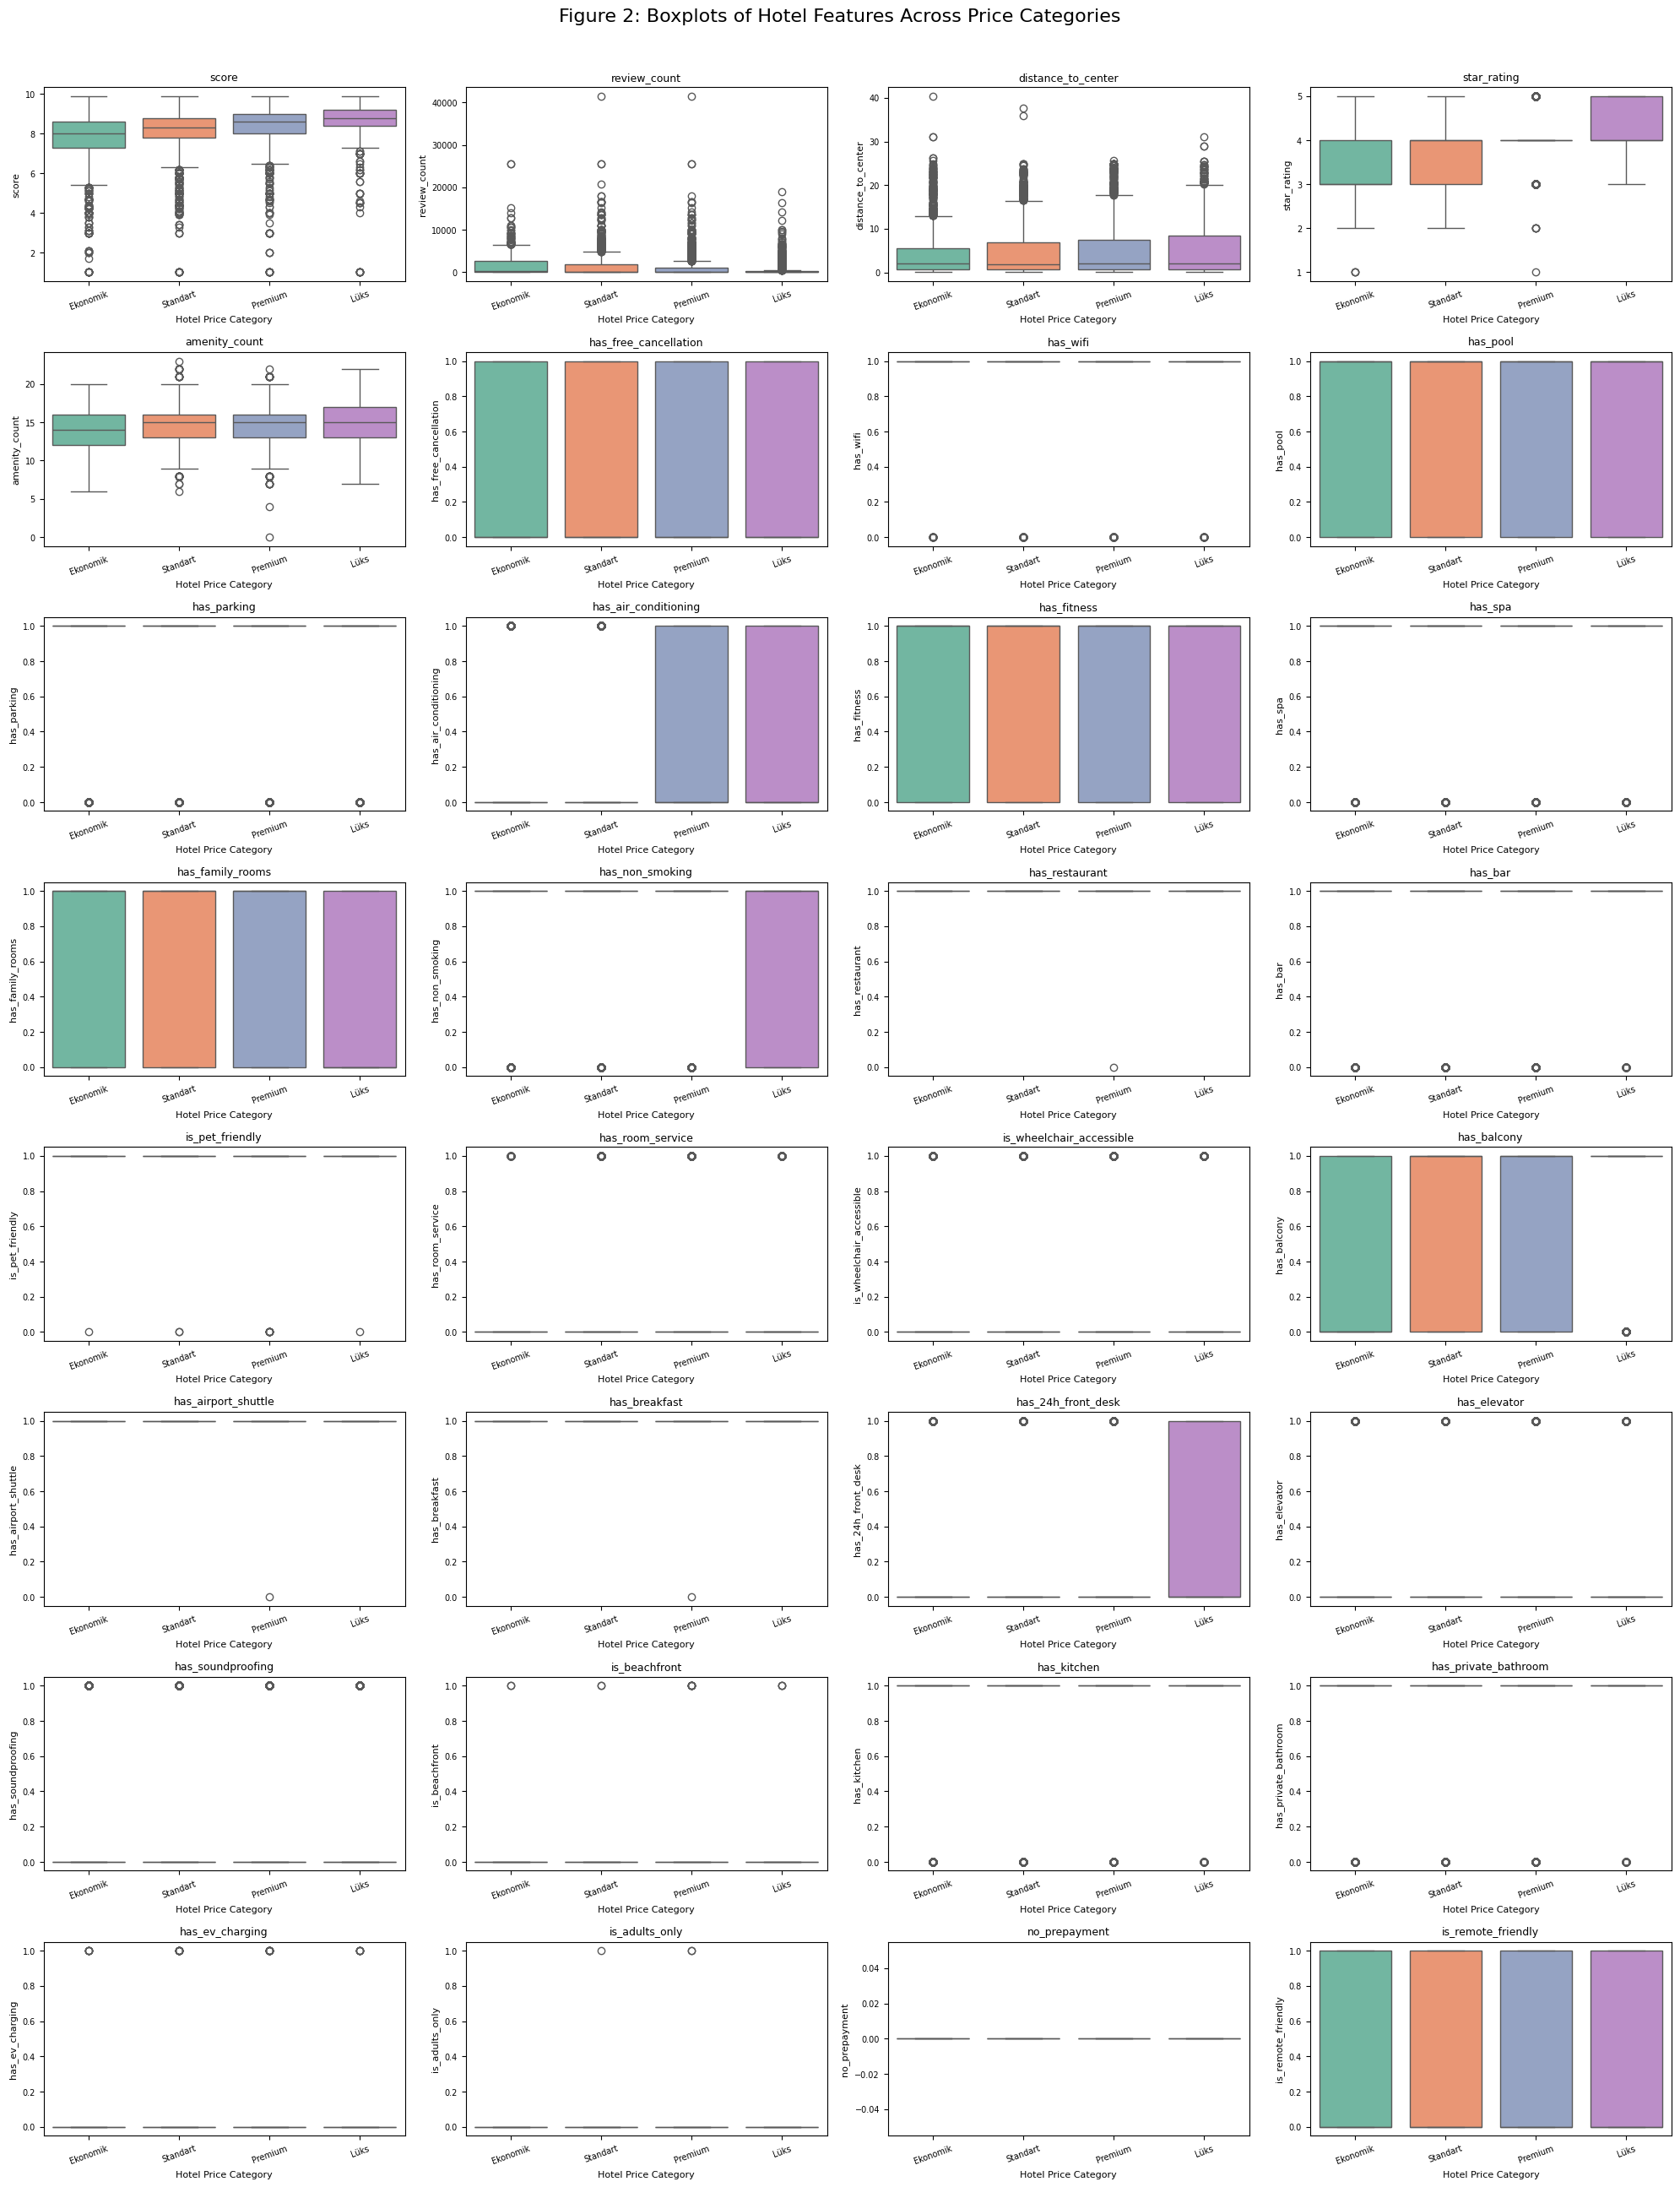

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import math
import os

os.makedirs("figures", exist_ok=True)

df = pd.read_csv("Iskandinavya_Otel_Verisi.csv", engine="python", on_bad_lines="skip")

def clean_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value)

    if "Fiyat Gizli" in value:
        return np.nan

    value = re.sub(r"[^0-9]", "", value)

    if value == "":
        return np.nan

    return int(value)

df["price_tl"] = df["price"].apply(clean_price)

def price_category(price):
    if pd.isna(price):
        return np.nan
    elif price <= 25000:
        return "Ekonomik"
    elif price <= 40000:
        return "Standart"
    elif price <= 70000:
        return "Premium"
    else:
        return "Lüks"

df["price_category"] = df["price_tl"].apply(price_category)

train_df = df.dropna(subset=["price_tl", "price_category"]).copy()

# Toplam hizmet sayısı
amenity_columns = [
    col for col in train_df.columns
    if col.startswith("has_") or col.startswith("is_") or col.startswith("no_")
]

train_df["amenity_count"] = train_df[amenity_columns].sum(axis=1)

# Figure 2 için kullanılacak özellikler
boxplot_features = [
    "score",
    "review_count",
    "distance_to_center",
    "star_rating",
    "amenity_count",
    "has_free_cancellation",
    "has_wifi",
    "has_pool",
    "has_parking",
    "has_air_conditioning",
    "has_fitness",
    "has_spa",
    "has_family_rooms",
    "has_non_smoking",
    "has_restaurant",
    "has_bar",
    "is_pet_friendly",
    "has_room_service",
    "is_wheelchair_accessible",
    "has_balcony",
    "has_airport_shuttle",
    "has_breakfast",
    "has_24h_front_desk",
    "has_elevator",
    "has_soundproofing",
    "is_beachfront",
    "has_kitchen",
    "has_private_bathroom",
    "has_ev_charging",
    "is_adults_only",
    "no_prepayment",
    "is_remote_friendly"
]

boxplot_features = [col for col in boxplot_features if col in train_df.columns]

order = ["Ekonomik", "Standart", "Premium", "Lüks"]

# Sınıflara özel renkler
class_palette = {
    "Ekonomik": "#66c2a5",   # yeşil
    "Standart": "#fc8d62",   # turuncu
    "Premium": "#8da0cb",    # mavi
    "Lüks": "#c084d2"        # mor
}

n_cols = 4
n_rows = math.ceil(len(boxplot_features) / n_cols)

plt.figure(figsize=(20, n_rows * 3.2))

for i, feature in enumerate(boxplot_features, 1):
    plt.subplot(n_rows, n_cols, i)

    sns.boxplot(
        data=train_df,
        x="price_category",
        y=feature,
        order=order,
        palette=class_palette
    )

    plt.title(feature, fontsize=9)
    plt.xlabel("Hotel Price Category", fontsize=8)
    plt.ylabel(feature, fontsize=8)
    plt.xticks(rotation=20, fontsize=7)
    plt.yticks(fontsize=7)

plt.suptitle(
    "Figure 2: Boxplots of Hotel Features Across Price Categories",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.savefig("figures/figure2_boxplots_hotel_features_colored.png", dpi=300, bbox_inches="tight")
plt.show()

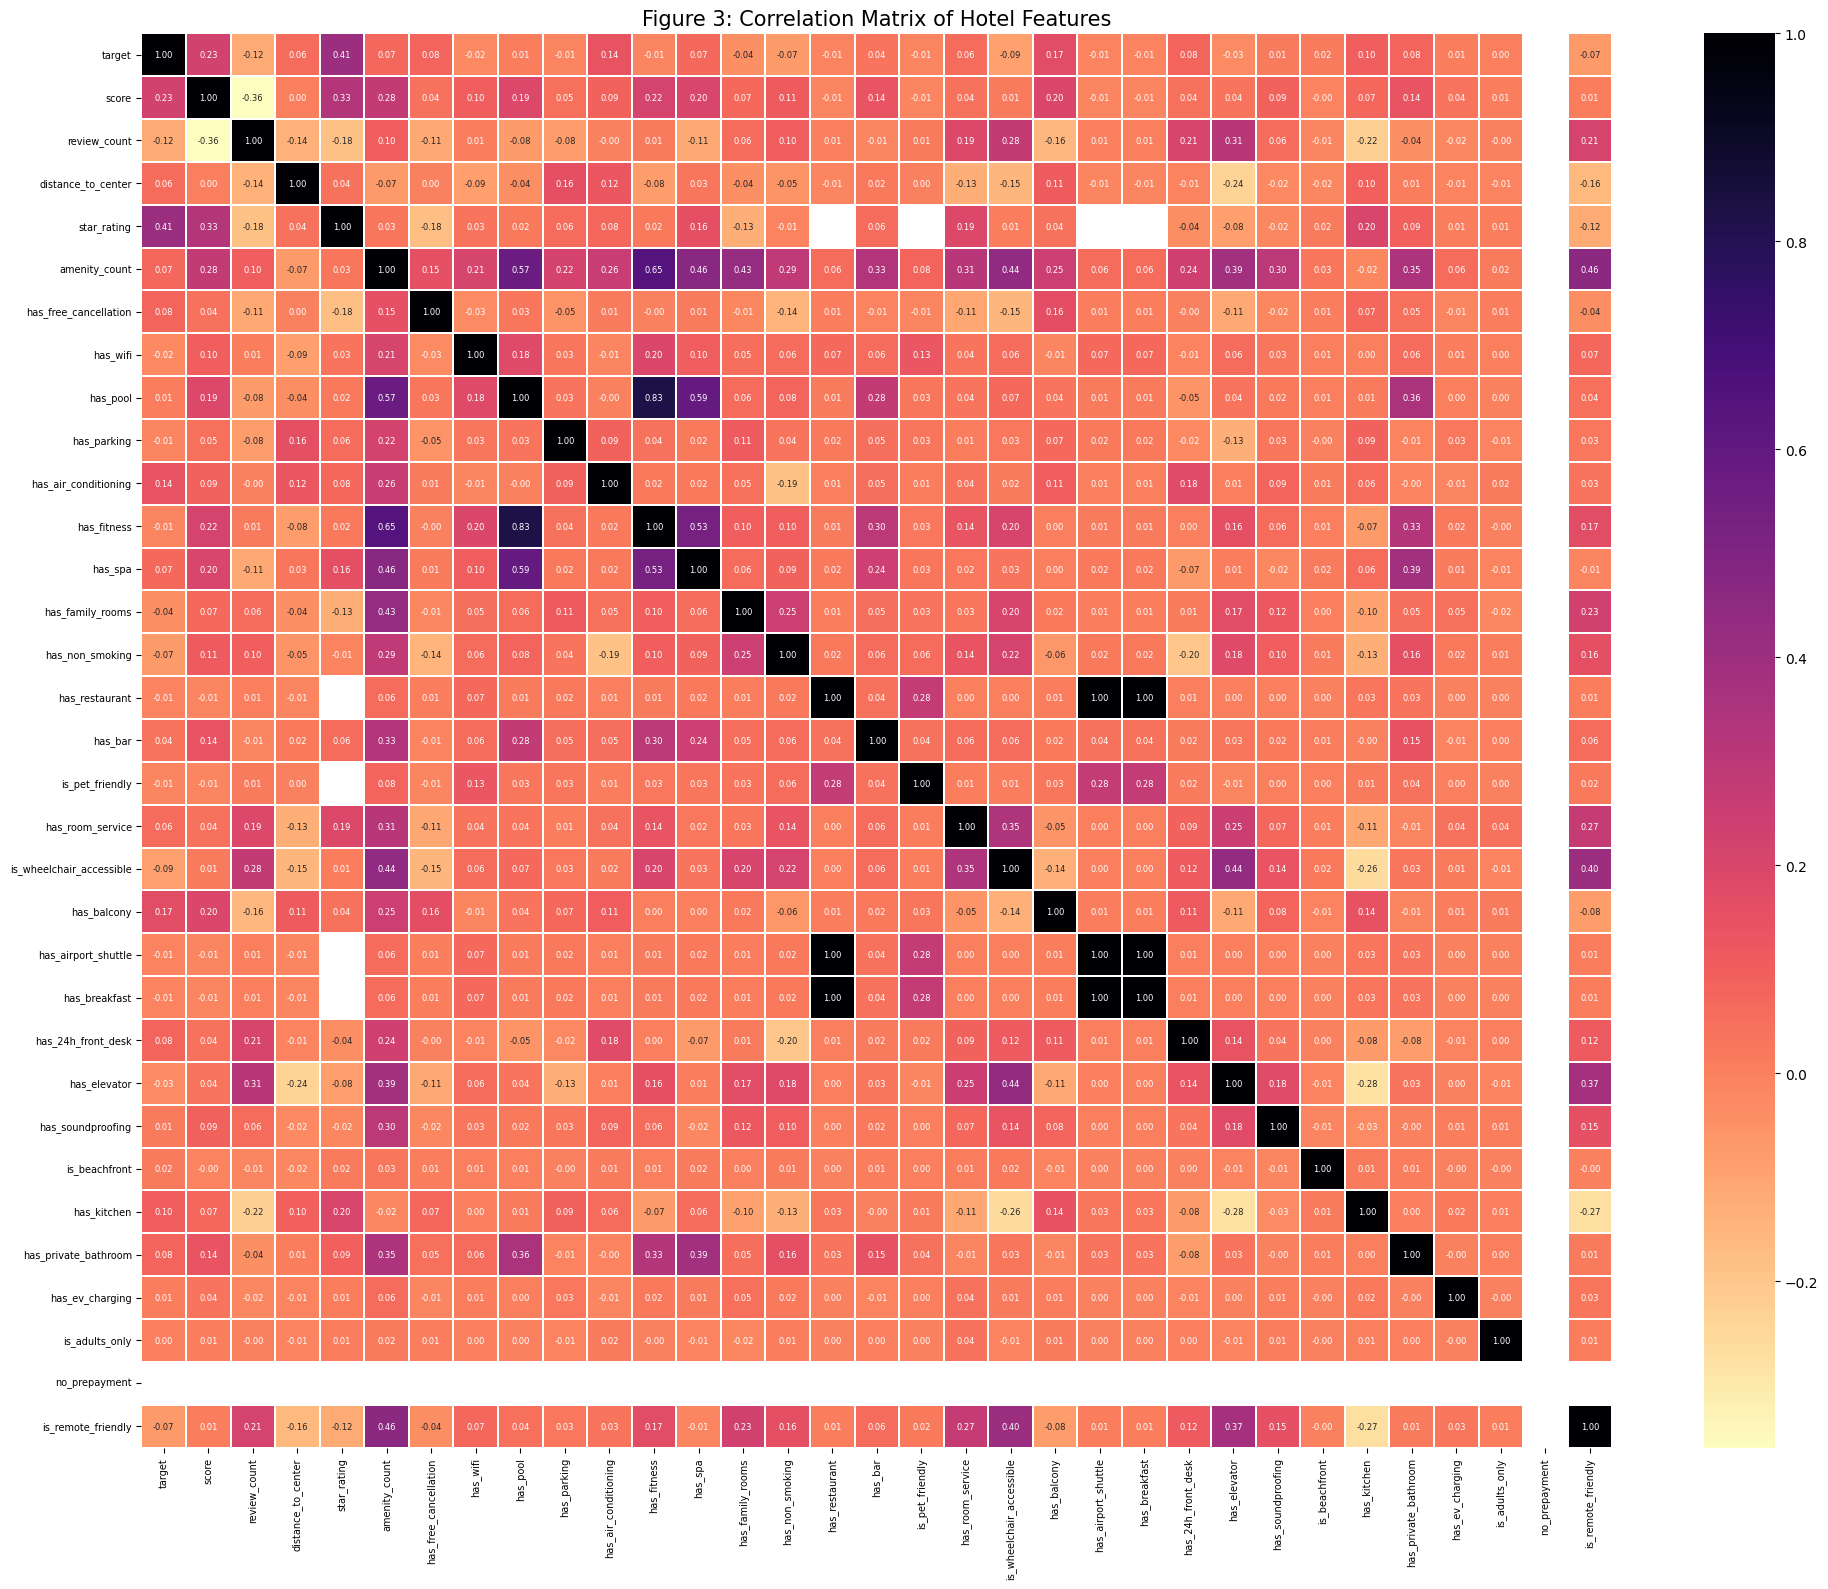

In [10]:
# ==============================
# FIGURE 3: CORRELATION MATRIX
# ==============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

os.makedirs("figures", exist_ok=True)

# CSV dosyasını oku
df = pd.read_csv("Iskandinavya_Otel_Verisi.csv", engine="python", on_bad_lines="skip")

# Fiyat temizleme
def clean_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value)

    if "Fiyat Gizli" in value:
        return np.nan

    value = re.sub(r"[^0-9]", "", value)

    if value == "":
        return np.nan

    return int(value)

df["price_tl"] = df["price"].apply(clean_price)

# Fiyat kategorisi oluşturma
def price_category(price):
    if pd.isna(price):
        return np.nan
    elif price <= 25000:
        return "Ekonomik"
    elif price <= 40000:
        return "Standart"
    elif price <= 70000:
        return "Premium"
    else:
        return "Lüks"

df["price_category"] = df["price_tl"].apply(price_category)

# Label encoding
label_map = {
    "Ekonomik": 0,
    "Standart": 1,
    "Premium": 2,
    "Lüks": 3
}

df["target"] = df["price_category"].map(label_map)

# Fiyatı gizli olmayan kayıtları al
train_df = df.dropna(subset=["price_tl", "price_category"]).copy()

# Hizmet sütunlarını seç
amenity_columns = [
    col for col in train_df.columns
    if col.startswith("has_") or col.startswith("is_") or col.startswith("no_")
]

# Toplam hizmet sayısı
train_df["amenity_count"] = train_df[amenity_columns].sum(axis=1)

# Korelasyon için kullanılacak sütunlar
corr_features = [
    "target",
    "score",
    "review_count",
    "distance_to_center",
    "star_rating",
    "amenity_count"
] + amenity_columns

# Dataset içinde mevcut olan sütunları al
corr_features = [col for col in corr_features if col in train_df.columns]

# Korelasyon matrisi
corr_matrix = train_df[corr_features].corr()

# Figure 3 çizimi
plt.figure(figsize=(20, 16))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="magma_r",
    linewidths=0.3,
    cbar=True,
    annot_kws={"size": 6}
)

plt.title("Figure 3: Correlation Matrix of Hotel Features", fontsize=15)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()
plt.savefig("figures/figure3_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

Figure 4 için çizilecek feature sayısı: 33
['score', 'review_count', 'distance_to_center', 'star_rating', 'amenity_count', 'has_free_cancellation', 'has_wifi', 'has_pool', 'has_parking', 'has_air_conditioning', 'has_fitness', 'has_spa', 'has_family_rooms', 'has_non_smoking', 'has_restaurant', 'has_bar', 'is_pet_friendly', 'has_room_service', 'is_wheelchair_accessible', 'has_balcony', 'has_airport_shuttle', 'has_breakfast', 'has_24h_front_desk', 'has_elevator', 'has_soundproofing', 'is_beachfront', 'has_kitchen', 'has_private_bathroom', 'has_ev_charging', 'is_adults_only', 'no_prepayment', 'is_remote_friendly', 'price_tl']


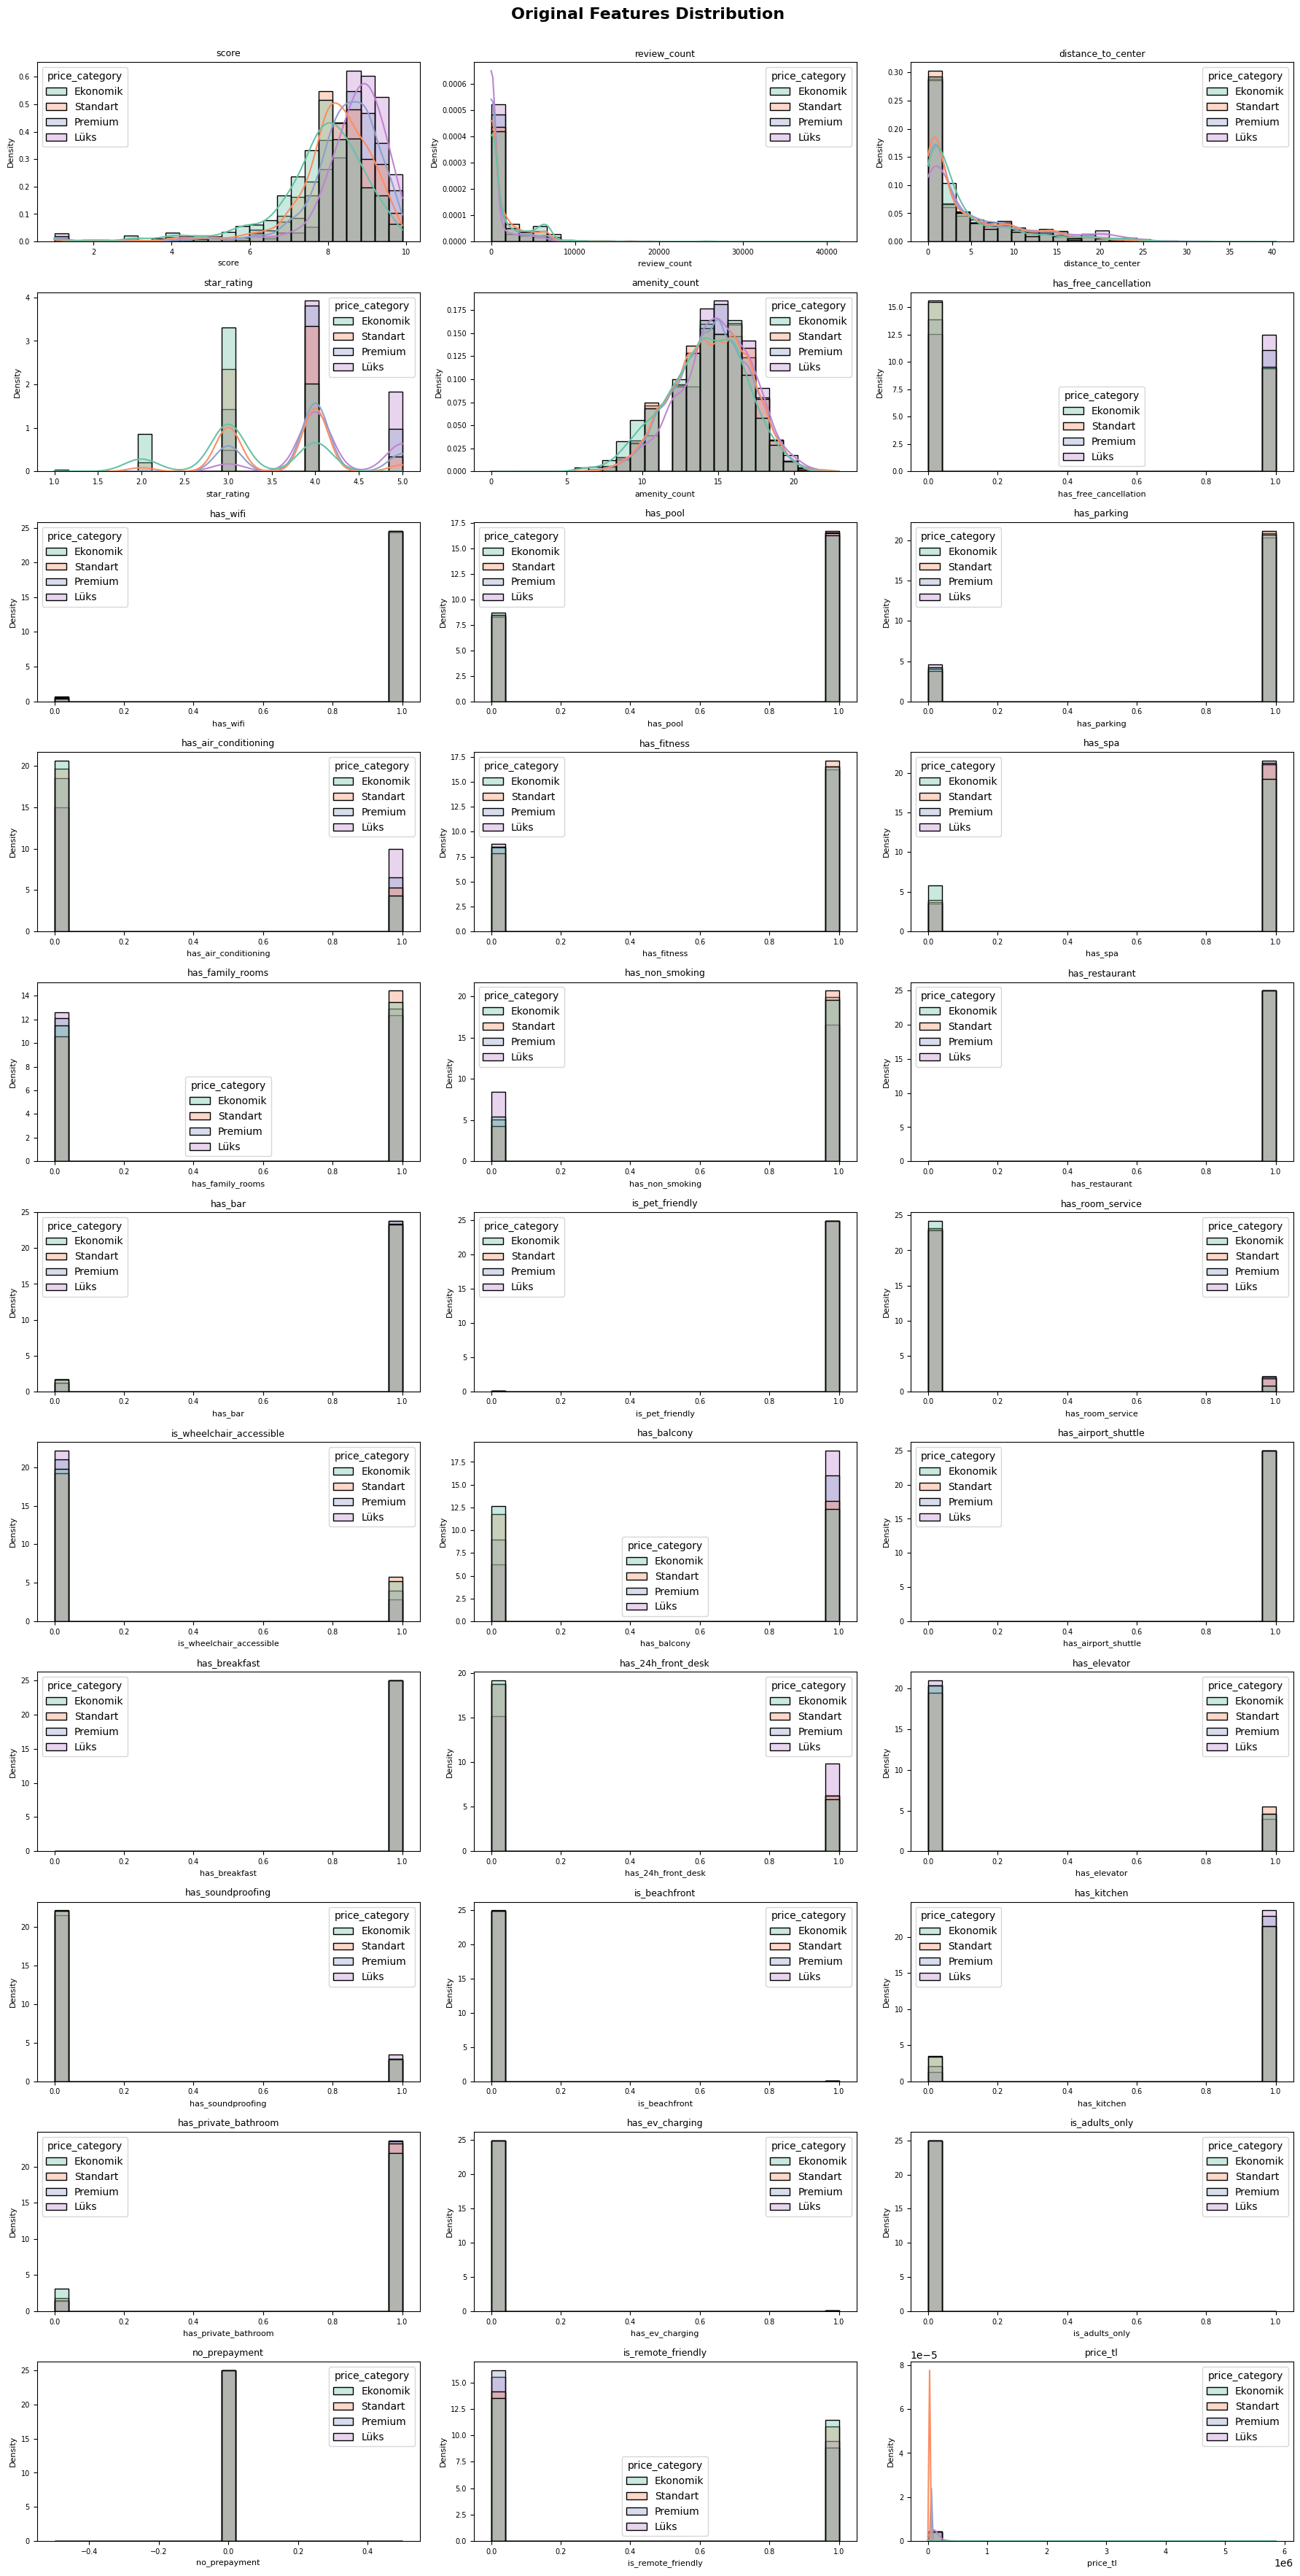

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import math
import os

os.makedirs("figures", exist_ok=True)

# ==============================
# 1. DATA LOADING
# ==============================

df = pd.read_csv("Iskandinavya_Otel_Verisi.csv", engine="python", on_bad_lines="skip")

# ==============================
# 2. PRICE CLEANING
# ==============================

def clean_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value)

    if "Fiyat Gizli" in value:
        return np.nan

    value = re.sub(r"[^0-9]", "", value)

    if value == "":
        return np.nan

    return int(value)

df["price_tl"] = df["price"].apply(clean_price)

# ==============================
# 3. PRICE CATEGORY CREATION
# ==============================

def price_category(price):
    if pd.isna(price):
        return np.nan
    elif price <= 25000:
        return "Ekonomik"
    elif price <= 40000:
        return "Standart"
    elif price <= 70000:
        return "Premium"
    else:
        return "Lüks"

df["price_category"] = df["price_tl"].apply(price_category)

# Fiyatı bilinen kayıtlar
train_df = df.dropna(subset=["price_tl", "price_category"]).copy()

# ==============================
# 4. NUMERIC CONVERSION
# ==============================

possible_numeric_columns = [
    "score",
    "review_count",
    "distance_to_center",
    "star_rating"
]

for col in possible_numeric_columns:
    if col in train_df.columns:
        train_df[col] = pd.to_numeric(train_df[col], errors="coerce")

# ==============================
# 5. AMENITY / BINARY FEATURES
# ==============================

amenity_columns = [
    col for col in train_df.columns
    if col.startswith("has_") or col.startswith("is_") or col.startswith("no_")
]

for col in amenity_columns:
    train_df[col] = pd.to_numeric(train_df[col], errors="coerce").fillna(0)

# Toplam hizmet sayısı
train_df["amenity_count"] = train_df[amenity_columns].sum(axis=1)

# ==============================
# 6. ALL FEATURES FOR FIGURE 4
# ==============================

distribution_features = []

# Ana sayısal değişkenler
main_numeric_features = [
    "score",
    "review_count",
    "distance_to_center",
    "star_rating",
    "amenity_count"
]

for col in main_numeric_features:
    if col in train_df.columns:
        distribution_features.append(col)

# Binary hizmet özellikleri
distribution_features += amenity_columns

# İstersen fiyat dağılımını da ekliyoruz
# Bu hedef değişkenin kaynağı olduğu için model input'u değildir,
# sadece veri dağılımını göstermek için kullanılır.
if "price_tl" in train_df.columns:
    distribution_features.append("price_tl")

# Tekrar eden varsa sil
distribution_features = list(dict.fromkeys(distribution_features))

print("Figure 4 için çizilecek feature sayısı:", len(distribution_features))
print(distribution_features)

# ==============================
# 7. CLASS COLORS
# ==============================

order = ["Ekonomik", "Standart", "Premium", "Lüks"]

class_palette = {
    "Ekonomik": "#66c2a5",
    "Standart": "#fc8d62",
    "Premium": "#8da0cb",
    "Lüks": "#c084d2"
}

# ==============================
# 8. PLOT ORIGINAL FEATURE DISTRIBUTIONS
# ==============================

n_cols = 3
n_rows = math.ceil(len(distribution_features) / n_cols)

plt.figure(figsize=(18, n_rows * 3.2))

for i, feature in enumerate(distribution_features, 1):
    plt.subplot(n_rows, n_cols, i)

    # Determine if KDE should be applied
    plot_kde = True
    # If the feature is a binary amenity column, disable KDE to prevent LinAlgError
    if feature in amenity_columns:
        plot_kde = False

    sns.histplot(
        data=train_df,
        x=feature,
        hue="price_category",
        hue_order=order,
        palette=class_palette,
        kde=plot_kde, # Use conditional plot_kde
        stat="density",
        common_norm=False,
        bins=25,
        alpha=0.35
    )

    plt.title(feature, fontsize=9)
    plt.xlabel(feature, fontsize=8)
    plt.ylabel("Density", fontsize=8)
    plt.xticks(fontsize=7)
    plt.yticks(fontsize=7)

plt.suptitle(
    "Original Features Distribution",
    fontsize=16,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()
plt.savefig(
    "figures/figure4_original_features_distribution_all.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Normalize edilen özellik sayısı: 32


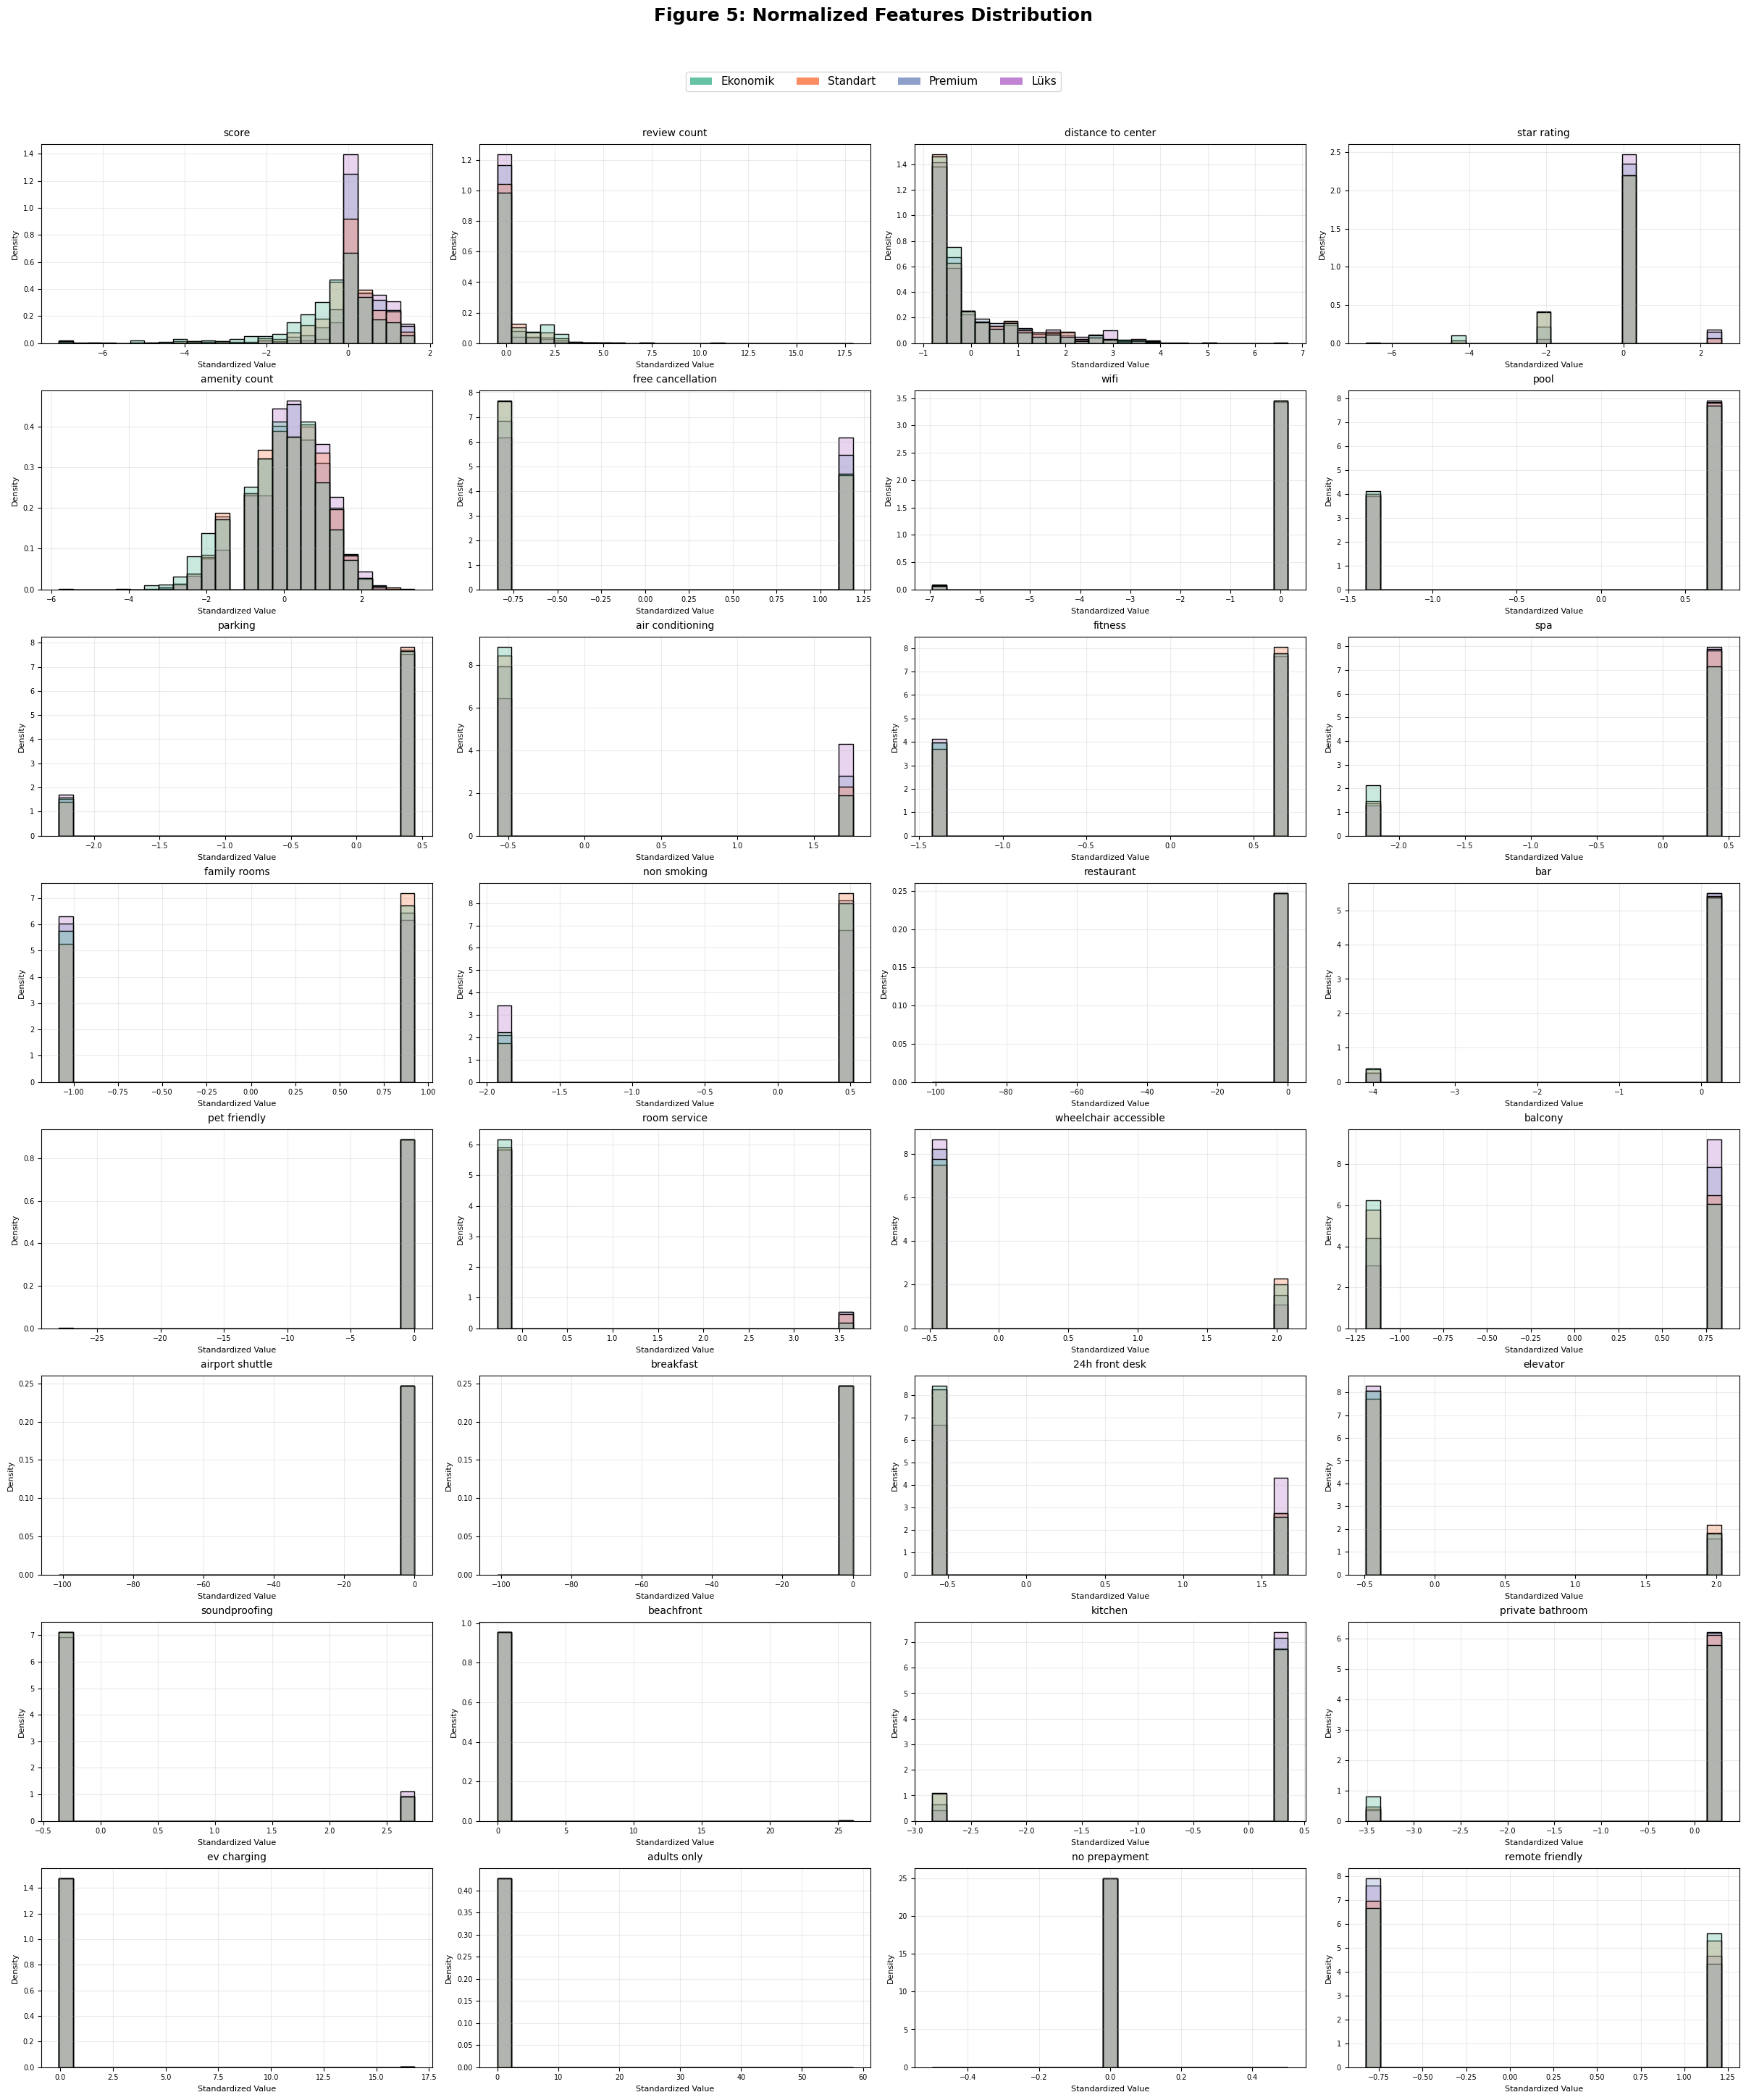

Figure 5 kaydedildi: figures/figure5_normalized_features_distribution.png


In [12]:
# ==============================
# FIGURE 5: NORMALIZED FEATURES DISTRIBUTION
# After missing value imputation and standardization
# ==============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import math
import os
from matplotlib.patches import Patch

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

os.makedirs("figures", exist_ok=True)

# ==============================
# 1. DATA LOADING
# ==============================

df = pd.read_csv("Iskandinavya_Otel_Verisi.csv", engine="python", on_bad_lines="skip")

# ==============================
# 2. PRICE CLEANING
# ==============================

def clean_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value)

    if "Fiyat Gizli" in value:
        return np.nan

    value = re.sub(r"[^0-9]", "", value)

    if value == "":
        return np.nan

    return int(value)

df["price_tl"] = df["price"].apply(clean_price)

# ==============================
# 3. PRICE CATEGORY CREATION
# ==============================

def price_category(price):
    if pd.isna(price):
        return np.nan
    elif price <= 25000:
        return "Ekonomik"
    elif price <= 40000:
        return "Standart"
    elif price <= 70000:
        return "Premium"
    else:
        return "Lüks"

df["price_category"] = df["price_tl"].apply(price_category)

train_df = df.dropna(subset=["price_tl", "price_category"]).copy()

# ==============================
# 4. NUMERIC AND BINARY FEATURES
# ==============================

main_numeric_features = [
    "score",
    "review_count",
    "distance_to_center",
    "star_rating"
]

for col in main_numeric_features:
    if col in train_df.columns:
        train_df[col] = pd.to_numeric(train_df[col], errors="coerce")

amenity_columns = [
    col for col in train_df.columns
    if col.startswith("has_") or col.startswith("is_") or col.startswith("no_")
]

for col in amenity_columns:
    train_df[col] = pd.to_numeric(train_df[col], errors="coerce").fillna(0).astype(int)

train_df["amenity_count"] = train_df[amenity_columns].sum(axis=1)

# Normalize edilecek özellikler
features_to_scale = main_numeric_features + ["amenity_count"] + amenity_columns
features_to_scale = [col for col in features_to_scale if col in train_df.columns]

# ==============================
# 5. MISSING VALUE IMPUTATION + STANDARDIZATION
# ==============================

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_imputed = imputer.fit_transform(train_df[features_to_scale])
X_scaled = scaler.fit_transform(X_imputed)

scaled_df = pd.DataFrame(X_scaled, columns=features_to_scale)
scaled_df["price_category"] = train_df["price_category"].values

print("Normalize edilen özellik sayısı:", len(features_to_scale))

# ==============================
# 6. COLORS
# ==============================

order = ["Ekonomik", "Standart", "Premium", "Lüks"]

class_palette = {
    "Ekonomik": "#66c2a5",
    "Standart": "#fc8d62",
    "Premium": "#8da0cb",
    "Lüks": "#c084d2"
}

def short_title(name, max_len=28):
    name = name.replace("has_", "")
    name = name.replace("is_", "")
    name = name.replace("no_", "no ")
    name = name.replace("_", " ")

    if len(name) > max_len:
        name = name[:max_len - 3] + "..."

    return name

# ==============================
# 7. PLOT NORMALIZED DISTRIBUTIONS
# ==============================

n_cols = 4
n_rows = math.ceil(len(features_to_scale) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(24, n_rows * 3.4),
    constrained_layout=True
)

axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, features_to_scale):

    temp = scaled_df[[feature, "price_category"]].dropna().copy()

    sns.histplot(
        data=temp,
        x=feature,
        hue="price_category",
        hue_order=order,
        palette=class_palette,
        stat="density",
        common_norm=False,
        bins=25,
        alpha=0.35,
        ax=ax,
        legend=False
    )

    ax.set_title(short_title(feature), fontsize=10, pad=8)
    ax.set_xlabel("Standardized Value", fontsize=8)
    ax.set_ylabel("Density", fontsize=8)
    ax.tick_params(axis="x", labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(True, alpha=0.25)

# Boş subplotları kapat
for j in range(len(features_to_scale), len(axes)):
    axes[j].axis("off")

# Tek ortak legend
legend_handles = [
    Patch(facecolor=class_palette[label], label=label)
    for label in order
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=4,
    fontsize=11,
    frameon=True,
    bbox_to_anchor=(0.5, 1.03)
)

fig.suptitle(
    "Figure 5: Normalized Features Distribution",
    fontsize=18,
    fontweight="bold",
    y=1.06
)

plt.savefig(
    "figures/figure5_normalized_features_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 5 kaydedildi: figures/figure5_normalized_features_distribution.png")

In [13]:
# ==============================
# MODEL DATA PREPARATION
# ==============================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# train_df zaten önceki adımlardan geliyor
df_model = train_df.copy()

# Target tekrar net olsun
label_map = {
    "Ekonomik": 0,
    "Standart": 1,
    "Premium": 2,
    "Lüks": 3
}

df_model["target"] = df_model["price_category"].map(label_map)

# Güvenli sayısal dönüştürme
def extract_number(x):
    if pd.isna(x):
        return np.nan
    x = str(x).replace(",", ".")
    match = re.search(r"\d+(\.\d+)?", x)
    if match:
        return float(match.group())
    return np.nan

numeric_features = [
    "score",
    "review_count",
    "distance_to_center",
    "star_rating",
    "amenity_count"
]

for col in numeric_features:
    if col in df_model.columns:
        df_model[col] = df_model[col].apply(extract_number)

categorical_features = [
    "country",
    "city",
    "season"
]

binary_features = amenity_columns

features = categorical_features + numeric_features + binary_features

X = df_model[features]
y = df_model["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print(y.value_counts())

X shape: (10214, 35)
y shape: (10214,)
target
1    3730
2    3330
0    1845
3    1309
Name: count, dtype: int64


In [14]:
# ==============================
# TRAIN TEST SPLIT + PREPROCESSING
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

binary_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("bin", binary_transformer, binary_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape)
print("X_test_processed:", X_test_processed.shape)

X_train_processed: (8171, 111)
X_test_processed: (2043, 111)


In [15]:
# ==============================
# EVALUATION FUNCTION
# ==============================

import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = []

def evaluate_model(model_name, model):
    start_train = time.time()
    model.fit(X_train_processed, y_train)
    training_time = time.time() - start_train

    start_pred = time.time()
    y_pred = model.predict(X_test_processed)
    prediction_time = time.time() - start_pred

    runtime_one_record = prediction_time / len(X_test_processed)

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_processed)
        auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
    else:
        auc = np.nan

    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

    results.append({
        "Model": model_name,
        "Accuracy": round(acc, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-score": round(f1, 4),
        "AUC": round(auc, 4) if not np.isnan(auc) else np.nan,
        "Training Time (sec)": round(training_time, 4),
        "Runtime for One Record (sec)": round(runtime_one_record, 8)
    })

    print(f"\n{model_name}")
    print("Accuracy:", round(acc, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("AUC:", round(auc, 4) if not np.isnan(auc) else "N/A")
    print("Training Time:", round(training_time, 4), "sec")
    print("Runtime for One Record:", round(runtime_one_record, 8), "sec")

    return model

In [16]:
# ==============================
# 5 MACHINE LEARNING MODELS
# ==============================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

ml_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        C=1.0,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        metric="minkowski",
        p=2
    ),

    "Support Vector Machine": SVC(
        C=10,
        kernel="rbf",
        gamma="scale",
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_ml_models = {}

for name, model in ml_models.items():
    trained_ml_models[name] = evaluate_model(name, model)


Logistic Regression
Accuracy: 0.4258
Precision: 0.4316
Recall: 0.4863
F1-score: 0.4297
AUC: 0.728
Training Time: 5.3076 sec
Runtime for One Record: 9.4e-07 sec

K-Nearest Neighbors
Accuracy: 0.5247
Precision: 0.5192
Recall: 0.5007
F1-score: 0.5085
AUC: 0.7702
Training Time: 0.0049 sec
Runtime for One Record: 0.0001261 sec

Support Vector Machine
Accuracy: 0.5463
Precision: 0.5358
Recall: 0.5761
F1-score: 0.5472
AUC: 0.8068
Training Time: 51.5229 sec
Runtime for One Record: 0.00097868 sec

Random Forest
Accuracy: 0.6006
Precision: 0.6123
Recall: 0.585
F1-score: 0.5966
AUC: 0.8366
Training Time: 3.4953 sec
Runtime for One Record: 9.024e-05 sec

Gradient Boosting
Accuracy: 0.5218
Precision: 0.5679
Recall: 0.4798
F1-score: 0.5042
AUC: 0.7713
Training Time: 21.3979 sec
Runtime for One Record: 1.231e-05 sec


In [17]:
# ==============================
# MODEL COMPARISON TABLE
# ==============================

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="F1-score", ascending=False)

results_df

,Model,Accuracy,Precision,Recall,F1-score,AUC,Training Time (sec),Runtime for One Record (sec)
3,Random Forest,0.6006,0.6123,0.5850,0.5966,0.8366,3.4953,9.024000e-05
2,Support Vector Machine,0.5463,0.5358,0.5761,0.5472,0.8068,51.5229,9.786800e-04
1,K-Nearest Neighbors,0.5247,0.5192,0.5007,0.5085,0.7702,0.0049,1.261000e-04
4,Gradient Boosting,0.5218,0.5679,0.4798,0.5042,0.7713,21.3979,1.231000e-05
0,Logistic Regression,0.4258,0.4316,0.4863,0.4297,0.7280,5.3076,9.400000e-07


In [18]:
os.makedirs("tables", exist_ok=True)
results_df.to_csv("tables/table7_model_comparison_results.csv", index=False)

In [19]:
# ==============================
# DEEP LEARNING IMPORTS
# ==============================

# Eğer TensorFlow yüklü değilse önce bunu çalıştır:
# !pip install tensorflow

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

import numpy as np
import pandas as pd
import time

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [20]:
# ==============================
# PREPARE DATA FOR DEEP LEARNING
# ==============================

# Eğer sparse matrix geldiyse dense'e çevir
if hasattr(X_train_processed, "toarray"):
    X_train_dl = X_train_processed.toarray()
    X_test_dl = X_test_processed.toarray()
else:
    X_train_dl = X_train_processed
    X_test_dl = X_test_processed

X_train_dl = np.array(X_train_dl).astype("float32")
X_test_dl = np.array(X_test_dl).astype("float32")

y_train_array = np.array(y_train).astype("int32")
y_test_array = np.array(y_test).astype("int32")

num_classes = len(np.unique(y_train_array))
input_dim = X_train_dl.shape[1]

y_train_dl = to_categorical(y_train_array, num_classes=num_classes)
y_test_dl = to_categorical(y_test_array, num_classes=num_classes)

print("Input dimension:", input_dim)
print("Number of classes:", num_classes)
print("X_train_dl:", X_train_dl.shape)
print("X_test_dl:", X_test_dl.shape)

Input dimension: 111
Number of classes: 4
X_train_dl: (8171, 111)
X_test_dl: (2043, 111)


In [21]:
# ==============================
# DEEP LEARNING EVALUATION FUNCTION
# ==============================

# Eğer önceki ML kısmından results yoksa oluştur
try:
    results
except NameError:
    results = []

try:
    trained_models
except NameError:
    trained_models = {}

dl_histories = {}

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

def evaluate_deep_model(model_name, model, epochs=50, batch_size=32):
    start_train = time.time()

    history = model.fit(
        X_train_dl,
        y_train_dl,
        validation_split=0.20,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.time() - start_train

    start_pred = time.time()
    y_proba = model.predict(X_test_dl, verbose=0)
    prediction_time = time.time() - start_pred

    runtime_one_record = prediction_time / len(X_test_dl)

    y_pred = np.argmax(y_proba, axis=1)

    acc = accuracy_score(y_test_array, y_pred)
    precision = precision_score(y_test_array, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test_array, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test_array, y_pred, average="macro", zero_division=0)
    auc = roc_auc_score(y_test_array, y_proba, multi_class="ovr", average="macro")

    results.append({
        "Model": model_name,
        "Accuracy": round(acc * 100, 2),
        "Precision": round(precision * 100, 2),
        "Recall": round(recall * 100, 2),
        "F1-score": round(f1 * 100, 2),
        "AUC": round(auc, 4),
        "Training Time (sec)": round(training_time, 4),
        "Runtime for One Record (sec)": round(runtime_one_record, 8)
    })

    trained_models[model_name] = model
    dl_histories[model_name] = history

    print(f"\nModel: {model_name}")
    print("Accuracy:", round(acc * 100, 2))
    print("Precision:", round(precision * 100, 2))
    print("Recall:", round(recall * 100, 2))
    print("F1-score:", round(f1 * 100, 2))
    print("AUC:", round(auc, 4))
    print("Training Time:", round(training_time, 4), "sec")
    print("Runtime for One Record:", round(runtime_one_record, 8), "sec")

    return model, history

In [22]:
# ==============================
# DL MODEL 1: BASIC ANN
# ==============================

tf.keras.backend.clear_session()

ann_basic = Sequential([
    Dense(64, activation="relu", input_shape=(input_dim,)),
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

ann_basic.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

ann_basic, history_basic = evaluate_deep_model(
    "DL Basic ANN",
    ann_basic,
    epochs=50,
    batch_size=32
)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.4160 - loss: 1.2303 - val_accuracy: 0.4508 - val_loss: 1.1747
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4731 - loss: 1.1300 - val_accuracy: 0.4740 - val_loss: 1.1309
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5132 - loss: 1.0830 - val_accuracy: 0.4875 - val_loss: 1.1037
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5301 - loss: 1.0458 - val_accuracy: 0.5070 - val_loss: 1.0905
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5450 - loss: 1.0224 - val_accuracy: 0.5040 - val_loss: 1.0762
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5508 - loss: 0.9996 - val_accuracy: 0.5089 - val_loss: 1.0651
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5629 - loss: 0.9780 - val_accuracy: 0.5217 - val_loss: 1.0581
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5805 - loss: 0.9583 - val_accuracy: 0.5187 - val_

In [23]:
# ==============================
# DL MODEL 2: ANN WITH DROPOUT
# ==============================

tf.keras.backend.clear_session()

ann_dropout = Sequential([
    Dense(128, activation="relu", input_shape=(input_dim,)),
    Dropout(0.30),

    Dense(64, activation="relu"),
    Dropout(0.20),

    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

ann_dropout.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

ann_dropout, history_dropout = evaluate_deep_model(
    "DL ANN with Dropout",
    ann_dropout,
    epochs=70,
    batch_size=32
)

Epoch 1/70


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3932 - loss: 1.2531 - val_accuracy: 0.4324 - val_loss: 1.1801
Epoch 2/70
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4396 - loss: 1.1701 - val_accuracy: 0.4593 - val_loss: 1.1407
Epoch 3/70
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4685 - loss: 1.1296 - val_accuracy: 0.4771 - val_loss: 1.1169
Epoch 4/70
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4870 - loss: 1.0976 - val_accuracy: 0.4869 - val_loss: 1.0956
Epoch 5/70
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5008 - loss: 1.0693 - val_accuracy: 0.5058 - val_loss: 1.0836
Epoch 6/70
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5207 - loss: 1.0488 - val_accuracy: 0.5180 - val_loss: 1.0670
Epoch 7/70
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5239 - loss: 1.0305 - val_accuracy: 0.5083 - val_loss: 1.0576
Epoch 8/70
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5461 - loss: 1.0033 - val_accuracy: 0.5144 - val_

In [24]:
# ==============================
# DL MODEL 3: DEEP ANN + BATCH NORMALIZATION
# ==============================

tf.keras.backend.clear_session()

deep_ann_batchnorm = Sequential([
    Dense(256, activation="relu", input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.30),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.20),

    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

deep_ann_batchnorm.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

deep_ann_batchnorm, history_deep = evaluate_deep_model(
    "DL Deep ANN + BatchNorm",
    deep_ann_batchnorm,
    epochs=100,
    batch_size=32
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3730 - loss: 1.3454 - val_accuracy: 0.3859 - val_loss: 1.2468
Epoch 2/100
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4227 - loss: 1.2193 - val_accuracy: 0.4593 - val_loss: 1.1503
Epoch 3/100
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4595 - loss: 1.1683 - val_accuracy: 0.4954 - val_loss: 1.1079
Epoch 4/100
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4709 - loss: 1.1349 - val_accuracy: 0.5021 - val_loss: 1.0865
Epoch 5/100
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4870 - loss: 1.1057 - val_accuracy: 0.5083 - val_loss: 1.0818
Epoch 6/100
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4937 - loss: 1.0942 - val_accuracy: 0.4991 - val_loss: 1.0756
Epoch 7/100
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5092 - loss: 1.0716 - val_accuracy: 0.5015 - val_loss: 1.0711
Epoch 8/100
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5156 - loss: 1.0505 - val_accuracy: 0.5064

In [25]:
# ==============================
# UPDATE TABLE 7 WITH DEEP LEARNING RESULTS
# ==============================

table7 = pd.DataFrame(results)

table7 = table7[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUC",
        "Training Time (sec)",
        "Runtime for One Record (sec)"
    ]
]

table7 = table7.sort_values(by="F1-score", ascending=False)

table7

,Model,Accuracy,Precision,Recall,F1-score,AUC,Training Time (sec),Runtime for One Record (sec)
6,DL ANN with Dropout,52.5200,52.4900,50.5600,51.2700,0.7887,21.3407,1.222000e-04
5,DL Basic ANN,52.1300,53.7900,47.3400,48.9800,0.7807,12.9397,1.219300e-04
7,DL Deep ANN + BatchNorm,42.1400,45.0800,33.8200,33.2100,0.6887,12.4797,1.769500e-04
3,Random Forest,0.6006,0.6123,0.5850,0.5966,0.8366,3.4953,9.024000e-05
2,Support Vector Machine,0.5463,0.5358,0.5761,0.5472,0.8068,51.5229,9.786800e-04
1,K-Nearest Neighbors,0.5247,0.5192,0.5007,0.5085,0.7702,0.0049,1.261000e-04
4,Gradient Boosting,0.5218,0.5679,0.4798,0.5042,0.7713,21.3979,1.231000e-05
0,Logistic Regression,0.4258,0.4316,0.4863,0.4297,0.7280,5.3076,9.400000e-07


In [26]:
table7.to_csv("tables/table7_model_comparison_with_deep_learning.csv", index=False)

print("Table 7 kaydedildi: tables/table7_model_comparison_with_deep_learning.csv")

Table 7 kaydedildi: tables/table7_model_comparison_with_deep_learning.csv


In [27]:
import pandas as pd
import os

os.makedirs("tables", exist_ok=True)

table3 = pd.DataFrame([
    {
        "Sr No": 1,
        "Model": "Logistic Regression",
        "Tuning Parameters": "max_iter=1000, C=1.0, solver='lbfgs', class_weight='balanced', random_state=42"
    },
    {
        "Sr No": 2,
        "Model": "K-Nearest Neighbors",
        "Tuning Parameters": "n_neighbors=5, weights='distance', metric='minkowski', p=2"
    },
    {
        "Sr No": 3,
        "Model": "Support Vector Machine",
        "Tuning Parameters": "C=10, kernel='rbf', gamma='scale', probability=True, class_weight='balanced', random_state=42"
    },
    {
        "Sr No": 4,
        "Model": "Random Forest",
        "Tuning Parameters": "n_estimators=300, max_depth=20, min_samples_split=2, min_samples_leaf=1, class_weight='balanced', random_state=42"
    },
    {
        "Sr No": 5,
        "Model": "Gradient Boosting",
        "Tuning Parameters": "n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42"
    },
    {
        "Sr No": 6,
        "Model": "DL Basic ANN",
        "Tuning Parameters": "Dense layers: 64-32, activation='relu', optimizer='adam', loss='categorical_crossentropy', epochs=50, batch_size=32"
    },
    {
        "Sr No": 7,
        "Model": "DL ANN with Dropout",
        "Tuning Parameters": "Dense layers: 128-64-32, Dropout=0.30/0.20, activation='relu', optimizer='adam', epochs=70, batch_size=32"
    },
    {
        "Sr No": 8,
        "Model": "DL Deep ANN + BatchNorm",
        "Tuning Parameters": "Dense layers: 256-128-64-32, BatchNormalization, Dropout=0.30/0.25/0.20, Adam learning_rate=0.001, epochs=100"
    }
])

table3

,Sr No,Model,Tuning Parameters
0,1,Logistic Regression,"max_iter=1000, C=1.0, solver='lbfgs', class_we..."
1,2,K-Nearest Neighbors,"n_neighbors=5, weights='distance', metric='min..."
2,3,Support Vector Machine,"C=10, kernel='rbf', gamma='scale', probability..."
3,4,Random Forest,"n_estimators=300, max_depth=20, min_samples_sp..."
4,5,Gradient Boosting,"n_estimators=200, learning_rate=0.05, max_dept..."
5,6,DL Basic ANN,"Dense layers: 64-32, activation='relu', optimi..."
6,7,DL ANN with Dropout,"Dense layers: 128-64-32, Dropout=0.30/0.20, ac..."
7,8,DL Deep ANN + BatchNorm,"Dense layers: 256-128-64-32, BatchNormalizatio..."


In [28]:
table3.to_csv("tables/table3_model_parameters.csv", index=False)

print("Table 3 kaydedildi: tables/table3_model_parameters.csv")

Table 3 kaydedildi: tables/table3_model_parameters.csv


In [29]:
# Eğer imbalanced-learn yüklü değilse önce bunu çalıştır:
# !pip install imbalanced-learn

from imblearn.over_sampling import SMOTE

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.base import clone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

os.makedirs("figures", exist_ok=True)

In [30]:
# ==============================
# SELECT BEST MACHINE LEARNING MODEL
# ==============================

ml_model_names = [
    "Logistic Regression",
    "K-Nearest Neighbors",
    "Support Vector Machine",
    "Random Forest",
    "Gradient Boosting"
]

ml_results = table7[table7["Model"].isin(ml_model_names)].copy()

best_ml_name = ml_results.sort_values(by="F1-score", ascending=False).iloc[0]["Model"]

print("Best ML Model:", best_ml_name)

best_ml_model = trained_ml_models[best_ml_name]


Best ML Model: Random Forest


<Figure size 700x600 with 0 Axes>

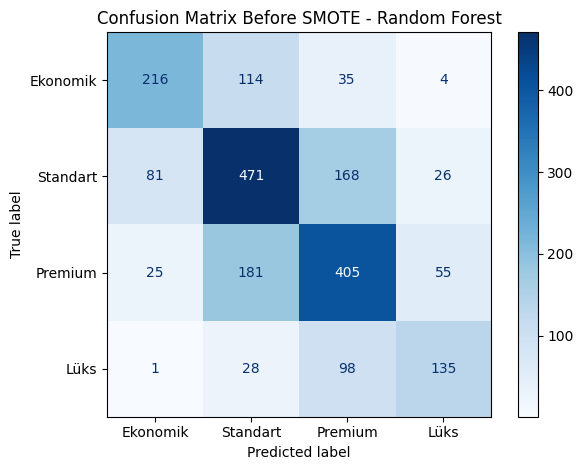

In [31]:
# ==============================
# CONFUSION MATRIX BEFORE SMOTE
# ==============================

class_names = ["Ekonomik", "Standart", "Premium", "Lüks"]

y_pred_before = best_ml_model.predict(X_test_processed)

cm_before = confusion_matrix(y_test, y_pred_before)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_before,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix Before SMOTE - {best_ml_name}")
plt.tight_layout()

plt.savefig(
    "figures/confusion_matrix_before_smote.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# ==============================
# APPLY SMOTE TO TRAINING DATA
# ==============================

# Eğer sparse matrix varsa dense'e çevir
if hasattr(X_train_processed, "toarray"):
    X_train_smote_input = X_train_processed.toarray()
else:
    X_train_smote_input = X_train_processed

if hasattr(X_test_processed, "toarray"):
    X_test_smote_input = X_test_processed.toarray()
else:
    X_test_smote_input = X_test_processed

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_smote_input,
    y_train
)

print("Before SMOTE class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nAfter SMOTE class distribution:")
print(pd.Series(y_train_smote).value_counts().sort_index())

Before SMOTE class distribution:
target
0    1476
1    2984
2    2664
3    1047
Name: count, dtype: int64

After SMOTE class distribution:
target
0    2984
1    2984
2    2984
3    2984
Name: count, dtype: int64


In [33]:
# ==============================
# TRAIN BEST MODEL AFTER SMOTE
# ==============================

best_ml_model_smote = clone(best_ml_model)

best_ml_model_smote.fit(X_train_smote, y_train_smote)

y_pred_after = best_ml_model_smote.predict(X_test_smote_input)

cm_after = confusion_matrix(y_test, y_pred_after)

print("SMOTE sonrası model eğitildi.")

SMOTE sonrası model eğitildi.


<Figure size 700x600 with 0 Axes>

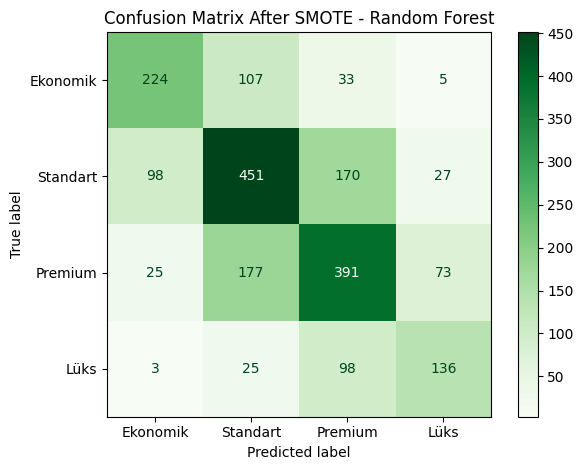

In [34]:
# ==============================
# CONFUSION MATRIX AFTER SMOTE
# ==============================

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_after,
    display_labels=class_names
)

disp.plot(cmap="Greens", values_format="d")
plt.title(f"Confusion Matrix After SMOTE - {best_ml_name}")
plt.tight_layout()

plt.savefig(
    "figures/confusion_matrix_after_smote.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

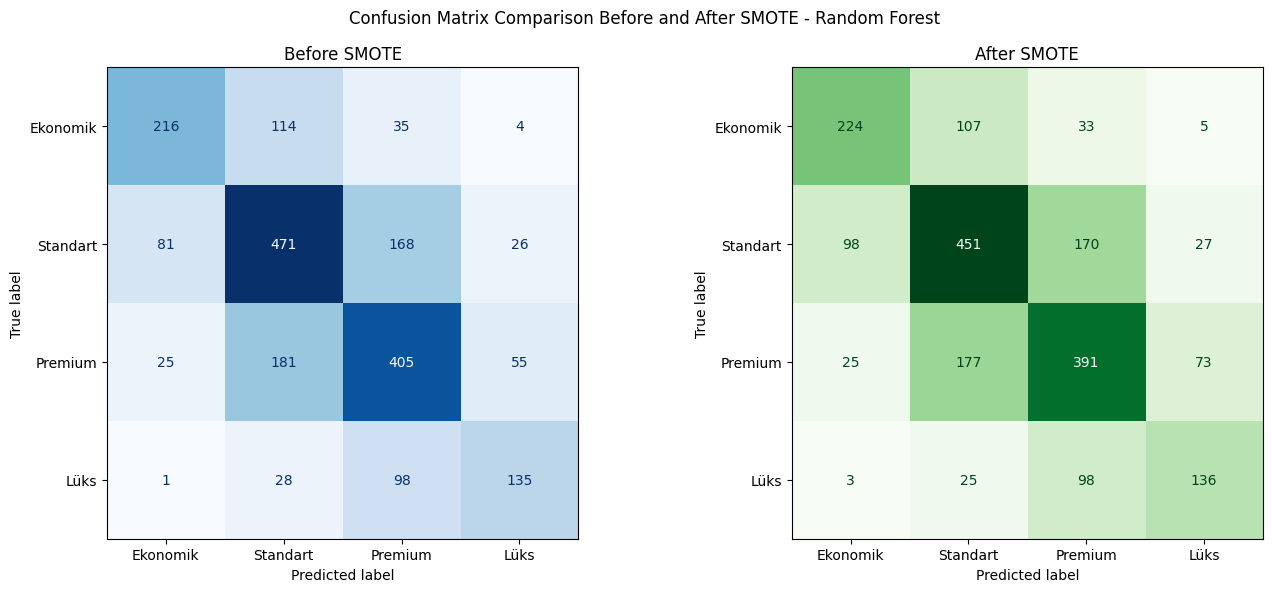

In [35]:
# ==============================
# BEFORE VS AFTER SMOTE
# ==============================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_before,
    display_labels=class_names
)

disp1.plot(
    cmap="Blues",
    values_format="d",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Before SMOTE")

disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_after,
    display_labels=class_names
)

disp2.plot(
    cmap="Greens",
    values_format="d",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("After SMOTE")

plt.suptitle(f"Confusion Matrix Comparison Before and After SMOTE - {best_ml_name}")
plt.tight_layout()

plt.savefig(
    "figures/figure_smote_confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# ==============================
# TABLE 4: GENERAL CONFUSION MATRIX STRUCTURE
# ==============================

import pandas as pd
import os

os.makedirs("tables", exist_ok=True)

table4 = pd.DataFrame({
    "": ["Actual: Ekonomik", "Actual: Standart", "Actual: Premium", "Actual: Lüks"],
    "Predicted: Ekonomik": ["TP1", "FN12", "FN13", "FN14"],
    "Predicted: Standart": ["FP21", "TP2", "FN23", "FN24"],
    "Predicted: Premium": ["FP31", "FP32", "TP3", "FN34"],
    "Predicted: Lüks": ["FP41", "FP42", "FP43", "TP4"]
})

table4

,,Predicted: Ekonomik,Predicted: Standart,Predicted: Premium,Predicted: Lüks
0,Actual: Ekonomik,TP1,FP21,FP31,FP41
1,Actual: Standart,FN12,TP2,FP32,FP42
2,Actual: Premium,FN13,FN23,TP3,FP43
3,Actual: Lüks,FN14,FN24,FN34,TP4


In [37]:
table4.to_csv("tables/table4_confusion_matrix_structure.csv", index=False)

print("Table 4 kaydedildi: tables/table4_confusion_matrix_structure.csv")

Table 4 kaydedildi: tables/table4_confusion_matrix_structure.csv


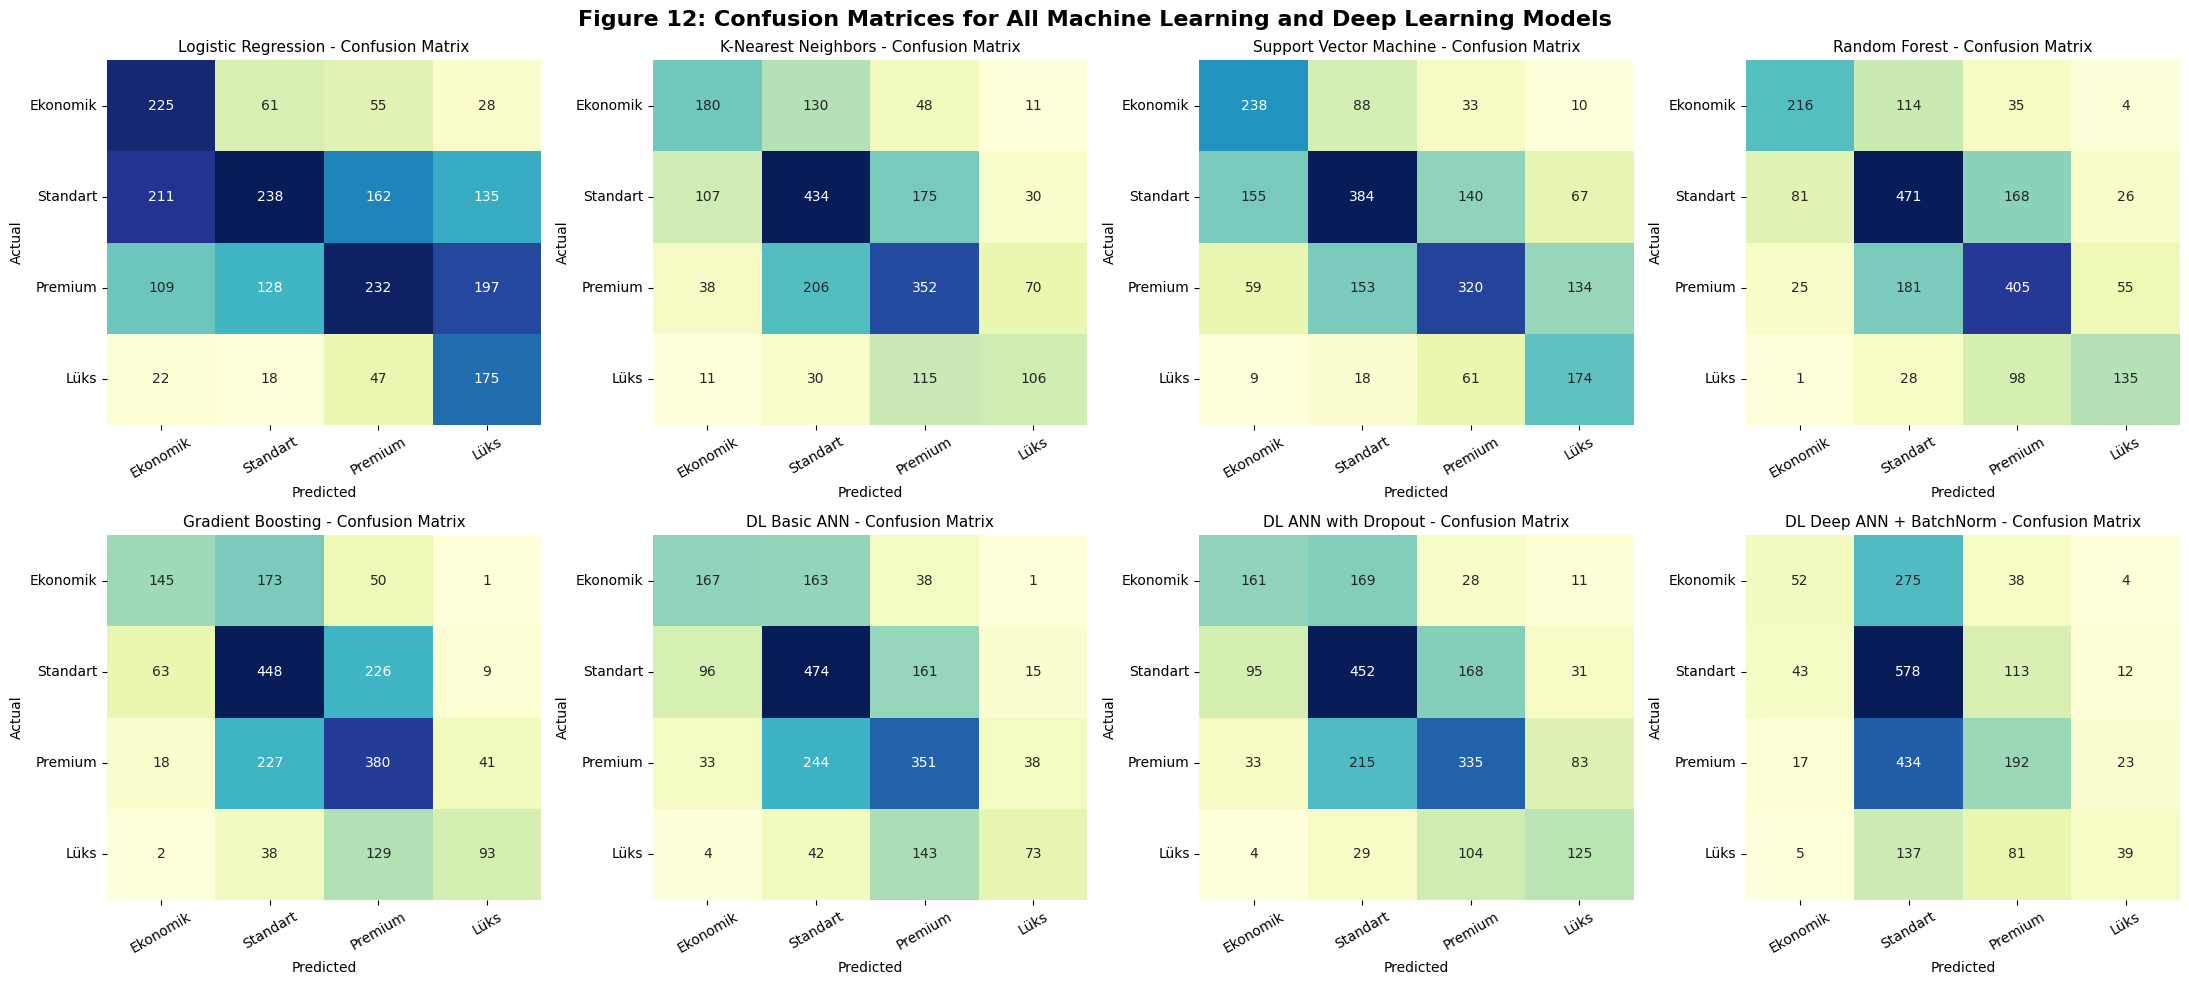

Figure 12 kaydedildi: figures/figure12_confusion_matrices_all_models.png


In [38]:
# ==============================
# FIGURE 12: CONFUSION MATRICES FOR ALL MODELS
# ==============================

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

os.makedirs("figures", exist_ok=True)

class_names = ["Ekonomik", "Standart", "Premium", "Lüks"]

model_order = [
    "Logistic Regression",
    "K-Nearest Neighbors",
    "Support Vector Machine",
    "Random Forest",
    "Gradient Boosting",
    "DL Basic ANN",
    "DL ANN with Dropout",
    "DL Deep ANN + BatchNorm"
]

# Combine all trained models into one dictionary for easy access
all_trained_models = {}
if 'trained_ml_models' in globals():
    all_trained_models.update(trained_ml_models)
if 'trained_models' in globals(): # This holds DL models
    all_trained_models.update(trained_models)

# Eğer Deep Learning için X_test_dl yoksa oluştur
if "X_test_dl" not in globals():
    if hasattr(X_test_processed, "toarray"):
        X_test_dl = X_test_processed.toarray().astype("float32")
    else:
        X_test_dl = np.array(X_test_processed).astype("float32")

# y_test array
y_test_array = np.array(y_test).astype(int)

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

for i, model_name in enumerate(model_order):

    model = all_trained_models[model_name]

    # Deep Learning modelleri için
    if model_name.startswith("DL"):
        y_proba = model.predict(X_test_dl, verbose=0)
        y_pred = np.argmax(y_proba, axis=1)

    # Machine Learning modelleri için
    else:
        y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test_array, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i],
        cbar=False
    )

    axes[i].set_title(f"{model_name} - Confusion Matrix", fontsize=11)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].tick_params(axis="y", rotation=0)

plt.suptitle(
    "Figure 12: Confusion Matrices for All Machine Learning and Deep Learning Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "figures/figure12_confusion_matrices_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 12 kaydedildi: figures/figure12_confusion_matrices_all_models.png")

In [39]:
# ==============================
# TABLE 7: MODEL COMPARISON - FIXED FORMAT
# Accuracy, Precision, Recall, F1-score and AUC as percentage
# ==============================

import pandas as pd
import os

os.makedirs("tables", exist_ok=True)

def to_percent(value):
    if 0 <= value <= 1:
        return value * 100
    return value

table7 = pd.DataFrame(results)

table7 = table7[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUC",
        "Training Time (sec)",
        "Runtime for One Record (sec)"
    ]
]

metrics_to_percent = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "AUC"
]

for metric in metrics_to_percent:
    table7[metric] = table7[metric].apply(to_percent).round(2)

table7["Training Time (sec)"] = table7["Training Time (sec)"].round(4)
table7["Runtime for One Record (sec)"] = table7["Runtime for One Record (sec)"].round(8)

table7 = table7.sort_values(by="F1-score", ascending=False)

table7

,Model,Accuracy,Precision,Recall,F1-score,AUC,Training Time (sec),Runtime for One Record (sec)
3,Random Forest,60.06,61.23,58.50,59.66,83.66,3.4953,9.024000e-05
2,Support Vector Machine,54.63,53.58,57.61,54.72,80.68,51.5229,9.786800e-04
6,DL ANN with Dropout,52.52,52.49,50.56,51.27,78.87,21.3407,1.222000e-04
1,K-Nearest Neighbors,52.47,51.92,50.07,50.85,77.02,0.0049,1.261000e-04
4,Gradient Boosting,52.18,56.79,47.98,50.42,77.13,21.3979,1.231000e-05
5,DL Basic ANN,52.13,53.79,47.34,48.98,78.07,12.9397,1.219300e-04
0,Logistic Regression,42.58,43.16,48.63,42.97,72.80,5.3076,9.400000e-07
7,DL Deep ANN + BatchNorm,42.14,45.08,33.82,33.21,68.87,12.4797,1.769500e-04


In [40]:
table7.to_csv("tables/table7_model_comparison.csv", index=False)

print("Table 7 kaydedildi: tables/table7_model_comparison.csv")

Table 7 kaydedildi: tables/table7_model_comparison.csv


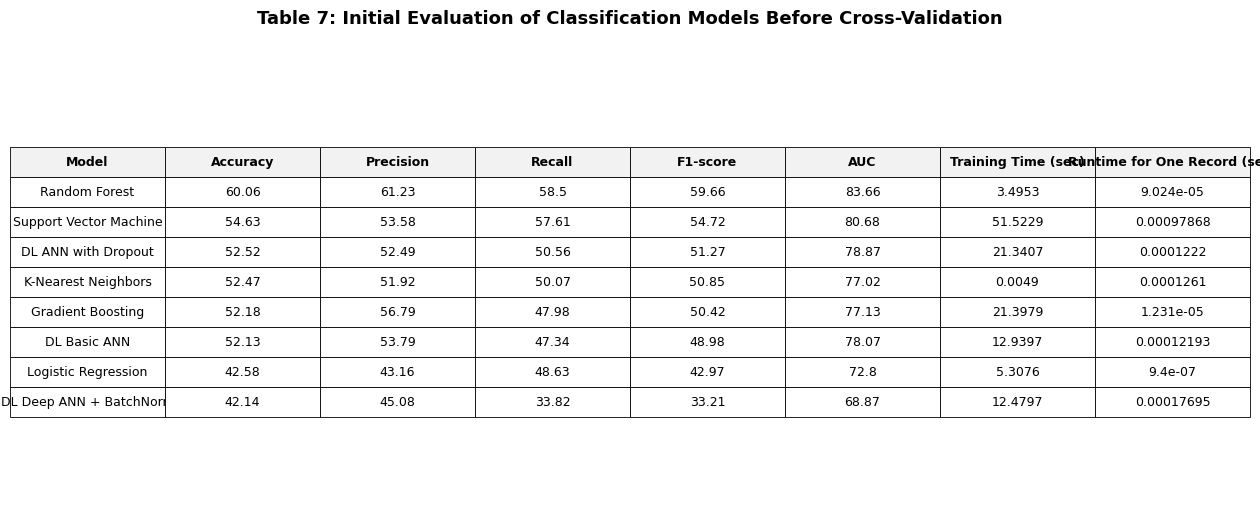

Table 7 görsel olarak kaydedildi: tables/table7_model_comparison.png


In [41]:
# ==============================
# SAVE TABLE 7 AS IMAGE
# ==============================

import matplotlib.pyplot as plt

table7_display = table7.copy()

fig, ax = plt.subplots(figsize=(16, 6))
ax.axis("off")

table = ax.table(
    cellText=table7_display.values,
    colLabels=table7_display.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

for key, cell in table.get_celld().items():
    cell.set_linewidth(0.6)
    if key[0] == 0:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#f2f2f2")

plt.title(
    "Table 7: Initial Evaluation of Classification Models Before Cross-Validation",
    fontsize=13,
    fontweight="bold",
    pad=20
)

plt.savefig("tables/table7_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Table 7 görsel olarak kaydedildi: tables/table7_model_comparison.png")

In [42]:
# ==============================
# ROC CURVE PREPARATION
# ==============================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import os

os.makedirs("figures", exist_ok=True)

class_names = ["Ekonomik", "Standart", "Premium", "Lüks"]
classes = [0, 1, 2, 3]

y_test_array = np.array(y_test).astype(int)

y_test_bin = label_binarize(y_test_array, classes=classes)

# Deep learning test verisi yoksa oluştur
if "X_test_dl" not in globals():
    if hasattr(X_test_processed, "toarray"):
        X_test_dl = X_test_processed.toarray().astype("float32")
    else:
        X_test_dl = np.array(X_test_processed).astype("float32")

model_order = [
    "Logistic Regression",
    "K-Nearest Neighbors",
    "Support Vector Machine",
    "Random Forest",
    "Gradient Boosting",
    "DL Basic ANN",
    "DL ANN with Dropout",
    "DL Deep ANN + BatchNorm"
]

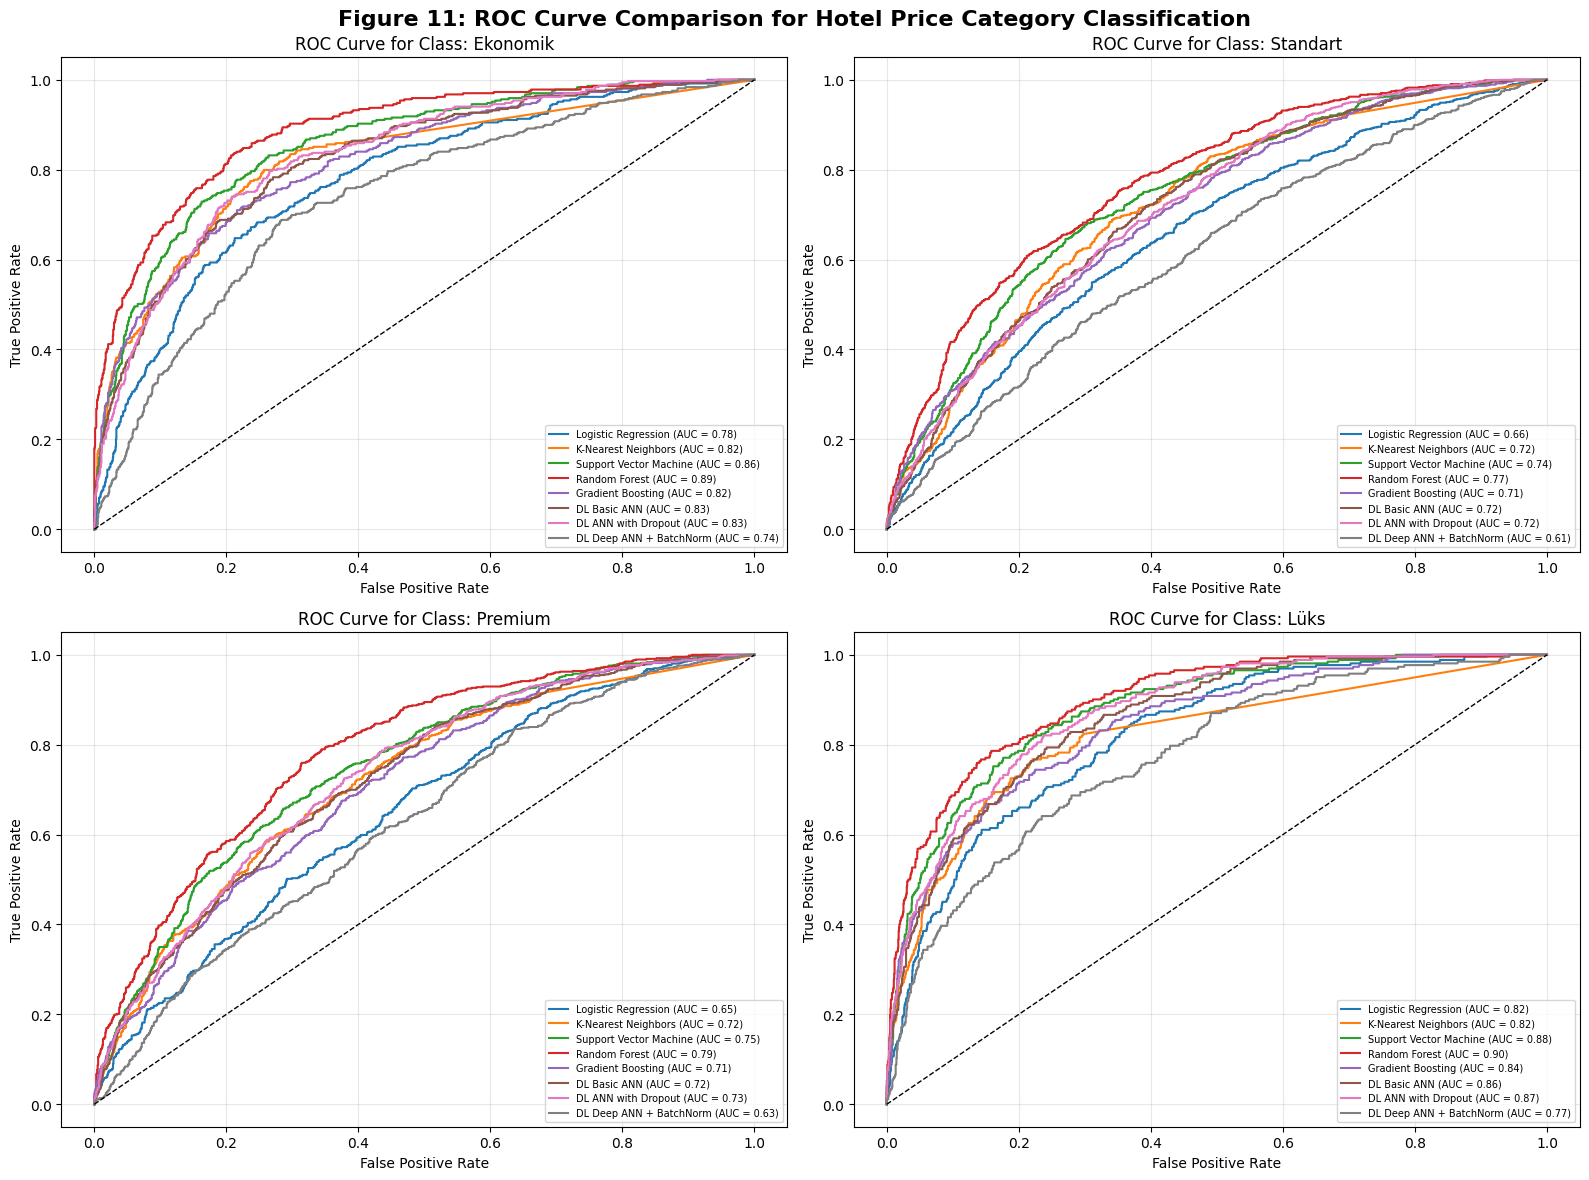

Figure 11 kaydedildi: figures/figure11_roc_curve_comparison.png


In [43]:
# ==============================
# FIGURE 11: ROC CURVES
# ==============================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for class_index, class_name in enumerate(class_names):

    ax = axes[class_index]

    for model_name in model_order:

        model = all_trained_models[model_name]

        if model_name.startswith("DL"):
            y_score = model.predict(X_test_dl, verbose=0)
        else:
            y_score = model.predict_proba(X_test_processed)

        fpr, tpr, _ = roc_curve(
            y_test_bin[:, class_index],
            y_score[:, class_index]
        )

        roc_auc = auc(fpr, tpr)

        ax.plot(
            fpr,
            tpr,
            linewidth=1.5,
            label=f"{model_name} (AUC = {roc_auc:.2f})"
        )

    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"ROC Curve for Class: {class_name}", fontsize=12)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=7, loc="lower right")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Figure 11: ROC Curve Comparison for Hotel Price Category Classification",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "figures/figure11_roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 11 kaydedildi: figures/figure11_roc_curve_comparison.png")

In [44]:
# ==============================
# TRAINING TIME AND RUNTIME TABLE
# ==============================

import pandas as pd
import os

os.makedirs("tables", exist_ok=True)

runtime_table = table7[
    [
        "Model",
        "Training Time (sec)",
        "Runtime for One Record (sec)"
    ]
].copy()

runtime_table = runtime_table.sort_values(
    by="Training Time (sec)",
    ascending=True
)

runtime_table

,Model,Training Time (sec),Runtime for One Record (sec)
1,K-Nearest Neighbors,0.0049,1.261000e-04
3,Random Forest,3.4953,9.024000e-05
0,Logistic Regression,5.3076,9.400000e-07
7,DL Deep ANN + BatchNorm,12.4797,1.769500e-04
5,DL Basic ANN,12.9397,1.219300e-04
6,DL ANN with Dropout,21.3407,1.222000e-04
4,Gradient Boosting,21.3979,1.231000e-05
2,Support Vector Machine,51.5229,9.786800e-04


In [45]:
runtime_table.to_csv("tables/training_time_runtime_table.csv", index=False)

print("Training time/runtime tablosu kaydedildi: tables/training_time_runtime_table.csv")

Training time/runtime tablosu kaydedildi: tables/training_time_runtime_table.csv


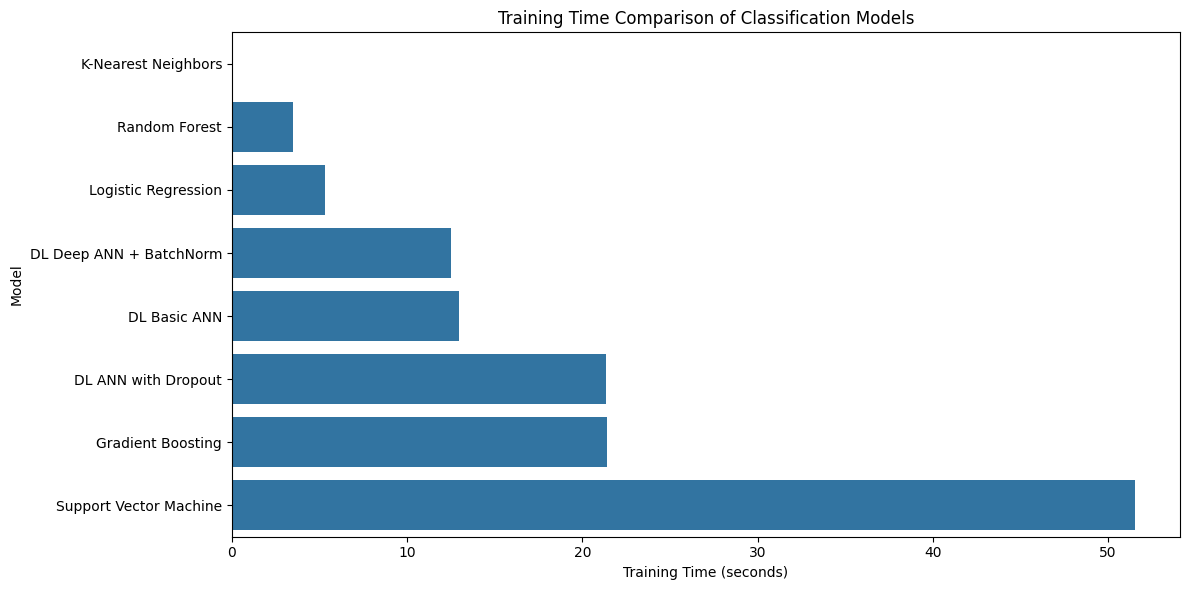

In [46]:
# ==============================
# TRAINING TIME BAR CHART
# ==============================

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=runtime_table,
    x="Training Time (sec)",
    y="Model"
)

plt.title("Training Time Comparison of Classification Models")
plt.xlabel("Training Time (seconds)")
plt.ylabel("Model")

plt.tight_layout()
plt.savefig(
    "figures/training_time_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

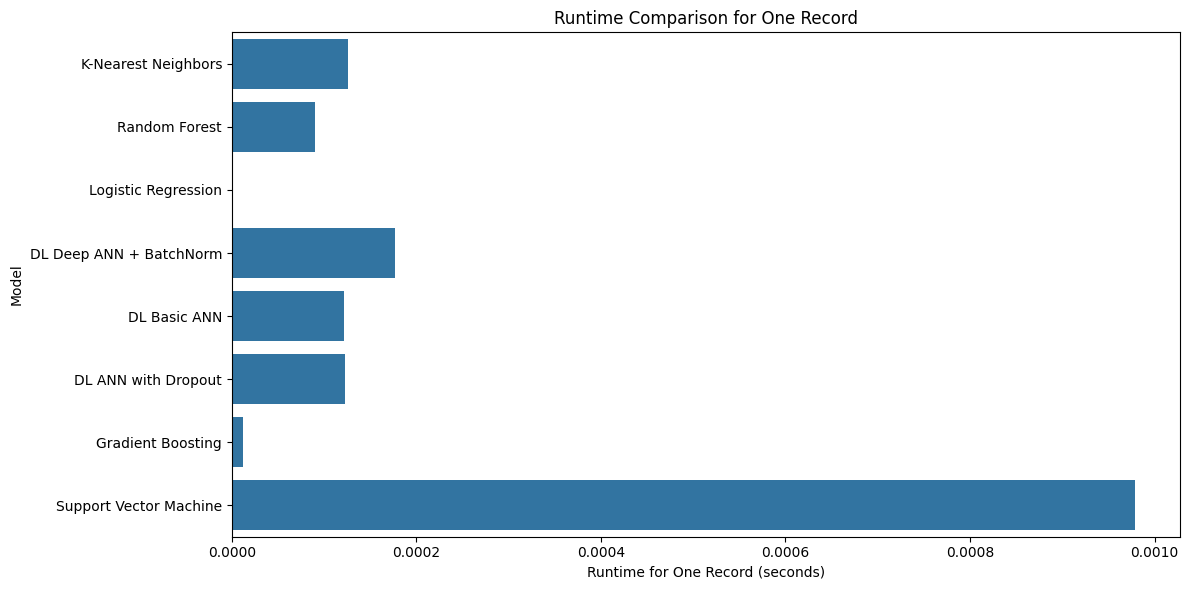

In [47]:
# ==============================
# RUNTIME FOR ONE RECORD BAR CHART
# ==============================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=runtime_table,
    x="Runtime for One Record (sec)",
    y="Model"
)

plt.title("Runtime Comparison for One Record")
plt.xlabel("Runtime for One Record (seconds)")
plt.ylabel("Model")

plt.tight_layout()
plt.savefig(
    "figures/runtime_one_record_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

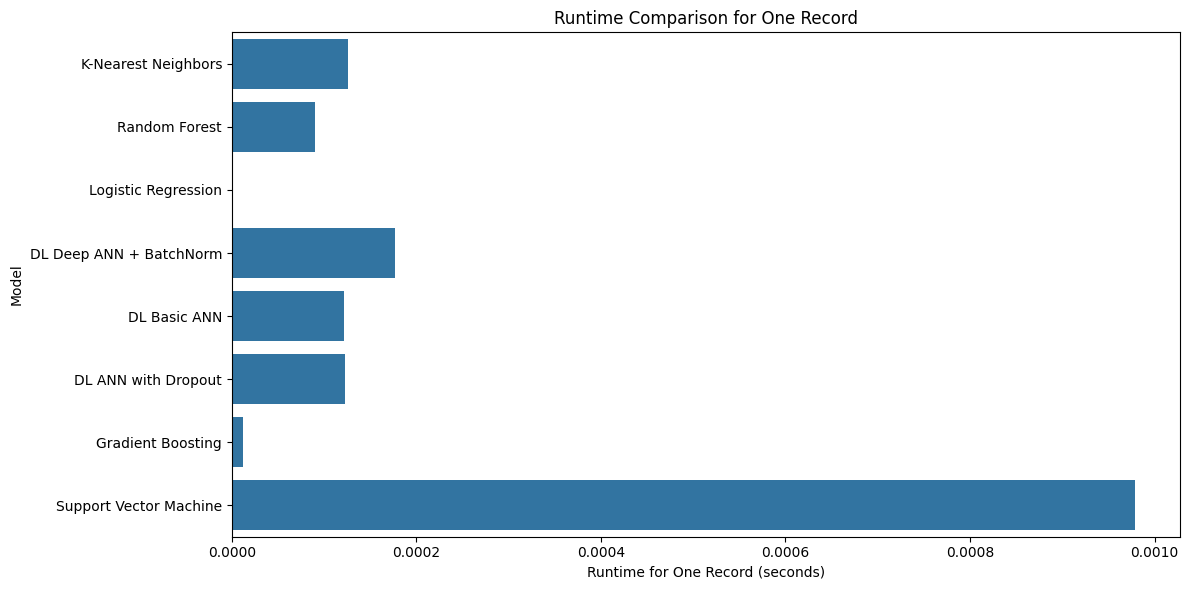

In [48]:
# ==============================
# RUNTIME FOR ONE RECORD BAR CHART
# ==============================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=runtime_table,
    x="Runtime for One Record (sec)",
    y="Model"
)

plt.title("Runtime Comparison for One Record")
plt.xlabel("Runtime for One Record (seconds)")
plt.ylabel("Model")

plt.tight_layout()
plt.savefig(
    "figures/runtime_one_record_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
# ==============================
# GET FEATURE NAMES AFTER PREPROCESSING
# ==============================

import numpy as np
import pandas as pd
import os

os.makedirs("tables", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# Numeric feature names
num_feature_names = numeric_features

# One-hot encoded categorical feature names
cat_feature_names = list(
    preprocessor
    .named_transformers_["cat"]
    .named_steps["onehot"]
    .get_feature_names_out(categorical_features)
)

# Binary feature names
bin_feature_names = binary_features

# All processed feature names
all_feature_names = num_feature_names + cat_feature_names + bin_feature_names

print("Toplam işlenmiş feature sayısı:", len(all_feature_names))
print("X_train_processed shape:", X_train_processed.shape)

Toplam işlenmiş feature sayısı: 111
X_train_processed shape: (8171, 111)


In [50]:
# ==============================
# RANDOM FOREST FEATURE IMPORTANCE
# ==============================

rf_model = trained_ml_models["Random Forest"]

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(20)

,Feature,Importance
1,review_count,0.098120
0,score,0.097143
2,distance_to_center,0.092730
4,amenity_count,0.060461
83,season_Winter,0.029527
82,season_Summer,0.025970
3,star_rating,0.024797
6,country_Norway,0.023721
84,has_free_cancellation,0.023507
81,season_Autumn,0.022961


In [51]:
feature_importance_df.to_csv(
    "tables/random_forest_feature_importance.csv",
    index=False
)

print("Feature importance tablosu kaydedildi: tables/random_forest_feature_importance.csv")

Feature importance tablosu kaydedildi: tables/random_forest_feature_importance.csv


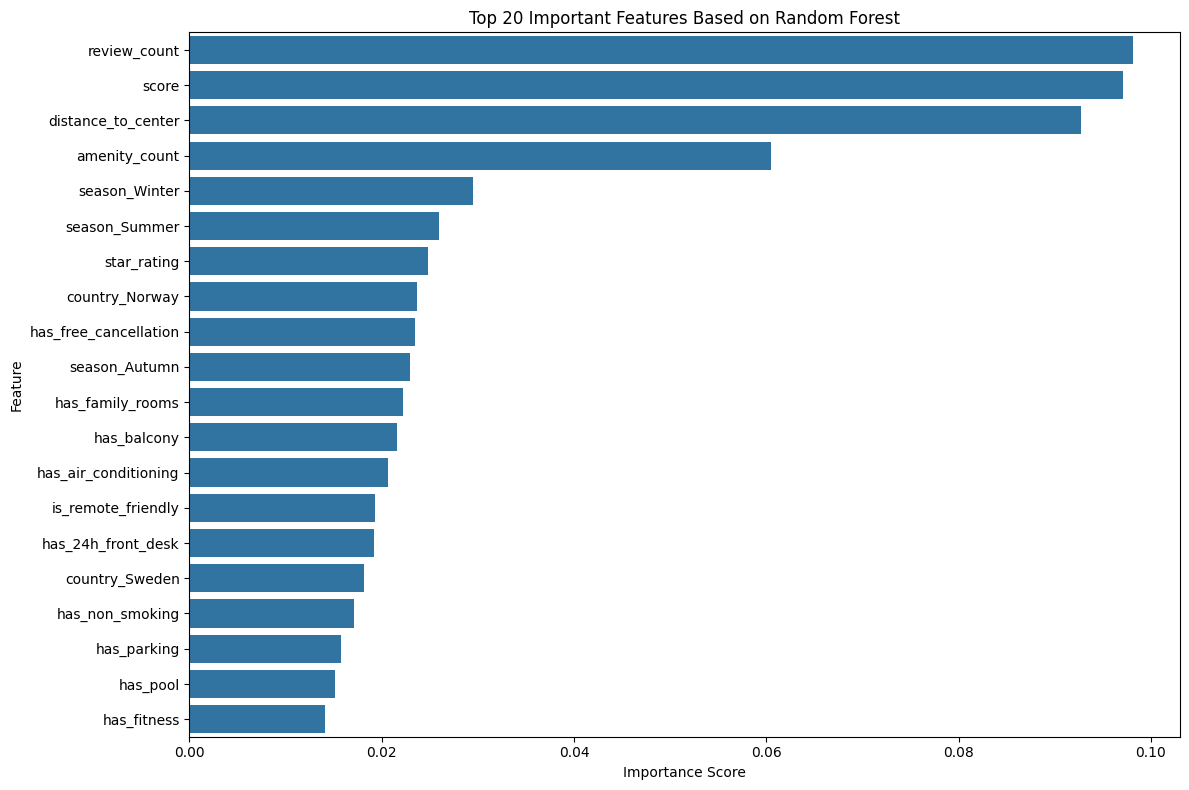

In [52]:
# ==============================
# FEATURE IMPORTANCE PLOT
# ==============================

import matplotlib.pyplot as plt
import seaborn as sns

top_n = 20

top_features = feature_importance_df.head(top_n)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Important Features Based on Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig(
    "figures/feature_importance_random_forest_top20.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
# ==============================
# SELECT TOP FEATURES
# ==============================

selected_top_n = 15

selected_features = feature_importance_df.head(selected_top_n)["Feature"].tolist()

selected_feature_indices = [
    all_feature_names.index(feature)
    for feature in selected_features
]

print("Seçilen feature sayısı:", len(selected_features))
print(selected_features)

Seçilen feature sayısı: 15
['review_count', 'score', 'distance_to_center', 'amenity_count', 'season_Winter', 'season_Summer', 'star_rating', 'country_Norway', 'has_free_cancellation', 'season_Autumn', 'has_family_rooms', 'has_balcony', 'has_air_conditioning', 'is_remote_friendly', 'has_24h_front_desk']


In [54]:
# ==============================
# CREATE SELECTED FEATURE MATRICES
# ==============================

X_train_selected = X_train_processed[:, selected_feature_indices]
X_test_selected = X_test_processed[:, selected_feature_indices]

print("All features train shape:", X_train_processed.shape)
print("Selected features train shape:", X_train_selected.shape)

All features train shape: (8171, 111)
Selected features train shape: (8171, 15)


In [55]:
# ==============================
# TRAIN RANDOM FOREST WITH SELECTED FEATURES
# ==============================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import time
import numpy as np

rf_selected = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_train = time.time()
rf_selected.fit(X_train_selected, y_train)
selected_training_time = time.time() - start_train

start_pred = time.time()
y_pred_selected = rf_selected.predict(X_test_selected)
selected_prediction_time = time.time() - start_pred

selected_runtime_one_record = selected_prediction_time / len(X_test_selected)

y_proba_selected = rf_selected.predict_proba(X_test_selected)

selected_acc = accuracy_score(y_test, y_pred_selected)
selected_precision = precision_score(y_test, y_pred_selected, average="macro", zero_division=0)
selected_recall = recall_score(y_test, y_pred_selected, average="macro", zero_division=0)
selected_f1 = f1_score(y_test, y_pred_selected, average="macro", zero_division=0)
selected_auc = roc_auc_score(y_test, y_proba_selected, multi_class="ovr", average="macro")

print("Random Forest with Selected Features")
print("Accuracy:", round(selected_acc * 100, 2))
print("Precision:", round(selected_precision * 100, 2))
print("Recall:", round(selected_recall * 100, 2))
print("F1-score:", round(selected_f1 * 100, 2))
print("AUC:", round(selected_auc * 100, 4))
print("Training Time:", round(selected_training_time, 4), "sec")
print("Runtime for One Record:", round(selected_runtime_one_record, 8), "sec")

Random Forest with Selected Features
Accuracy: 52.77
Precision: 53.47
Recall: 48.82
F1-score: 50.37
AUC: 78.2734
Training Time: 3.0286 sec
Runtime for One Record: 9.384e-05 sec


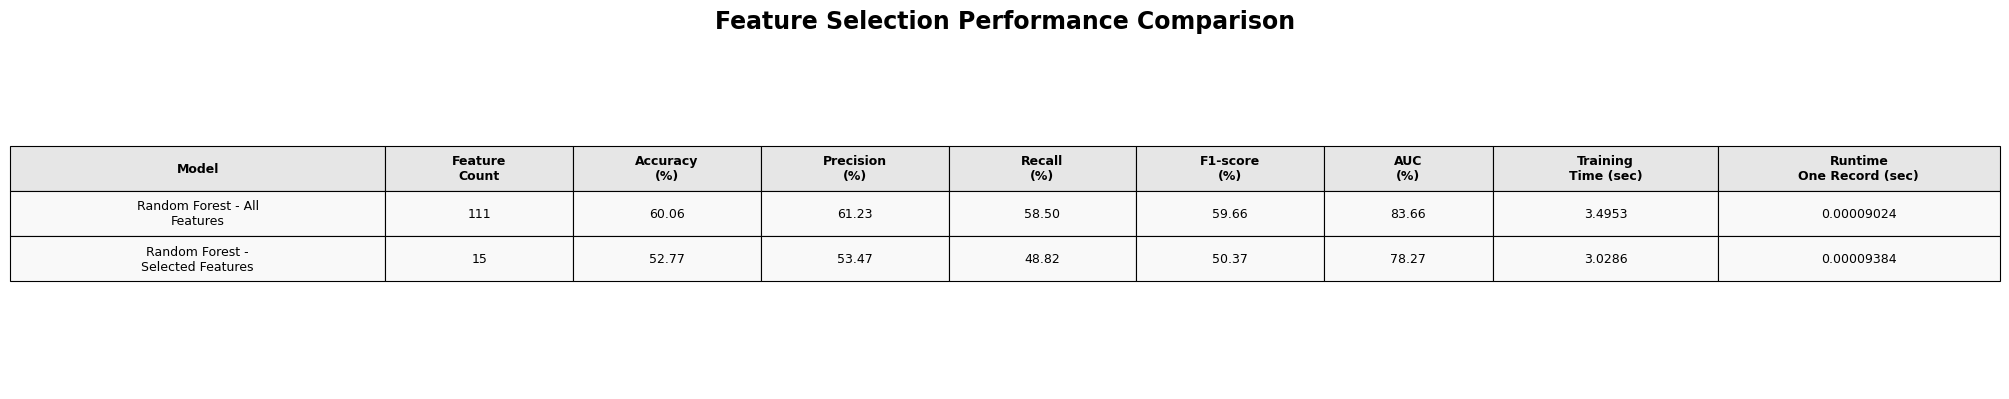

Tablo PNG olarak kaydedildi: tables/table9_feature_selection_comparison.png


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import textwrap

# ==============================
# FEATURE SELECTION COMPARISON TABLE AS PNG - FITTED TEXT
# ==============================

os.makedirs("tables", exist_ok=True)

rf_all_result = table7[table7["Model"] == "Random Forest"].iloc[0]

def to_percent(value):
    if 0 <= value <= 1:
        return value * 100
    return value

feature_selection_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - All Features",
        "Feature Count": X_train_processed.shape[1],
        "Accuracy": round(to_percent(rf_all_result["Accuracy"]), 2),
        "Precision": round(to_percent(rf_all_result["Precision"]), 2),
        "Recall": round(to_percent(rf_all_result["Recall"]), 2),
        "F1-score": round(to_percent(rf_all_result["F1-score"]), 2),
        "AUC": round(to_percent(rf_all_result["AUC"]), 2),
        "Training Time (sec)": round(rf_all_result["Training Time (sec)"], 4),
        "Runtime for One Record (sec)": round(rf_all_result["Runtime for One Record (sec)"], 8)
    },
    {
        "Model": "Random Forest - Selected Features",
        "Feature Count": selected_top_n,
        "Accuracy": round(to_percent(selected_acc), 2),
        "Precision": round(to_percent(selected_precision), 2),
        "Recall": round(to_percent(selected_recall), 2),
        "F1-score": round(to_percent(selected_f1), 2),
        "AUC": round(to_percent(selected_auc), 2),
        "Training Time (sec)": round(selected_training_time, 4),
        "Runtime for One Record (sec)": round(selected_runtime_one_record, 8)
    }
])

# ------------------------------
# Display için düzenleme
# ------------------------------

display_df = feature_selection_comparison.copy()

# Uzun model adlarını satıra böl
display_df["Model"] = display_df["Model"].apply(
    lambda x: "\n".join(textwrap.wrap(str(x), width=22))
)

# Sayısal formatlar
for col in ["Accuracy", "Precision", "Recall", "F1-score", "AUC"]:
    display_df[col] = display_df[col].map(lambda x: f"{x:.2f}")

display_df["Feature Count"] = display_df["Feature Count"].map(lambda x: f"{int(x)}")
display_df["Training Time (sec)"] = display_df["Training Time (sec)"].map(lambda x: f"{x:.4f}")
display_df["Runtime for One Record (sec)"] = display_df["Runtime for One Record (sec)"].map(lambda x: f"{x:.8f}")

# Sütun başlıklarını kısalt
display_df.columns = [
    "Model",
    "Feature\nCount",
    "Accuracy\n(%)",
    "Precision\n(%)",
    "Recall\n(%)",
    "F1-score\n(%)",
    "AUC\n(%)",
    "Training\nTime (sec)",
    "Runtime\nOne Record (sec)"
]

# ------------------------------
# PNG tablo çizimi
# ------------------------------

fig, ax = plt.subplots(figsize=(20, 4.2))
ax.axis("off")

fig.suptitle(
    "Feature Selection Performance Comparison",
    fontsize=17,
    fontweight="bold",
    y=0.94
)

# Sütun genişlikleri
col_widths = [
    0.20,  # Model
    0.10,  # Feature Count
    0.10,  # Accuracy
    0.10,  # Precision
    0.10,  # Recall
    0.10,  # F1
    0.09,  # AUC
    0.12,  # Training Time
    0.15   # Runtime
]

tbl = ax.table(
    cellText=display_df.values,
    colLabels=display_df.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=col_widths
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 2.5)

# Stil
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor("black")
    cell.set_linewidth(0.8)

    if row == 0:
        cell.set_facecolor("#E6E6E6")
        cell.set_text_props(weight="bold", color="black", fontsize=9)
    else:
        cell.set_facecolor("#F9F9F9")
        cell.set_text_props(fontsize=9)

plt.tight_layout()

save_path = "tables/table9_feature_selection_comparison.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Tablo PNG olarak kaydedildi: {save_path}")

In [57]:
feature_selection_comparison.to_csv(
    "tables/feature_selection_comparison.csv",
    index=False
)

print("Feature selection karşılaştırma tablosu kaydedildi.")

Feature selection karşılaştırma tablosu kaydedildi.


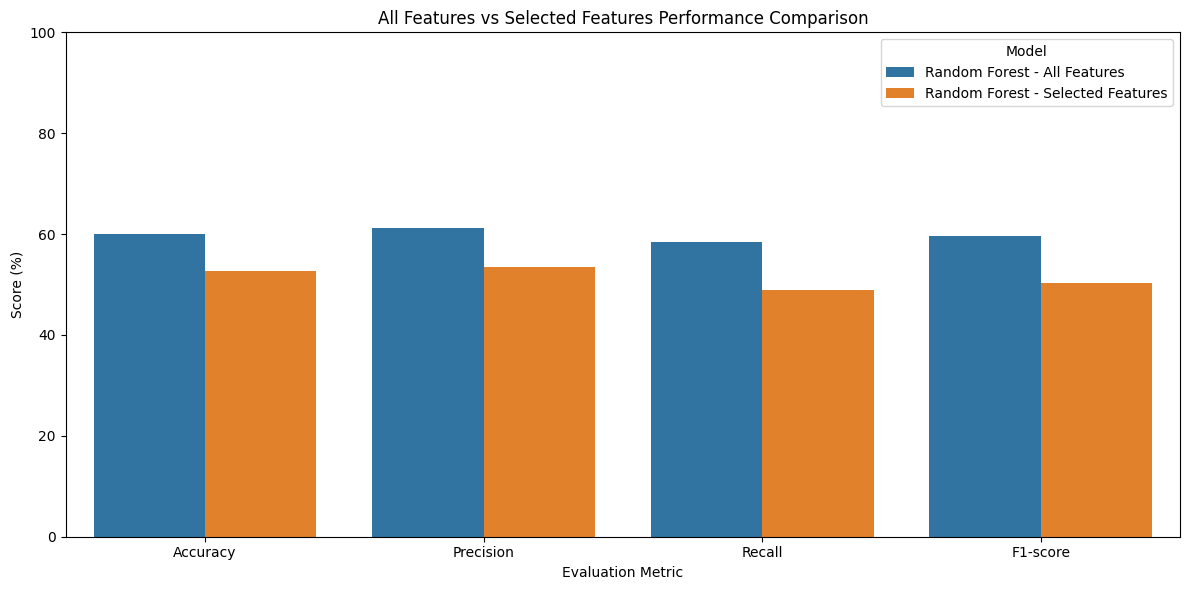

In [58]:
# ==============================
# FEATURE SELECTION COMPARISON PLOT
# ==============================

comparison_melted = feature_selection_comparison.melt(
    id_vars=["Model", "Feature Count"],
    value_vars=["Accuracy", "Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("All Features vs Selected Features Performance Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.savefig(
    "figures/all_features_vs_selected_features_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

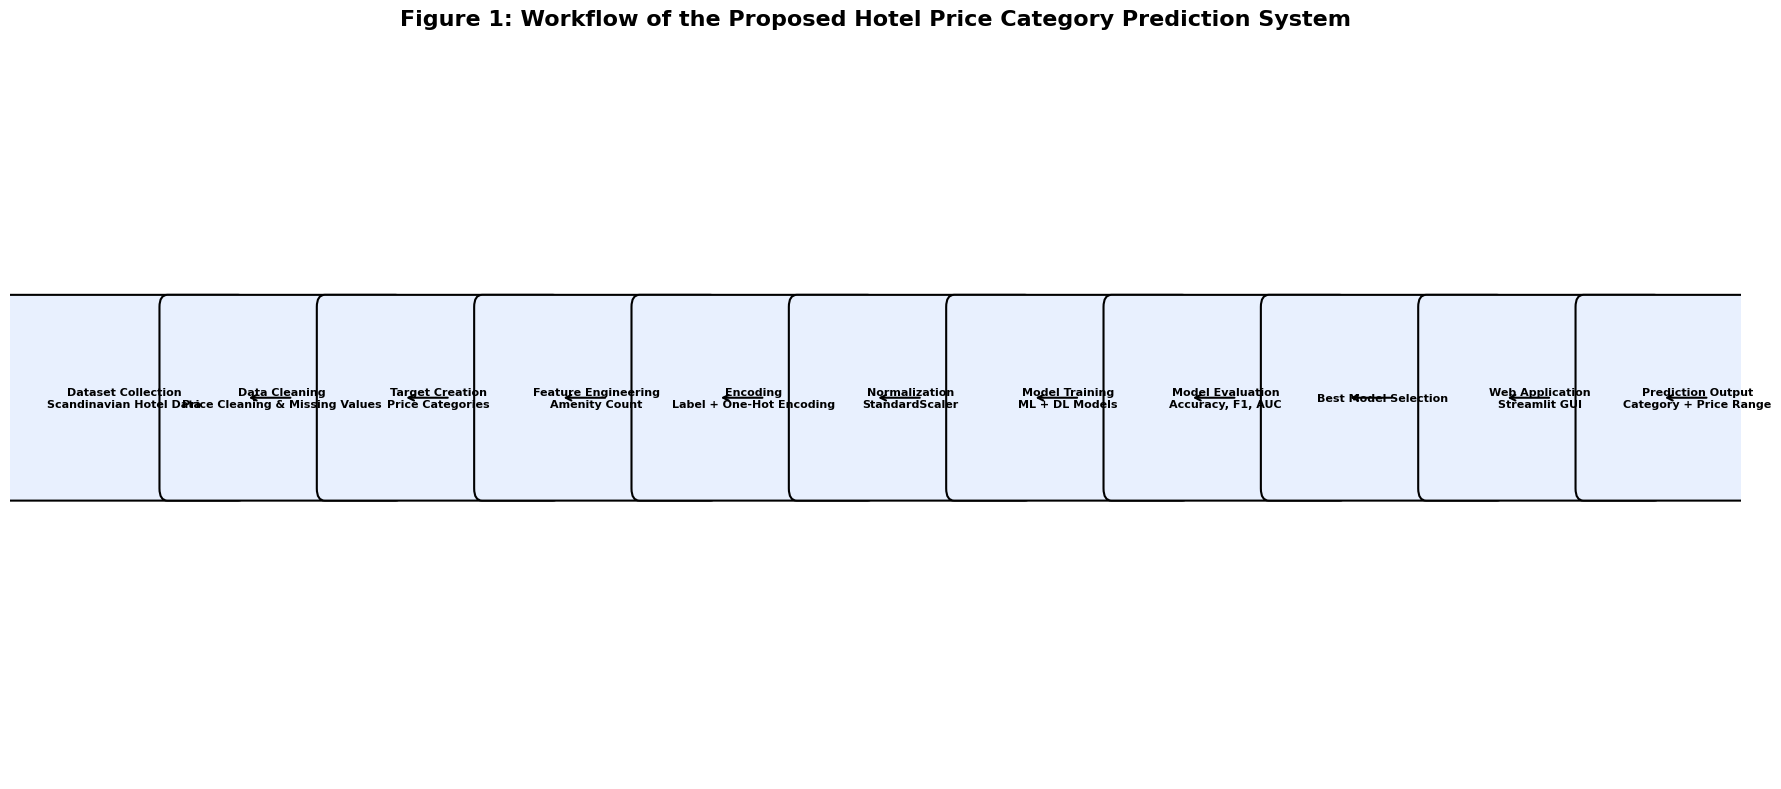

Figure 1 kaydedildi: figures/figure1_workflow_diagram.png


In [59]:
# ==============================
# FIGURE 1: WORKFLOW DIAGRAM
# ==============================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

os.makedirs("figures", exist_ok=True)

steps = [
    "Dataset Collection\nScandinavian Hotel Data",
    "Data Cleaning\nPrice Cleaning & Missing Values",
    "Target Creation\nPrice Categories",
    "Feature Engineering\nAmenity Count",
    "Encoding\nLabel + One-Hot Encoding",
    "Normalization\nStandardScaler",
    "Model Training\nML + DL Models",
    "Model Evaluation\nAccuracy, F1, AUC",
    "Best Model Selection",
    "Web Application\nStreamlit GUI",
    "Prediction Output\nCategory + Price Range"
]

fig, ax = plt.subplots(figsize=(18, 8))
ax.set_xlim(0, 11)
ax.set_ylim(0, 3)
ax.axis("off")

box_width = 1.45
box_height = 0.75
y_pos = 1.2

for i, step in enumerate(steps):
    x_pos = i

    box = patches.FancyBboxPatch(
        (x_pos, y_pos),
        box_width,
        box_height,
        boxstyle="round,pad=0.05",
        linewidth=1.5,
        edgecolor="black",
        facecolor="#e8f0fe"
    )

    ax.add_patch(box)

    ax.text(
        x_pos + box_width / 2,
        y_pos + box_height / 2,
        step,
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold"
    )

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(x_pos + box_width + 0.05, y_pos + box_height / 2),
            xytext=(x_pos + box_width + 0.35, y_pos + box_height / 2),
            arrowprops=dict(
                arrowstyle="->",
                linewidth=1.5,
                color="black"
            )
        )

plt.title(
    "Figure 1: Workflow of the Proposed Hotel Price Category Prediction System",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.savefig(
    "figures/figure1_workflow_diagram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 kaydedildi: figures/figure1_workflow_diagram.png")

In [60]:
# ==============================
# SAVE BEST MACHINE LEARNING MODEL
# ==============================

import joblib
import os
import pandas as pd

os.makedirs("saved_model", exist_ok=True)

ml_model_names = [
    "Logistic Regression",
    "K-Nearest Neighbors",
    "Support Vector Machine",
    "Random Forest",
    "Gradient Boosting"
]

ml_results = table7[table7["Model"].isin(ml_model_names)].copy()

best_ml_name = ml_results.sort_values(by="F1-score", ascending=False).iloc[0]["Model"]
best_ml_model = trained_ml_models[best_ml_name]

print("Best ML Model:", best_ml_name)

joblib.dump(best_ml_model, "saved_model/best_model.pkl")
joblib.dump(preprocessor, "saved_model/preprocessor.pkl")

model_info = {
    "best_model_name": best_ml_name,
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "binary_features": binary_features,
    "class_labels": {
        0: "Ekonomik",
        1: "Standart",
        2: "Premium",
        3: "Lüks"
    },
    "price_ranges": {
        0: "0 – 25.000 TL",
        1: "25.001 – 40.000 TL",
        2: "40.001 – 70.000 TL",
        3: "70.001 TL ve üzeri"
    }
}

joblib.dump(model_info, "saved_model/model_info.pkl")

print("Model dosyaları kaydedildi.")

Best ML Model: Random Forest
Model dosyaları kaydedildi.


In [61]:
# ==============================
# SAVE GUI OPTIONS
# ==============================

gui_options = {
    "countries": sorted(df_model["country"].dropna().unique().tolist()),
    "cities": sorted(df_model["city"].dropna().unique().tolist()),
    "seasons": sorted(df_model["season"].dropna().unique().tolist()),
    "amenities": binary_features
}

joblib.dump(gui_options, "saved_model/gui_options.pkl")

print("GUI seçenekleri kaydedildi.")

GUI seçenekleri kaydedildi.


In [62]:
# ==============================
# TEST SAVED MODEL
# ==============================

loaded_model = joblib.load("saved_model/best_model.pkl")
loaded_preprocessor = joblib.load("saved_model/preprocessor.pkl")
loaded_info = joblib.load("saved_model/model_info.pkl")

sample_input = X_test.iloc[[0]]

sample_processed = loaded_preprocessor.transform(sample_input)
prediction = loaded_model.predict(sample_processed)[0]

category = loaded_info["class_labels"][prediction]
price_range = loaded_info["price_ranges"][prediction]

print("Tahmini Kategori:", category)
print("Beklenen Fiyat Aralığı:", price_range)

Tahmini Kategori: Lüks
Beklenen Fiyat Aralığı: 70.001 TL ve üzeri


In [63]:
!pip install matplotlib-venn

In [64]:
# https://pypi.python.org/pypi/libarchive
!apt-get -qq install -y libarchive-dev && pip install -U libarchive
import libarchive

Selecting previously unselected package libarchive-dev:amd64.
(Reading database ... 118242 files and directories currently installed.)
Preparing to unpack .../libarchive-dev_3.6.0-1ubuntu1.7_amd64.deb ...
Unpacking libarchive-dev:amd64 (3.6.0-1ubuntu1.7) ...
Setting up libarchive-dev:amd64 (3.6.0-1ubuntu1.7) ...
Processing triggers for man-db (2.10.2-1) ...
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 3.6 MB/s eta 0:00:00
  Created wheel for libarchive: filename=libarchive-0.4.7-py3-none-any.whl size=31629 sha256=e2e3a11c43c2522a52f67935501ddb8029d0229e31fedf9638454074699226b1
  Stored in directory: /root/.cache/pip/wheels/29/20/ab/f101da7b245b996aa097685ef742243725ea6150f5b3b6d9ed
Successfully built libarchive


In [65]:
# https://pypi.python.org/pypi/pydot
!apt-get -qq install -y graphviz && pip install pydot
import pydot

In [66]:
!pip install cartopy
import cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 51.6 MB/s eta 0:00:00


In [67]:
import shutil

shutil.make_archive("saved_model", "zip", "saved_model")

'/content/saved_model.zip'

In [68]:
# ==============================
# PRICE PREDICTION MODEL FOR GUI
# ==============================

import numpy as np
import pandas as pd
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs("saved_model", exist_ok=True)

# Daha önce oluşturduğun train_df kullanılacak
df_reg = train_df.copy()

# Fiyatı olmayanları çıkar
df_reg = df_reg.dropna(subset=["price_tl"]).copy()

# Çok uç fiyatları kırp
upper_limit = df_reg["price_tl"].quantile(0.99)
df_reg = df_reg[df_reg["price_tl"] <= upper_limit].copy()

# Özellikler
categorical_features = ["country", "city", "season"]

numeric_features = [
    "score",
    "review_count",
    "distance_to_center",
    "star_rating",
    "amenity_count"
]

binary_features = amenity_columns

features = categorical_features + numeric_features + binary_features

X = df_reg[features]

# Fiyatı log dönüşümle tahmin edeceğiz
y = np.log1p(df_reg["price_tl"])

# Train-test ayır
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# One-hot encoder uyumluluğu
try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

# Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

binary_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

price_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("bin", binary_transformer, binary_features)
    ]
)

X_train_reg_processed = price_preprocessor.fit_transform(X_train_reg)
X_test_reg_processed = price_preprocessor.transform(X_test_reg)

# Regression modeli
price_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=25,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

price_model.fit(X_train_reg_processed, y_train_reg)

# Test
y_pred_log = price_model.predict(X_test_reg_processed)

y_test_price = np.expm1(y_test_reg)
y_pred_price = np.expm1(y_pred_log)

mae = mean_absolute_error(y_test_price, y_pred_price)
rmse = np.sqrt(mean_squared_error(y_test_price, y_pred_price))
r2 = r2_score(y_test_price, y_pred_price)

print("Price Prediction Results")
print("MAE:", round(mae, 2), "TL")
print("RMSE:", round(rmse, 2), "TL")
print("R2 Score:", round(r2, 4))

# GUI için bilgi dosyası
model_info = {
    "model_name": "Random Forest Regressor",
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "binary_features": binary_features,
    "price_ranges": {
        "Ekonomik": "0 – 25.000 TL",
        "Standart": "25.001 – 40.000 TL",
        "Premium": "40.001 – 70.000 TL",
        "Lüks": "70.001 TL ve üzeri"
    }
}

gui_options = {
    "countries": sorted(df_reg["country"].dropna().unique().tolist()),
    "cities": sorted(df_reg["city"].dropna().unique().tolist()),
    "seasons": sorted(df_reg["season"].dropna().unique().tolist()),
    "amenities": binary_features
}

# Kaydet
joblib.dump(price_model, "saved_model/price_model.pkl")
joblib.dump(price_preprocessor, "saved_model/price_preprocessor.pkl")
joblib.dump(model_info, "saved_model/price_model_info.pkl")
joblib.dump(gui_options, "saved_model/gui_options.pkl")

print("Fiyat tahmin modeli başarıyla kaydedildi.")

Price Prediction Results
MAE: 11180.66 TL
RMSE: 17913.12 TL
R2 Score: 0.482
Fiyat tahmin modeli başarıyla kaydedildi.


In [69]:
# ==============================
# SAVE TABLES AS PNG
# ==============================

import pandas as pd
import matplotlib.pyplot as plt
import textwrap
import os

os.makedirs("tables", exist_ok=True)

def save_table_as_png(csv_path, png_path, title, wrap_width=45, font_size=8):
    if not os.path.exists(csv_path):
        print(f"Dosya bulunamadı: {csv_path}")
        return

    df = pd.read_csv(csv_path)
    df_display = df.copy()

    # Uzun metinleri satırlara böl
    for col in df_display.columns:
        df_display[col] = df_display[col].astype(str).apply(
            lambda x: "\n".join(textwrap.wrap(x, width=wrap_width))
        )

    row_count = len(df_display)
    col_count = len(df_display.columns)

    fig_width = max(12, col_count * 2.2)
    fig_height = max(4, row_count * 0.7 + 2)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.axis("off")

    table = ax.table(
        cellText=df_display.values,
        colLabels=df_display.columns,
        cellLoc="center",
        colLoc="center",
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(font_size)
    table.scale(1, 1.8)

    for key, cell in table.get_celld().items():
        cell.set_linewidth(0.6)

        if key[0] == 0:
            cell.set_text_props(weight="bold")
            cell.set_facecolor("#f2f2f2")
        else:
            cell.set_facecolor("white")

    plt.title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=20
    )

    plt.tight_layout()
    plt.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"PNG kaydedildi: {png_path}")

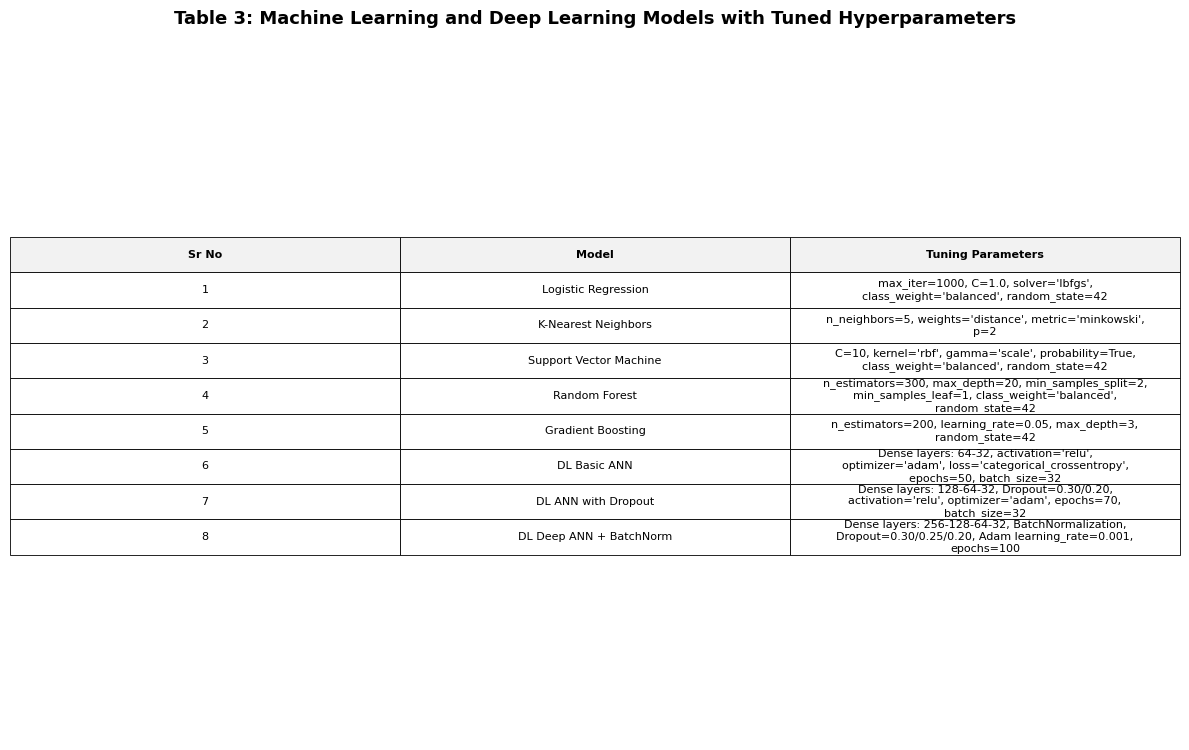

PNG kaydedildi: tables/table3_model_parameters.png


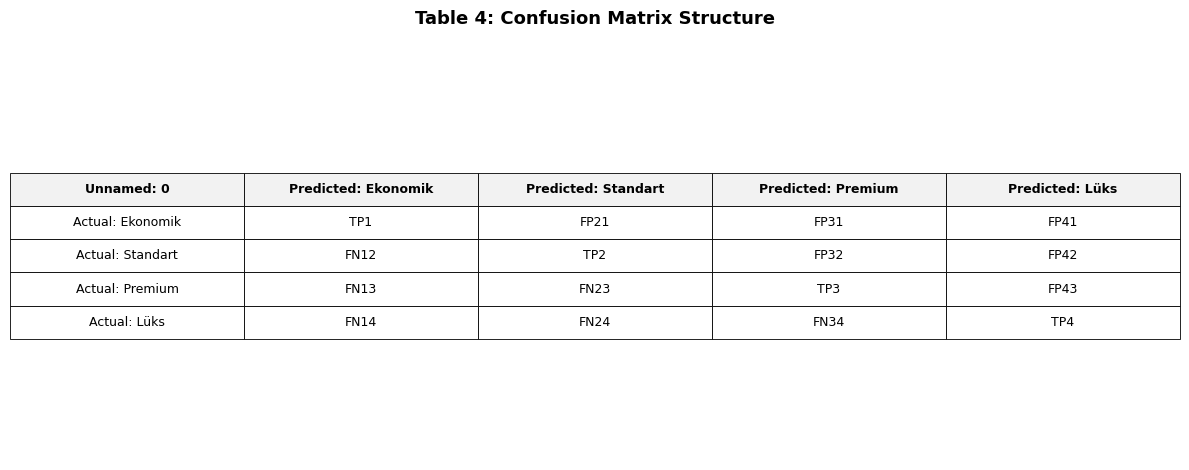

PNG kaydedildi: tables/table4_confusion_matrix_structure.png


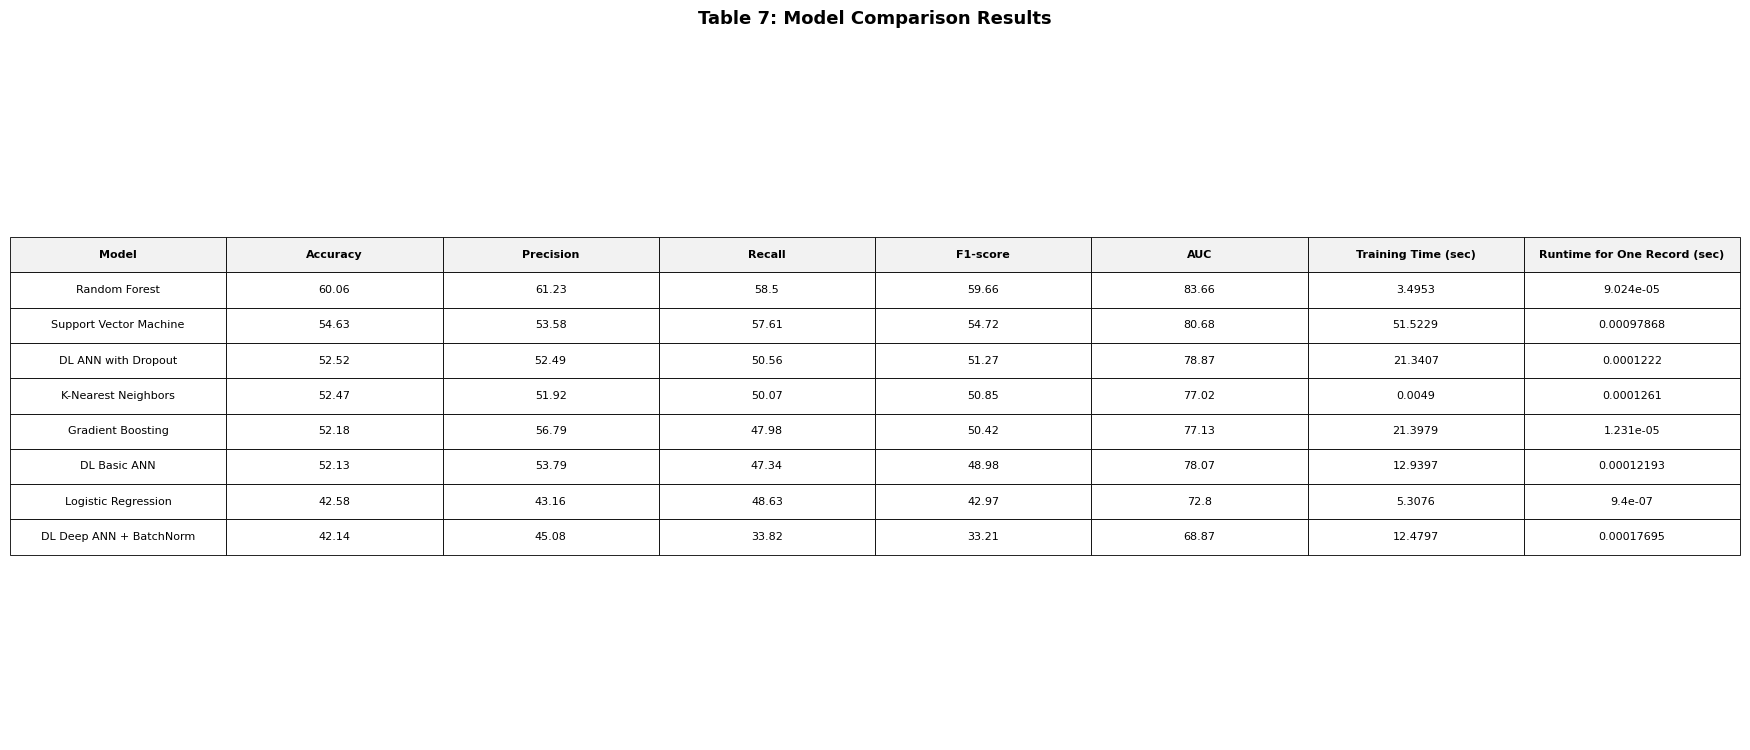

PNG kaydedildi: tables/table7_model_comparison.png


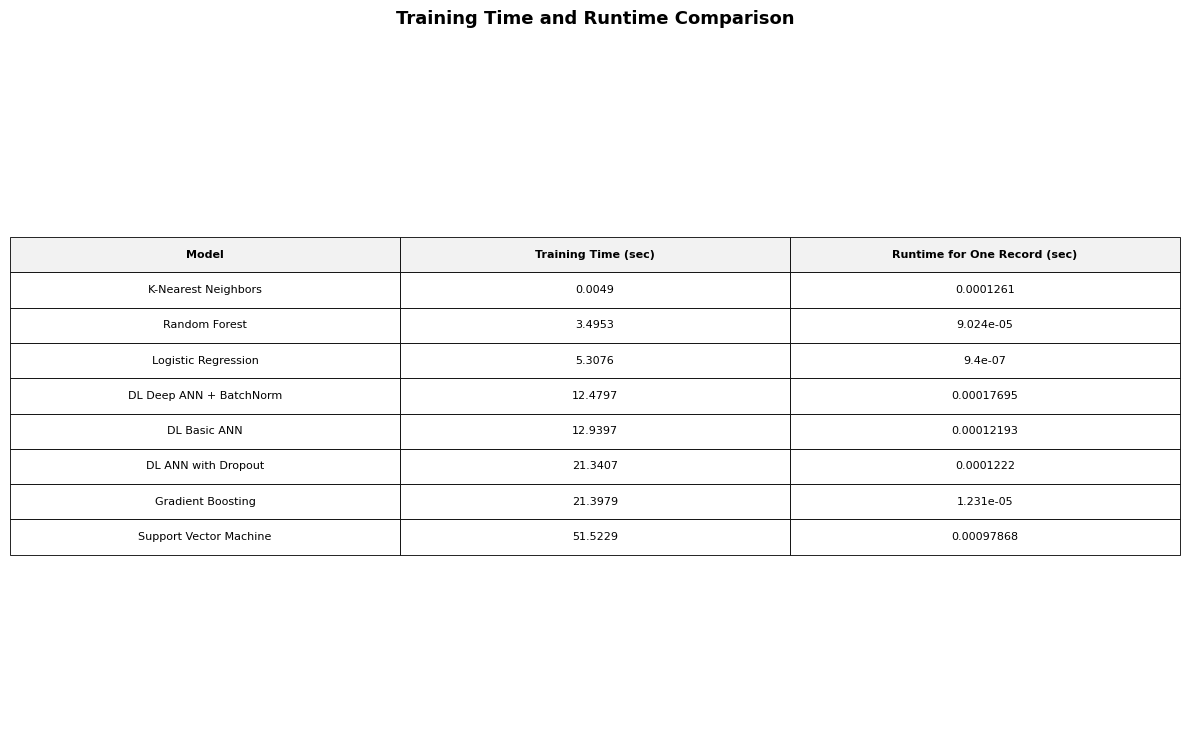

PNG kaydedildi: tables/training_time_runtime_table.png


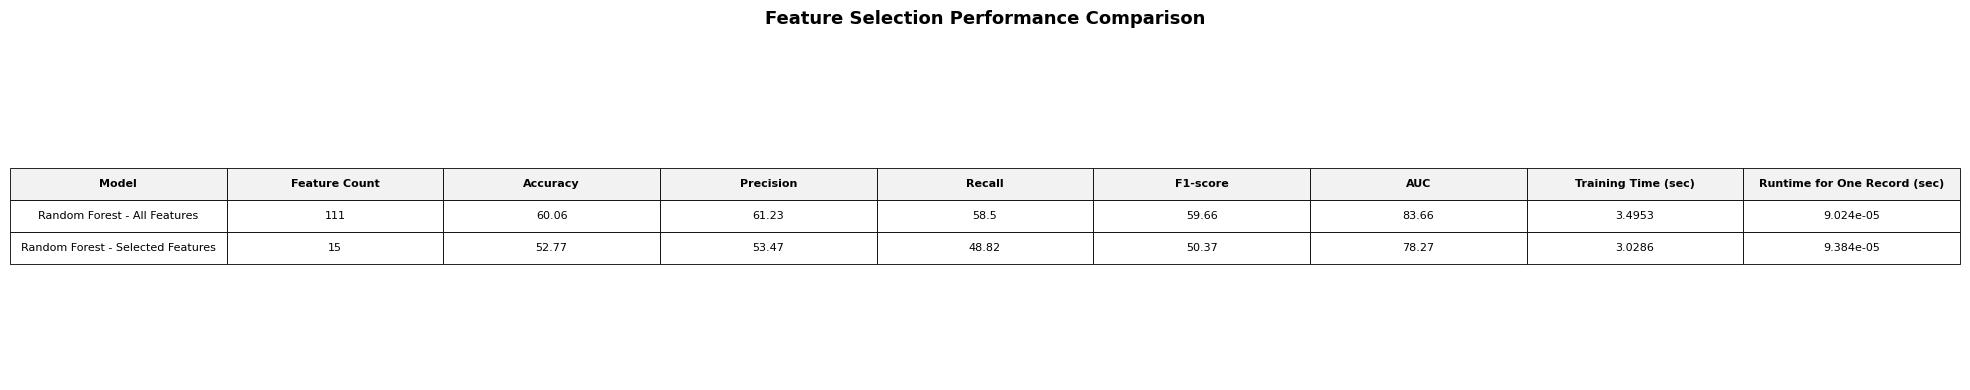

PNG kaydedildi: tables/feature_selection_comparison.png


In [70]:
# Table 3
save_table_as_png(
    csv_path="tables/table3_model_parameters.csv",
    png_path="tables/table3_model_parameters.png",
    title="Table 3: Machine Learning and Deep Learning Models with Tuned Hyperparameters",
    wrap_width=55,
    font_size=8
)

# Table 4
save_table_as_png(
    csv_path="tables/table4_confusion_matrix_structure.csv",
    png_path="tables/table4_confusion_matrix_structure.png",
    title="Table 4: Confusion Matrix Structure",
    wrap_width=35,
    font_size=9
)

# Table 7
save_table_as_png(
    csv_path="tables/table7_model_comparison.csv",
    png_path="tables/table7_model_comparison.png",
    title="Table 7: Model Comparison Results",
    wrap_width=35,
    font_size=8
)

# Training Time / Runtime Table
save_table_as_png(
    csv_path="tables/training_time_runtime_table.csv",
    png_path="tables/training_time_runtime_table.png",
    title="Training Time and Runtime Comparison",
    wrap_width=35,
    font_size=8
)

# Feature Selection Comparison Table
save_table_as_png(
    csv_path="tables/feature_selection_comparison.csv",
    png_path="tables/feature_selection_comparison.png",
    title="Feature Selection Performance Comparison",
    wrap_width=35,
    font_size=8
)

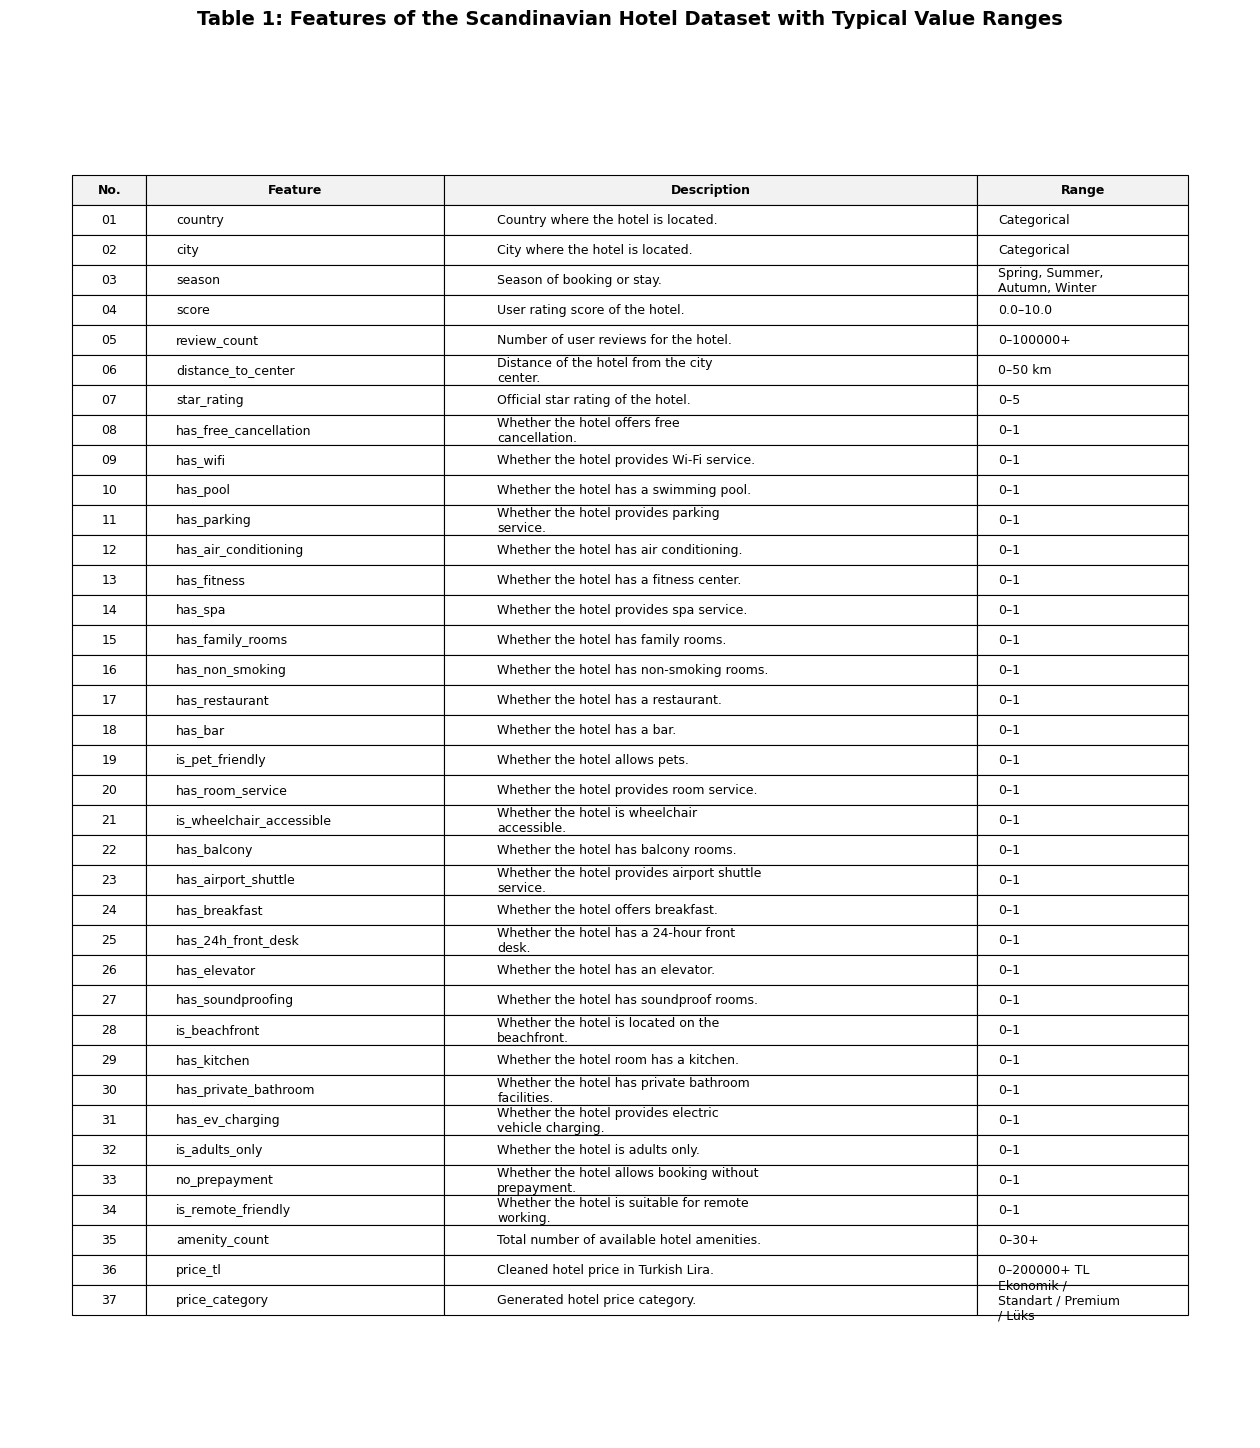

Table 1 CSV kaydedildi: tables/table1_dataset_features.csv
Table 1 PNG kaydedildi: tables/table1_dataset_features.png


In [71]:
# ==============================
# TABLE 1: FEATURES OF THE SCANDINAVIAN HOTEL DATASET
# ==============================

import pandas as pd
import matplotlib.pyplot as plt
import textwrap
import os

os.makedirs("tables", exist_ok=True)

table1_data = [
    ["01", "country", "Country where the hotel is located.", "Categorical"],
    ["02", "city", "City where the hotel is located.", "Categorical"],
    ["03", "season", "Season of booking or stay.", "Spring, Summer, Autumn, Winter"],
    ["04", "score", "User rating score of the hotel.", "0.0–10.0"],
    ["05", "review_count", "Number of user reviews for the hotel.", "0–100000+"],
    ["06", "distance_to_center", "Distance of the hotel from the city center.", "0–50 km"],
    ["07", "star_rating", "Official star rating of the hotel.", "0–5"],
    ["08", "has_free_cancellation", "Whether the hotel offers free cancellation.", "0–1"],
    ["09", "has_wifi", "Whether the hotel provides Wi-Fi service.", "0–1"],
    ["10", "has_pool", "Whether the hotel has a swimming pool.", "0–1"],
    ["11", "has_parking", "Whether the hotel provides parking service.", "0–1"],
    ["12", "has_air_conditioning", "Whether the hotel has air conditioning.", "0–1"],
    ["13", "has_fitness", "Whether the hotel has a fitness center.", "0–1"],
    ["14", "has_spa", "Whether the hotel provides spa service.", "0–1"],
    ["15", "has_family_rooms", "Whether the hotel has family rooms.", "0–1"],
    ["16", "has_non_smoking", "Whether the hotel has non-smoking rooms.", "0–1"],
    ["17", "has_restaurant", "Whether the hotel has a restaurant.", "0–1"],
    ["18", "has_bar", "Whether the hotel has a bar.", "0–1"],
    ["19", "is_pet_friendly", "Whether the hotel allows pets.", "0–1"],
    ["20", "has_room_service", "Whether the hotel provides room service.", "0–1"],
    ["21", "is_wheelchair_accessible", "Whether the hotel is wheelchair accessible.", "0–1"],
    ["22", "has_balcony", "Whether the hotel has balcony rooms.", "0–1"],
    ["23", "has_airport_shuttle", "Whether the hotel provides airport shuttle service.", "0–1"],
    ["24", "has_breakfast", "Whether the hotel offers breakfast.", "0–1"],
    ["25", "has_24h_front_desk", "Whether the hotel has a 24-hour front desk.", "0–1"],
    ["26", "has_elevator", "Whether the hotel has an elevator.", "0–1"],
    ["27", "has_soundproofing", "Whether the hotel has soundproof rooms.", "0–1"],
    ["28", "is_beachfront", "Whether the hotel is located on the beachfront.", "0–1"],
    ["29", "has_kitchen", "Whether the hotel room has a kitchen.", "0–1"],
    ["30", "has_private_bathroom", "Whether the hotel has private bathroom facilities.", "0–1"],
    ["31", "has_ev_charging", "Whether the hotel provides electric vehicle charging.", "0–1"],
    ["32", "is_adults_only", "Whether the hotel is adults only.", "0–1"],
    ["33", "no_prepayment", "Whether the hotel allows booking without prepayment.", "0–1"],
    ["34", "is_remote_friendly", "Whether the hotel is suitable for remote working.", "0–1"],
    ["35", "amenity_count", "Total number of available hotel amenities.", "0–30+"],
    ["36", "price_tl", "Cleaned hotel price in Turkish Lira.", "0–200000+ TL"],
    ["37", "price_category", "Generated hotel price category.", "Ekonomik / Standart / Premium / Lüks"]
]

table1 = pd.DataFrame(
    table1_data,
    columns=["No.", "Feature", "Description", "Range"]
)

# CSV olarak kaydet
table1.to_csv("tables/table1_dataset_features.csv", index=False)

# ------------------------------
# PNG için görünüm düzenleme
# ------------------------------
table1_display = table1.copy()

table1_display["Description"] = table1_display["Description"].apply(
    lambda x: "\n".join(textwrap.wrap(str(x), width=42))
)

table1_display["Range"] = table1_display["Range"].apply(
    lambda x: "\n".join(textwrap.wrap(str(x), width=18))
)

fig, ax = plt.subplots(figsize=(16, 18))
ax.axis("off")

tbl = ax.table(
    cellText=table1_display.values,
    colLabels=table1_display.columns,
    cellLoc="left",
    colLoc="center",
    loc="center",
    colWidths=[0.06, 0.24, 0.43, 0.17]
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.8)

for (row, col), cell in tbl.get_celld().items():
    cell.set_linewidth(0.8)
    cell.set_edgecolor("black")

    if row == 0:
        cell.set_text_props(weight="bold", ha="center", va="center")
        cell.set_facecolor("#f2f2f2")
    else:
        if col == 0:
            cell.set_text_props(ha="center")
        else:
            cell.set_text_props(ha="left")

plt.title(
    "Table 1: Features of the Scandinavian Hotel Dataset with Typical Value Ranges",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.savefig("tables/table1_dataset_features.png", dpi=300, bbox_inches="tight")
plt.show()

print("Table 1 CSV kaydedildi: tables/table1_dataset_features.csv")
print("Table 1 PNG kaydedildi: tables/table1_dataset_features.png")

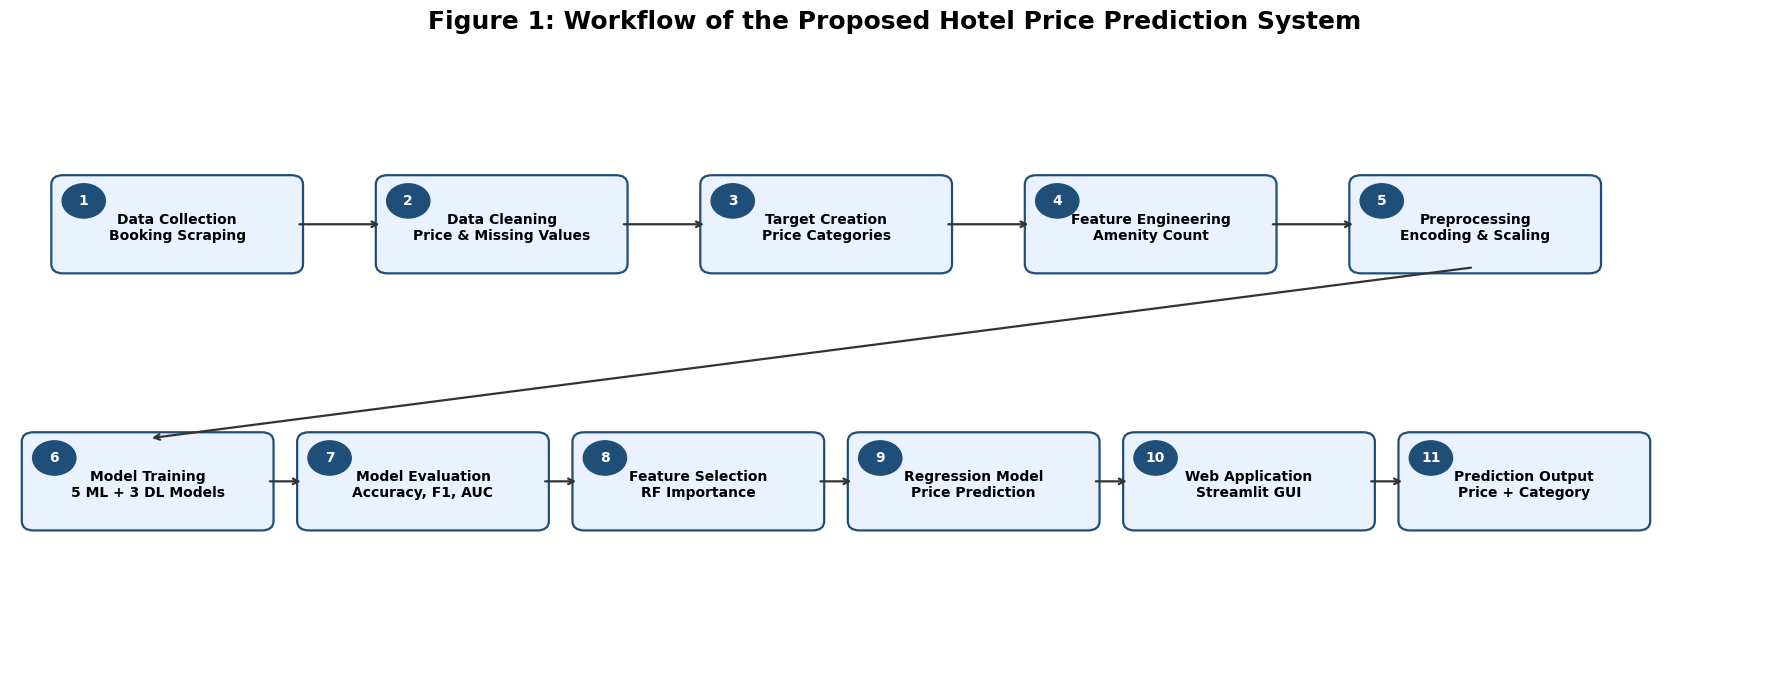

Figure 1 kaydedildi: figures/figure1_workflow_diagram_clean.png


In [72]:
# ==============================
# FIGURE 1: CLEAN WORKFLOW DIAGRAM
# Hotel Price Prediction Process
# ==============================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

os.makedirs("figures", exist_ok=True)

# ------------------------------
# Workflow steps
# ------------------------------

steps_top = [
    ("1", "Data Collection\nBooking Scraping"),
    ("2", "Data Cleaning\nPrice & Missing Values"),
    ("3", "Target Creation\nPrice Categories"),
    ("4", "Feature Engineering\nAmenity Count"),
    ("5", "Preprocessing\nEncoding & Scaling")
]

steps_bottom = [
    ("6", "Model Training\n5 ML + 3 DL Models"),
    ("7", "Model Evaluation\nAccuracy, F1, AUC"),
    ("8", "Feature Selection\nRF Importance"),
    ("9", "Regression Model\nPrice Prediction"),
    ("10", "Web Application\nStreamlit GUI"),
    ("11", "Prediction Output\nPrice + Category")
]

# ------------------------------
# Figure settings
# ------------------------------

fig, ax = plt.subplots(figsize=(18, 7))
ax.set_xlim(0, 18)
ax.set_ylim(0, 8)
ax.axis("off")

box_width = 2.4
box_height = 1.1

top_y = 5.3
bottom_y = 2.0

top_x_positions = [0.5, 3.8, 7.1, 10.4, 13.7]
bottom_x_positions = [0.2, 3.0, 5.8, 8.6, 11.4, 14.2]

box_color = "#EAF2FF"
edge_color = "#1F4E79"
arrow_color = "#333333"

# ------------------------------
# Function to draw rounded boxes
# ------------------------------

def draw_box(ax, x, y, number, text):
    box = patches.FancyBboxPatch(
        (x, y),
        box_width,
        box_height,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        linewidth=1.6,
        edgecolor=edge_color,
        facecolor=box_color
    )
    ax.add_patch(box)

    # Step number circle
    circle = patches.Circle(
        (x + 0.25, y + box_height - 0.25),
        0.22,
        facecolor=edge_color,
        edgecolor=edge_color
    )
    ax.add_patch(circle)

    ax.text(
        x + 0.25,
        y + box_height - 0.25,
        number,
        ha="center",
        va="center",
        fontsize=10,
        color="white",
        fontweight="bold"
    )

    ax.text(
        x + box_width / 2,
        y + box_height / 2 - 0.05,
        text,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.6,
            color=arrow_color,
            shrinkA=3,
            shrinkB=3
        )
    )

# ------------------------------
# Draw top row
# ------------------------------

for (x, (number, text)) in zip(top_x_positions, steps_top):
    draw_box(ax, x, top_y, number, text)

# Top row arrows
for i in range(len(top_x_positions) - 1):
    x1 = top_x_positions[i] + box_width
    y1 = top_y + box_height / 2
    x2 = top_x_positions[i + 1]
    y2 = top_y + box_height / 2
    draw_arrow(ax, x1, y1, x2, y2)

# Arrow from top row to bottom row
draw_arrow(
    ax,
    top_x_positions[-1] + box_width / 2,
    top_y,
    bottom_x_positions[0] + box_width / 2,
    bottom_y + box_height
)

# ------------------------------
# Draw bottom row
# ------------------------------

for (x, (number, text)) in zip(bottom_x_positions, steps_bottom):
    draw_box(ax, x, bottom_y, number, text)

# Bottom row arrows
for i in range(len(bottom_x_positions) - 1):
    x1 = bottom_x_positions[i] + box_width
    y1 = bottom_y + box_height / 2
    x2 = bottom_x_positions[i + 1]
    y2 = bottom_y + box_height / 2
    draw_arrow(ax, x1, y1, x2, y2)

# ------------------------------
# Title
# ------------------------------

plt.title(
    "Figure 1: Workflow of the Proposed Hotel Price Prediction System",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    "figures/figure1_workflow_diagram_clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 kaydedildi: figures/figure1_workflow_diagram_clean.png")

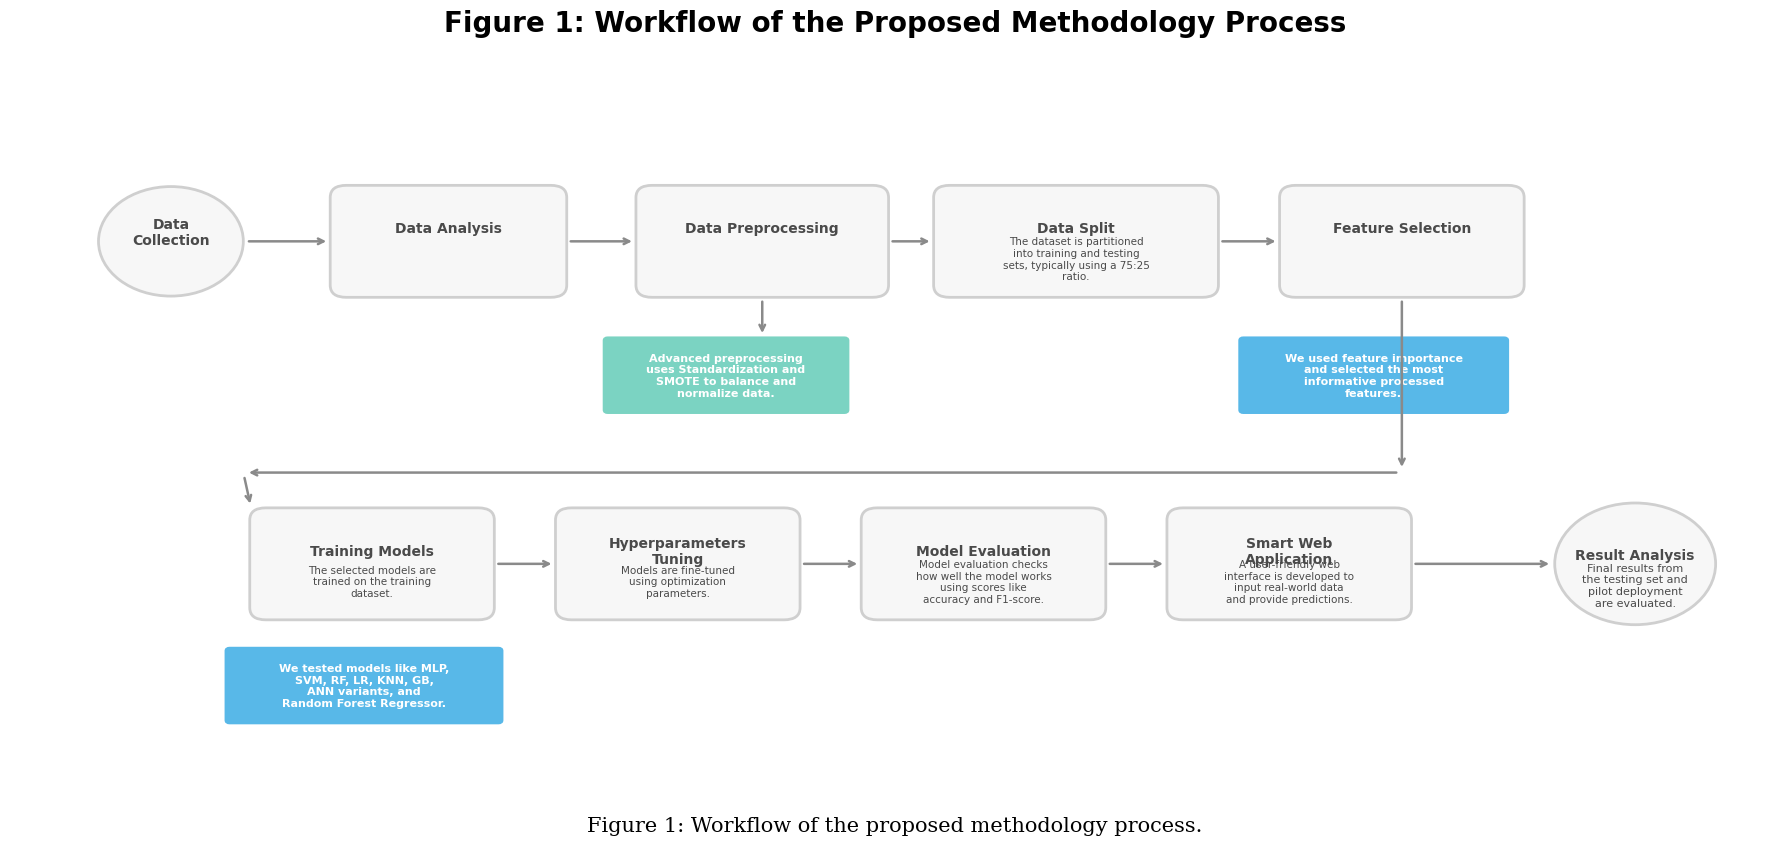

Figure 1 kaydedildi: figures/figure1_workflow_methodology.png


In [73]:
# ==============================
# FIGURE 1: WORKFLOW OF METHODOLOGY PROCESS
# ==============================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

os.makedirs("figures", exist_ok=True)

# ------------------------------
# Figure and axis
# ------------------------------
fig, ax = plt.subplots(figsize=(18, 9))
ax.set_xlim(0, 22)
ax.set_ylim(0, 12)
ax.axis("off")

# ------------------------------
# Colors
# ------------------------------
main_box_color = "#f7f7f7"
main_edge_color = "#cfcfcf"
note_green = "#7bd3c2"
note_blue = "#58b8e8"
arrow_color = "#8a8a8a"
text_color = "#4a4a4a"

# ------------------------------
# Drawing functions
# ------------------------------
def draw_circle(ax, center, radius, title, subtitle=""):
    circle = patches.Circle(
        center,
        radius,
        facecolor=main_box_color,
        edgecolor=main_edge_color,
        linewidth=2
    )
    ax.add_patch(circle)

    ax.text(center[0], center[1] + 0.15, title,
            ha="center", va="center",
            fontsize=10, fontweight="bold", color=text_color)

    if subtitle:
        ax.text(center[0], center[1] - 0.35, subtitle,
                ha="center", va="center",
                fontsize=8, color=text_color, wrap=True)

def draw_rounded_box(ax, x, y, w, h, title, subtitle=""):
    box = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.02,rounding_size=0.2",
        facecolor=main_box_color,
        edgecolor=main_edge_color,
        linewidth=2
    )
    ax.add_patch(box)

    ax.text(x + w/2, y + h*0.62, title,
            ha="center", va="center",
            fontsize=10, fontweight="bold", color=text_color)

    if subtitle:
        ax.text(x + w/2, y + h*0.34, subtitle,
                ha="center", va="center",
                fontsize=7.5, color=text_color, wrap=True)

def draw_note_box(ax, x, y, w, h, text, color):
    note = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.02,rounding_size=0.05",
        facecolor=color,
        edgecolor=color,
        linewidth=1.5
    )
    ax.add_patch(note)

    ax.text(x + w/2, y + h/2, text,
            ha="center", va="center",
            fontsize=8, color="white", fontweight="bold", wrap=True)

def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            color=arrow_color,
            lw=1.8,
            shrinkA=4,
            shrinkB=4
        )
    )

# ------------------------------
# Top row elements
# ------------------------------
draw_circle(ax, (2, 9), 0.9, "Data\nCollection")

draw_rounded_box(ax, 4, 8.1, 2.9, 1.8,
                 "Data Analysis", "")

draw_rounded_box(ax, 7.8, 8.1, 3.1, 1.8,
                 "Data Preprocessing", "")

draw_rounded_box(ax, 11.5, 8.1, 3.5, 1.8,
                 "Data Split",
                 "The dataset is partitioned\ninto training and testing\nsets, typically using a 75:25\nratio.")

draw_rounded_box(ax, 15.8, 8.1, 3.0, 1.8,
                 "Feature Selection", "")

# Note boxes below top row
draw_note_box(ax, 7.4, 6.2, 3.0, 1.2,
              "Advanced preprocessing\nuses Standardization and\nSMOTE to balance and\nnormalize data.",
              note_green)

draw_note_box(ax, 15.3, 6.2, 3.3, 1.2,
              "We used feature importance\nand selected the most\ninformative processed\nfeatures.",
              note_blue)

# ------------------------------
# Bottom row elements
# ------------------------------
draw_rounded_box(ax, 3.0, 2.8, 3.0, 1.8,
                 "Training Models",
                 "The selected models are\ntrained on the training\ndataset.")

draw_rounded_box(ax, 6.8, 2.8, 3.0, 1.8,
                 "Hyperparameters\nTuning",
                 "Models are fine-tuned\nusing optimization\nparameters.")

draw_rounded_box(ax, 10.6, 2.8, 3.0, 1.8,
                 "Model Evaluation",
                 "Model evaluation checks\nhow well the model works\nusing scores like\naccuracy and F1-score.")

draw_rounded_box(ax, 14.4, 2.8, 3.0, 1.8,
                 "Smart Web\nApplication",
                 "A user-friendly web\ninterface is developed to\ninput real-world data\nand provide predictions.")

draw_circle(ax, (20.2, 3.7), 1.0, "Result Analysis",
            "Final results from\nthe testing set and\npilot deployment\nare evaluated.")

# Note box below training models
draw_note_box(ax, 2.7, 1.1, 3.4, 1.2,
              "We tested models like MLP,\nSVM, RF, LR, KNN, GB,\nANN variants, and\nRandom Forest Regressor.",
              note_blue)

# ------------------------------
# Arrows top row
# ------------------------------
draw_arrow(ax, 2.9, 9, 4, 9)
draw_arrow(ax, 6.9, 9, 7.8, 9)
draw_arrow(ax, 10.9, 9, 11.5, 9)
draw_arrow(ax, 15.0, 9, 15.8, 9)

# Arrow down from preprocessing to green note
draw_arrow(ax, 9.35, 8.1, 9.35, 7.4)

# Arrow down-turn to bottom row
draw_arrow(ax, 17.3, 8.1, 17.3, 5.2)
draw_arrow(ax, 17.3, 5.2, 2.9, 5.2)
draw_arrow(ax, 2.9, 5.2, 3.0, 4.6)

# Bottom row arrows
draw_arrow(ax, 6.0, 3.7, 6.8, 3.7)
draw_arrow(ax, 9.8, 3.7, 10.6, 3.7)
draw_arrow(ax, 13.6, 3.7, 14.4, 3.7)
draw_arrow(ax, 17.4, 3.7, 19.2, 3.7)

# ------------------------------
# Title and caption
# ------------------------------
plt.title(
    "Figure 1: Workflow of the Proposed Methodology Process",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.figtext(
    0.5, 0.02,
    "Figure 1: Workflow of the proposed methodology process.",
    ha="center",
    fontsize=15,
    fontfamily="serif"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

# Save
save_path = "figures/figure1_workflow_methodology.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure 1 kaydedildi: {save_path}")

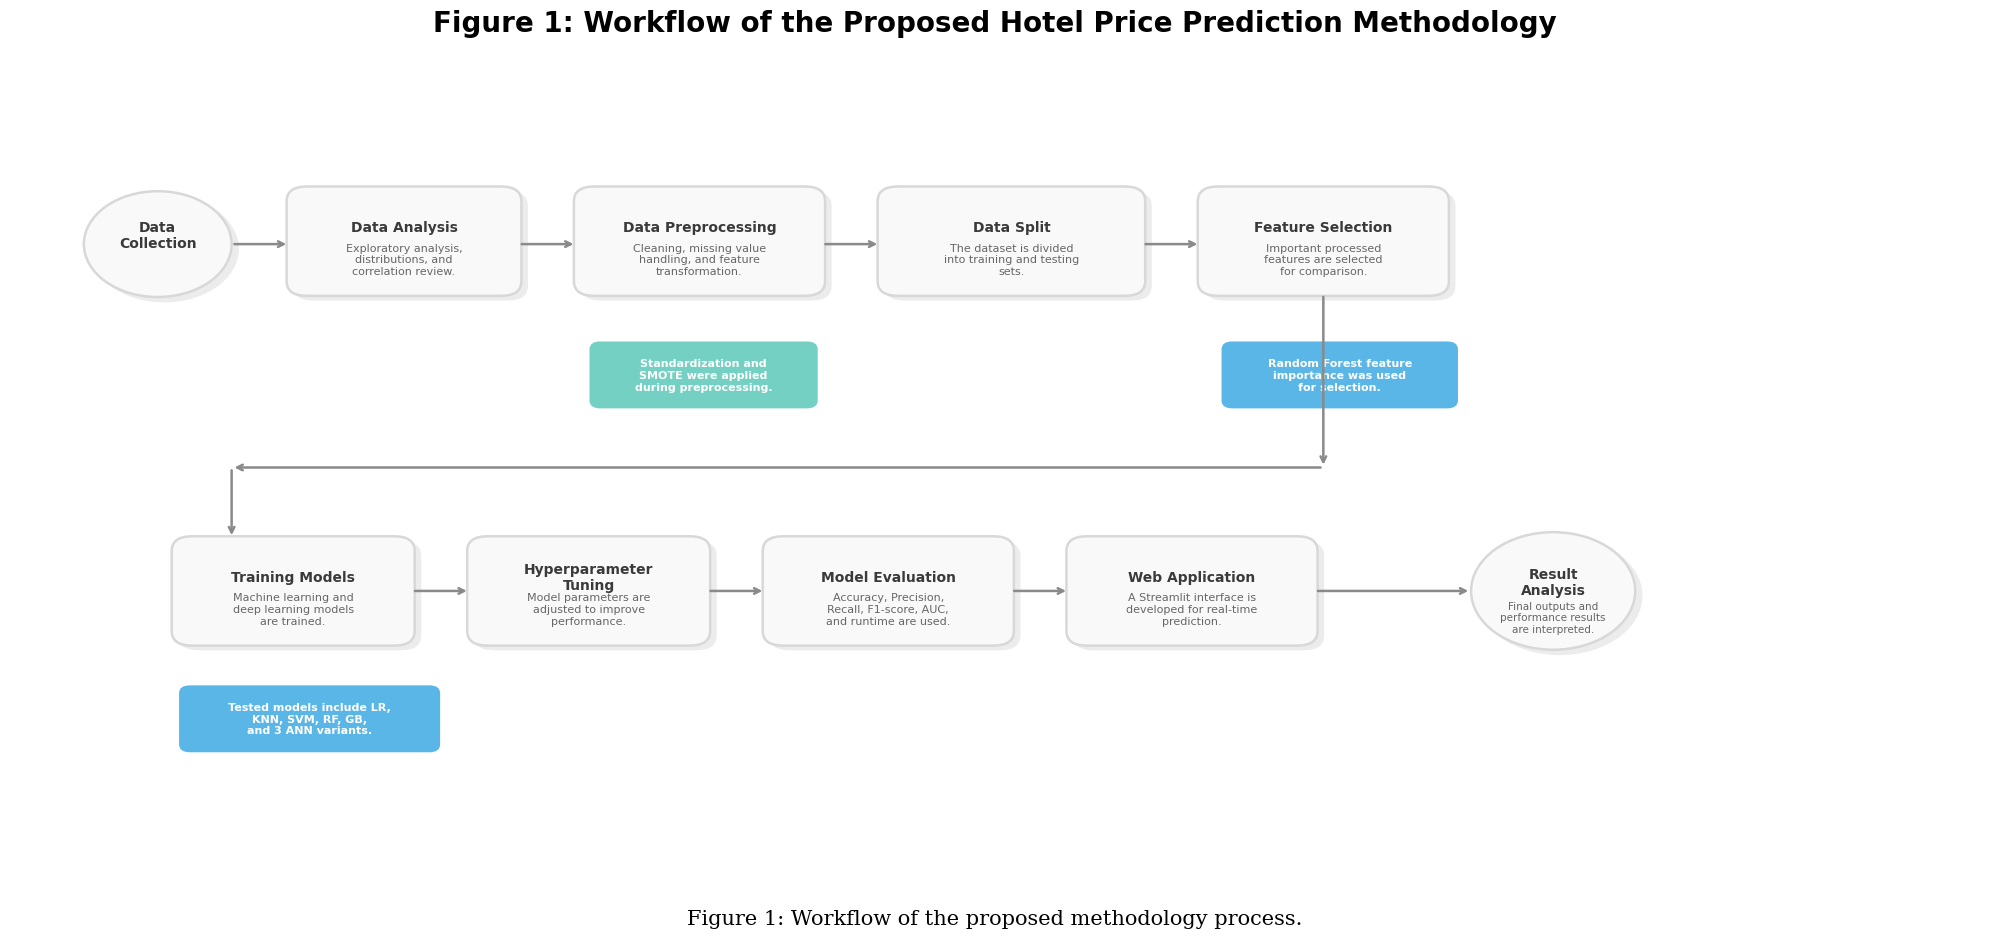

Figure 1 kaydedildi: figures/figure1_workflow_stylish.png


In [74]:
# ==============================
# FIGURE 1: STYLISH WORKFLOW DIAGRAM
# ==============================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

os.makedirs("figures", exist_ok=True)

# ------------------------------
# Figure setup
# ------------------------------
fig, ax = plt.subplots(figsize=(20, 10))
ax.set_xlim(0, 24)
ax.set_ylim(0, 14)
ax.axis("off")

# ------------------------------
# Colors
# ------------------------------
bg_box = "#F9F9F9"
border_box = "#D8D8D8"
shadow_color = "#ECECEC"
arrow_color = "#8A8A8A"
title_color = "#3A3A3A"
note_green = "#73D0C2"
note_blue = "#5AB6E6"

# ------------------------------
# Helper functions
# ------------------------------
def draw_shadow_box(ax, x, y, w, h, title, subtitle=""):
    # shadow
    shadow = patches.FancyBboxPatch(
        (x + 0.08, y - 0.08), w, h,
        boxstyle="round,pad=0.03,rounding_size=0.25",
        facecolor=shadow_color,
        edgecolor=shadow_color,
        linewidth=0
    )
    ax.add_patch(shadow)

    # main box
    box = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.03,rounding_size=0.25",
        facecolor=bg_box,
        edgecolor=border_box,
        linewidth=1.8
    )
    ax.add_patch(box)

    ax.text(
        x + w/2, y + h*0.63, title,
        ha="center", va="center",
        fontsize=10, fontweight="bold", color=title_color
    )

    if subtitle:
        ax.text(
            x + w/2, y + h*0.33, subtitle,
            ha="center", va="center",
            fontsize=8, color="#666666", wrap=True
        )

def draw_shadow_circle(ax, cx, cy, r, title, subtitle=""):
    # shadow
    shadow = patches.Circle((cx + 0.08, cy - 0.08), r,
                            facecolor=shadow_color, edgecolor=shadow_color)
    ax.add_patch(shadow)

    # main circle
    circle = patches.Circle((cx, cy), r,
                            facecolor=bg_box, edgecolor=border_box, linewidth=1.8)
    ax.add_patch(circle)

    ax.text(cx, cy + 0.15, title,
            ha="center", va="center",
            fontsize=10, fontweight="bold", color=title_color)

    if subtitle:
        ax.text(cx, cy - 0.45, subtitle,
                ha="center", va="center",
                fontsize=7.5, color="#666666", wrap=True)

def draw_note(ax, x, y, w, h, text, color):
    note = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.03,rounding_size=0.12",
        facecolor=color,
        edgecolor=color,
        linewidth=1.2
    )
    ax.add_patch(note)

    ax.text(
        x + w/2, y + h/2, text,
        ha="center", va="center",
        fontsize=8, color="white", fontweight="bold", wrap=True
    )

def arrow(ax, x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.8,
            color=arrow_color,
            shrinkA=2,
            shrinkB=2
        )
    )

# ------------------------------
# Top row
# ------------------------------
draw_shadow_circle(ax, 1.8, 10.8, 0.9, "Data\nCollection")

draw_shadow_box(ax, 3.4, 9.95, 2.8, 1.8,
                "Data Analysis",
                "Exploratory analysis,\ndistributions, and\ncorrelation review.")

draw_shadow_box(ax, 6.9, 9.95, 3.0, 1.8,
                "Data Preprocessing",
                "Cleaning, missing value\nhandling, and feature\ntransformation.")

draw_shadow_box(ax, 10.6, 9.95, 3.2, 1.8,
                "Data Split",
                "The dataset is divided\ninto training and testing\nsets.")

draw_shadow_box(ax, 14.5, 9.95, 3.0, 1.8,
                "Feature Selection",
                "Important processed\nfeatures are selected\nfor comparison.")

# notes under top row
draw_note(ax, 7.1, 8.05, 2.7, 1.05,
          "Standardization and\nSMOTE were applied\nduring preprocessing.",
          note_green)

draw_note(ax, 14.8, 8.05, 2.8, 1.05,
          "Random Forest feature\nimportance was used\nfor selection.",
          note_blue)

# arrows top row
arrow(ax, 2.7, 10.8, 3.4, 10.8)
arrow(ax, 6.2, 10.8, 6.9, 10.8)
arrow(ax, 9.9, 10.8, 10.6, 10.8)
arrow(ax, 13.8, 10.8, 14.5, 10.8)

# arrow down from feature selection to bottom path
arrow(ax, 16.0, 9.95, 16.0, 7.0)
arrow(ax, 16.0, 7.0, 2.7, 7.0)
arrow(ax, 2.7, 7.0, 2.7, 5.8)

# ------------------------------
# Bottom row
# ------------------------------
draw_shadow_box(ax, 2.0, 4.0, 2.9, 1.8,
                "Training Models",
                "Machine learning and\ndeep learning models\nare trained.")

draw_shadow_box(ax, 5.6, 4.0, 2.9, 1.8,
                "Hyperparameter\nTuning",
                "Model parameters are\nadjusted to improve\nperformance.")

draw_shadow_box(ax, 9.2, 4.0, 3.0, 1.8,
                "Model Evaluation",
                "Accuracy, Precision,\nRecall, F1-score, AUC,\nand runtime are used.")

draw_shadow_box(ax, 12.9, 4.0, 3.0, 1.8,
                "Web Application",
                "A Streamlit interface is\ndeveloped for real-time\nprediction.")

draw_shadow_circle(ax, 18.8, 4.9, 1.0, "Result\nAnalysis",
                   "Final outputs and\nperformance results\nare interpreted.")

# bottom note
draw_note(ax, 2.1, 2.2, 3.1, 1.05,
          "Tested models include LR,\nKNN, SVM, RF, GB,\nand 3 ANN variants.",
          note_blue)

# arrows bottom row
arrow(ax, 4.9, 4.9, 5.6, 4.9)
arrow(ax, 8.5, 4.9, 9.2, 4.9)
arrow(ax, 12.2, 4.9, 12.9, 4.9)
arrow(ax, 15.9, 4.9, 17.8, 4.9)

# ------------------------------
# Title and caption
# ------------------------------
plt.title(
    "Figure 1: Workflow of the Proposed Hotel Price Prediction Methodology",
    fontsize=20,
    fontweight="bold",
    pad=18
)

plt.figtext(
    0.5, 0.02,
    "Figure 1: Workflow of the proposed methodology process.",
    ha="center",
    fontsize=15,
    fontfamily="serif"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

save_path = "figures/figure1_workflow_stylish.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure 1 kaydedildi: {save_path}")

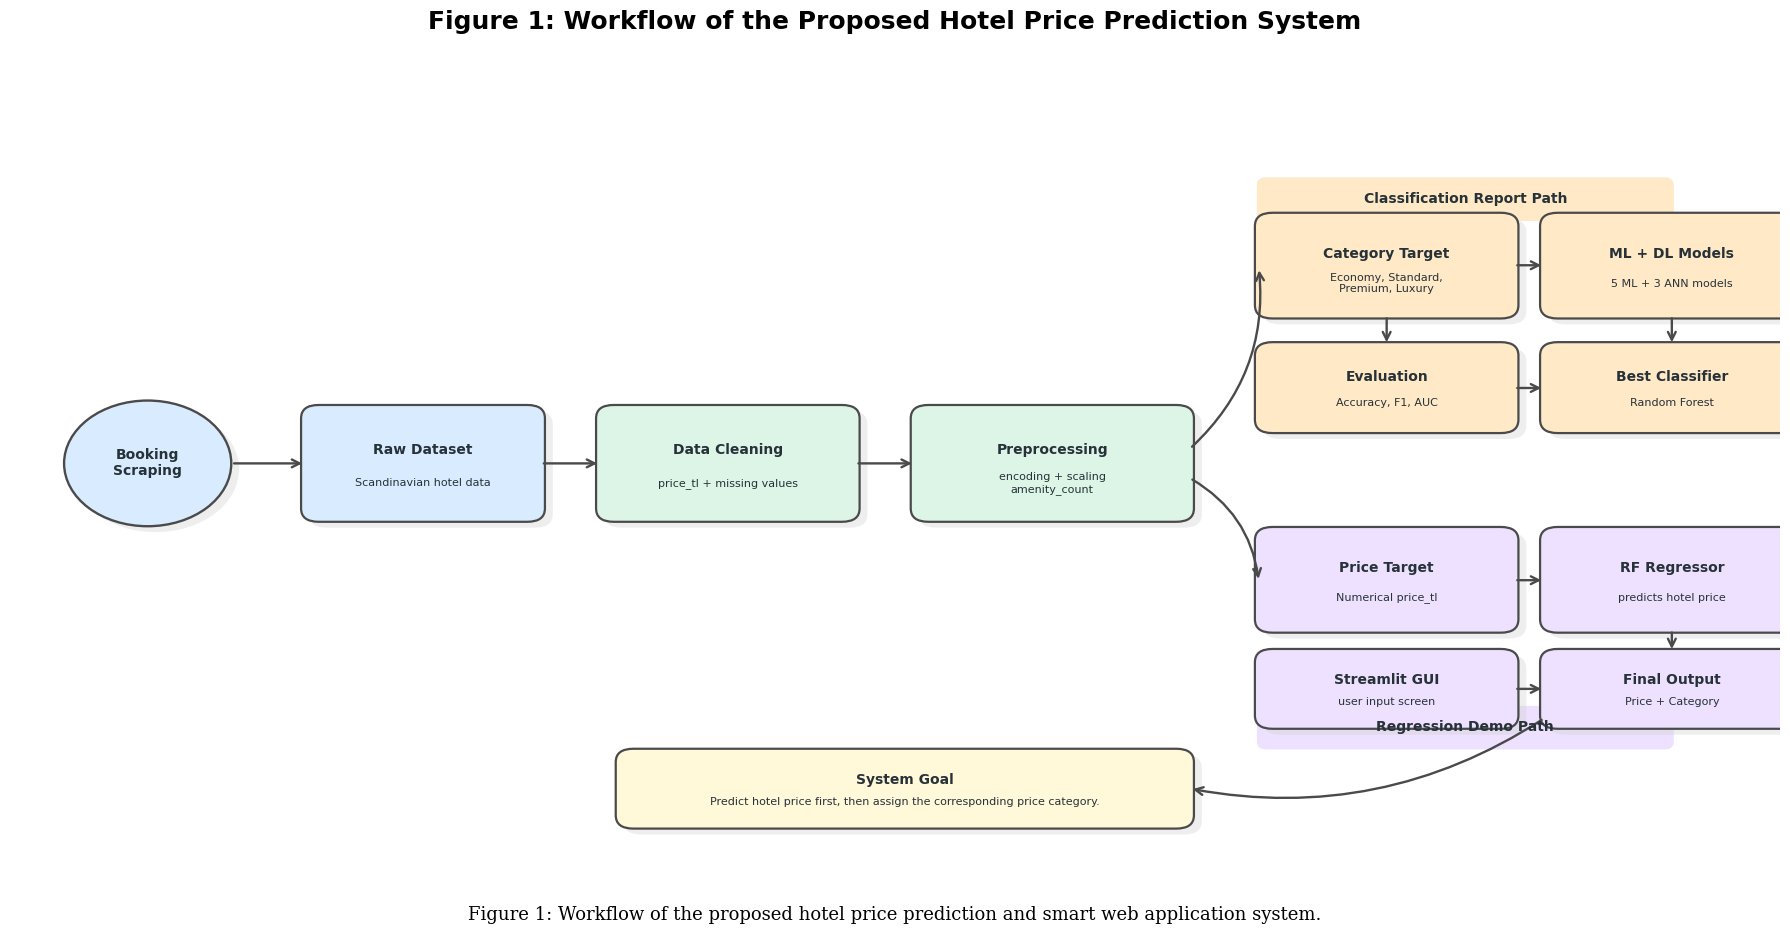

Figure 1 kaydedildi: figures/figure1_workflow_two_branch.png


In [75]:
# ==============================
# FIGURE 1: TWO-BRANCH WORKFLOW DIAGRAM
# Classification + Regression Web App Pipeline
# ==============================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch
import os

os.makedirs("figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(18, 10))
ax.set_xlim(0, 18)
ax.set_ylim(0, 11)
ax.axis("off")

# ------------------------------
# Colors
# ------------------------------
dark = "#263238"
blue = "#D9ECFF"
green = "#DDF5E7"
orange = "#FFE9C7"
purple = "#EDE1FF"
gray = "#F4F4F4"
edge = "#4A4A4A"

# ------------------------------
# Helper functions
# ------------------------------
def box(x, y, w, h, title, subtitle="", color=gray):
    shadow = patches.FancyBboxPatch(
        (x + 0.08, y - 0.08), w, h,
        boxstyle="round,pad=0.04,rounding_size=0.18",
        linewidth=0,
        facecolor="#D0D0D0",
        alpha=0.35
    )
    ax.add_patch(shadow)

    rect = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.04,rounding_size=0.18",
        linewidth=1.6,
        edgecolor=edge,
        facecolor=color
    )
    ax.add_patch(rect)

    ax.text(
        x + w/2, y + h*0.62,
        title,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=dark
    )

    if subtitle:
        ax.text(
            x + w/2, y + h*0.32,
            subtitle,
            ha="center",
            va="center",
            fontsize=8,
            color=dark
        )

def circle(x, y, r, title, color):
    shadow = patches.Circle(
        (x + 0.08, y - 0.08), r,
        linewidth=0,
        facecolor="#D0D0D0",
        alpha=0.35
    )
    ax.add_patch(shadow)

    c = patches.Circle(
        (x, y), r,
        linewidth=1.7,
        edgecolor=edge,
        facecolor=color
    )
    ax.add_patch(c)

    ax.text(
        x, y,
        title,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=dark
    )

def arrow(x1, y1, x2, y2, curve=0.0):
    arr = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        connectionstyle=f"arc3,rad={curve}",
        arrowstyle="->",
        mutation_scale=14,
        linewidth=1.7,
        color=edge
    )
    ax.add_patch(arr)

def lane_label(x, y, text, color):
    label = patches.FancyBboxPatch(
        (x, y), 4.2, 0.55,
        boxstyle="round,pad=0.02,rounding_size=0.1",
        linewidth=0,
        facecolor=color
    )
    ax.add_patch(label)

    ax.text(
        x + 2.1, y + 0.28,
        text,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=dark
    )

# ------------------------------
# Main input and preprocessing
# ------------------------------
circle(1.4, 5.5, 0.85, "Booking\nScraping", blue)

box(
    3.0, 4.75, 2.4, 1.5,
    "Raw Dataset",
    "Scandinavian hotel data",
    blue
)

box(
    6.0, 4.75, 2.6, 1.5,
    "Data Cleaning",
    "price_tl + missing values",
    green
)

box(
    9.2, 4.75, 2.8, 1.5,
    "Preprocessing",
    "encoding + scaling\namenity_count",
    green
)

# Arrows main
arrow(2.25, 5.5, 3.0, 5.5)
arrow(5.4, 5.5, 6.0, 5.5)
arrow(8.6, 5.5, 9.2, 5.5)

# ------------------------------
# Branch labels
# ------------------------------
lane_label(12.7, 8.8, "Classification Report Path", orange)
lane_label(12.7, 1.65, "Regression Demo Path", purple)

# ------------------------------
# Upper branch: classification
# ------------------------------
box(
    12.7, 7.5, 2.6, 1.35,
    "Category Target",
    "Economy, Standard,\nPremium, Luxury",
    orange
)

box(
    15.6, 7.5, 2.6, 1.35,
    "ML + DL Models",
    "5 ML + 3 ANN models",
    orange
)

box(
    12.7, 5.95, 2.6, 1.15,
    "Evaluation",
    "Accuracy, F1, AUC",
    orange
)

box(
    15.6, 5.95, 2.6, 1.15,
    "Best Classifier",
    "Random Forest",
    orange
)

# ------------------------------
# Lower branch: regression + app
# ------------------------------
box(
    12.7, 3.25, 2.6, 1.35,
    "Price Target",
    "Numerical price_tl",
    purple
)

box(
    15.6, 3.25, 2.6, 1.35,
    "RF Regressor",
    "predicts hotel price",
    purple
)

box(
    12.7, 1.95, 2.6, 1.0,
    "Streamlit GUI",
    "user input screen",
    purple
)

box(
    15.6, 1.95, 2.6, 1.0,
    "Final Output",
    "Price + Category",
    purple
)

# Branch arrows
arrow(12.0, 5.7, 12.7, 8.15, curve=0.25)
arrow(12.0, 5.3, 12.7, 3.9, curve=-0.25)

# Upper arrows
arrow(15.3, 8.18, 15.6, 8.18)
arrow(14.0, 7.5, 14.0, 7.1)
arrow(15.3, 6.52, 15.6, 6.52)
arrow(16.9, 7.5, 16.9, 7.1)

# Lower arrows
arrow(15.3, 3.92, 15.6, 3.92)
arrow(16.9, 3.25, 16.9, 2.95)
arrow(15.3, 2.45, 15.6, 2.45)

# ------------------------------
# Result summary callout
# ------------------------------
box(
    6.2, 0.6, 5.8, 1.0,
    "System Goal",
    "Predict hotel price first, then assign the corresponding price category.",
    "#FFF8D9"
)

arrow(15.6, 2.05, 12.0, 1.1, curve=-0.2)

# ------------------------------
# Title and caption
# ------------------------------
plt.title(
    "Figure 1: Workflow of the Proposed Hotel Price Prediction System",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.figtext(
    0.5,
    0.025,
    "Figure 1: Workflow of the proposed hotel price prediction and smart web application system.",
    ha="center",
    fontsize=13,
    fontfamily="serif"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])

save_path = "figures/figure1_workflow_two_branch.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure 1 kaydedildi:", save_path)

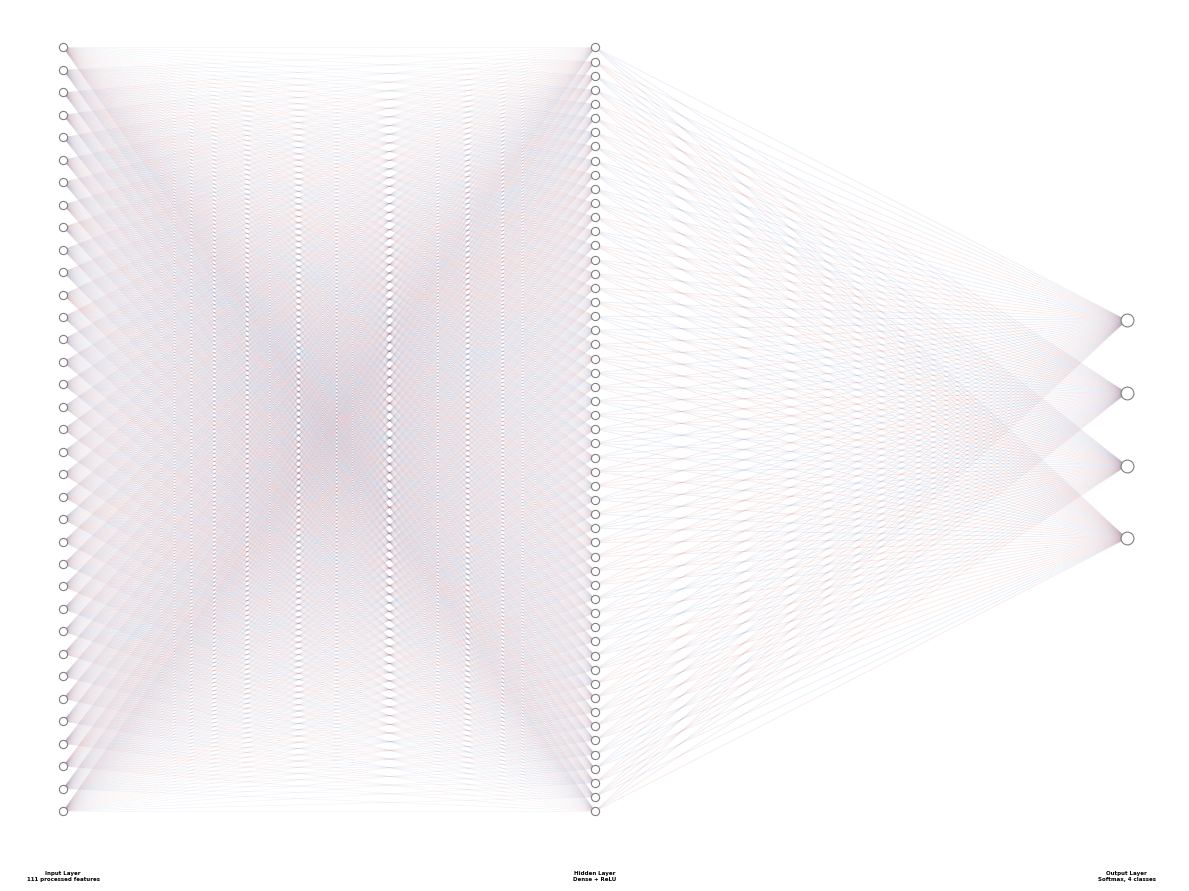

Figure saved as: figures/figure10_mlp_architecture.png


In [76]:
# ==============================
# FIGURE 10: MULTI-LAYER PERCEPTRON ARCHITECTURE
# Hotel Price Category Classification
# ==============================

import matplotlib.pyplot as plt
import numpy as np
import os
import random

os.makedirs("figures", exist_ok=True)

# ==============================
# 1. ARCHITECTURE SETTINGS
# ==============================

try:
    input_feature_count = X_train_processed.shape[1]
except:
    input_feature_count = 111

input_nodes_visible = 35
hidden_nodes_visible = 55
output_nodes_visible = 4

# ==============================
# 2. NODE POSITIONS
# ==============================

def layer_positions(x, n_nodes, y_min=0.08, y_max=0.92):
    y_positions = np.linspace(y_min, y_max, n_nodes)
    x_positions = np.full(n_nodes, x)
    return list(zip(x_positions, y_positions))

input_layer = layer_positions(0.15, input_nodes_visible)
hidden_layer = layer_positions(0.50, hidden_nodes_visible)
output_layer = layer_positions(0.85, output_nodes_visible, y_min=0.38, y_max=0.62)

# ==============================
# 3. DRAW NETWORK
# ==============================

plt.figure(figsize=(12, 10))
ax = plt.gca()
ax.axis("off")

# Connections: Input -> Hidden
for x1, y1 in input_layer:
    for x2, y2 in hidden_layer:
        color = random.choice(["#4C72B0", "#C44E52"])
        ax.plot(
            [x1, x2],
            [y1, y2],
            color=color,
            alpha=0.08,
            linewidth=0.45
        )

# Connections: Hidden -> Output
for x1, y1 in hidden_layer:
    for x2, y2 in output_layer:
        color = random.choice(["#4C72B0", "#C44E52"])
        ax.plot(
            [x1, x2],
            [y1, y2],
            color=color,
            alpha=0.12,
            linewidth=0.6
        )

# Draw nodes
def draw_nodes(layer, size=45):
    for x, y in layer:
        ax.scatter(
            x,
            y,
            s=size,
            facecolor="white",
            edgecolor="gray",
            linewidth=0.8,
            zorder=3
        )

draw_nodes(input_layer, size=35)
draw_nodes(hidden_layer, size=35)
draw_nodes(output_layer, size=85)

# Layer labels
ax.text(
    0.15,
    0.015,
    f"Input Layer\n{input_feature_count} processed features",
    ha="center",
    va="top",
    fontsize=4,
    fontweight="bold"
)

ax.text(
    0.50,
    0.015,
    "Hidden Layer\nDense + ReLU",
    ha="center",
    va="top",
    fontsize=4,
    fontweight="bold"
)

ax.text(
    0.85,
    0.015,
    "Output Layer\nSoftmax, 4 classes",
    ha="center",
    va="top",
    fontsize=4,
    fontweight="bold"
)




plt.tight_layout(rect=[0, 0.05, 1, 0.95])

save_path = "figures/figure10_mlp_architecture.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved as:", save_path)